In [1]:
# ============================================================================
# CELL 1 — ENVIRONMENT SETUP  (safe to re-run; run this first in EVERY session)
# Mounts Google Drive, installs pinned dependencies, seeds everything.
# ============================================================================
import os, sys, gc, json, time, math, random, shutil, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

# ---- 1. Google Drive (persistent storage that survives Colab disconnects) ----
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    DRIVE_ROOT = Path("/content/drive/MyDrive/PGP-YOLO")
    LOCAL_ROOT = Path("/content")
else:  # local execution fallback (e.g. a workstation) — everything still works
    DRIVE_ROOT = Path.home() / "PGP-YOLO"
    LOCAL_ROOT = Path.cwd()

for sub in ["data", "runs", "results", "figures", "tables", "env", "prior"]:
    (DRIVE_ROOT / sub).mkdir(parents=True, exist_ok=True)
print(f"Persistent project root : {DRIVE_ROOT}")
print(f"Local (fast) workspace  : {LOCAL_ROOT}")

# ---- 2. Pinned installs (pin = reproducibility; custom modules are tested on 8.3.107) ----
%pip install -q "ultralytics==8.3.107" kagglehub

import numpy as np
import torch
import ultralytics
from ultralytics import YOLO

# ---- 3. GPU check ----
if torch.cuda.is_available():
    gpu = torch.cuda.get_device_name(0)
    vram = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f"GPU: {gpu} ({vram:.1f} GB)")
else:
    gpu = "CPU"
    print("*" * 70)
    print("WARNING: no GPU detected. In Colab: Runtime > Change runtime type > T4 GPU")
    print("*" * 70)

# ---- 4. Global seeding (Ultralytics also receives seed= in every train call) ----
SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print(f"ultralytics {ultralytics.__version__} | torch {torch.__version__} | "
      f"python {sys.version.split()[0]} | numpy {np.__version__}")

Mounted at /content/drive
Persistent project root : /content/drive/MyDrive/PGP-YOLO
Local (fast) workspace  : /content
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 974.5/974.5 kB 49.8 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
GPU: Tesla T4 (15.6 GB)
ultralytics 8.3.107 | torch 2.11.0+cu128 | python 3.12.13 | numpy 2.0.2


In [2]:
# ============================================================================
# CELL 2 — EXPERIMENT CONFIGURATION (single source of truth for the paper)
# ============================================================================
class CFG:
    # ---------------- model / training ----------------
    SCALE      = "s"      # 's' = journal-grade headline results; 'n' = ~2.5x faster
    EPOCHS     = 80       # identical for every run (fair comparison)
    IMGSZ      = 640
    BATCH      = 16       # fits T4 16GB for the 's' scale at 640px
    PATIENCE   = 25       # early stopping patience (epochs)
    WORKERS    = 2        # Colab free has 2 vCPUs
    SEED       = 0

    FAST_MODE  = False    # True -> SCALE='n', EPOCHS=50 (quick full pipeline test)
    RUN_RTDETR = False    # optional transformer baseline (heavy: ~2x train time)
    RUN_BDD = True          # ADVISOR #1: external validation on BDD100K (2nd driving
                            # dataset, YOLO-detection format). Prep via cell 3b, then
                            # 'Run all'. Adds the budget-confound protocol (base +
                            # geo-ft + std-ft for yolo11s & yolov8s + SCRATCH_SEEDS)
                            # on a BDD100K subset as bdd_* runs. ~15-20 GPU-h.
    SKIP       = []       # e.g. ["yolov5su"] to skip a baseline you don't need
    FORCE_REEVAL = False  # re-run evaluation even if cached JSON exists

    # ---------------- dataset ----------------
    KAGGLE_DATASET = "klemenko/kitti-dataset"   # canonical KITTI mirror on Kaggle
    # ADVISOR #1 - external validation on BDD100K (2nd driving dataset), downloaded
    # via the Kaggle API to local disk (cell 3b). Use a PRE-CONVERTED BDD100K-YOLO
    # mirror: images + YOLO .txt labels (+ an optional data.yaml). The prep cell
    # auto-detects the layout and class names, so no fragile polygon conversion.
    BDD_KAGGLE = "a7madmostafa/bdd100k-yolo"        # verified: ~6GB, 70k/10k, 10 cls
    BDD_KAGGLE_ALT = ["marquis03/bdd100k",          # fallbacks if the above 404s;
                      "alkanet88/bdd100k-yol-format"]   # cell 3b tries each in order
    EXTVAL_MAX_TRAIN = 6000     # subset the 2nd dataset for free-Colab feasibility
    EXTVAL_MAX_VAL   = 1500     # cap the val split too (keeps the Drive cache small)
    # External validation (#1) needs the budget-confound finding to REPLICATE, not
    # the full from-scratch rigor of #2 (that lives on KITTI). So BDD shares ONE
    # seed-0 base per architecture and varies only the 25-epoch stage-2 across these
    # seeds -> n=3 geo-vs-std pairs for the T7 statistics at ~half the GPU cost.
    EXTVAL_SEEDS     = [1, 2]
    # class names come from the dataset's own data.yaml; if absent, the prep cell
    # infers nc from the label files and uses generic names (mAP is over the same
    # indices either way - external validation compares Geo-FT vs Std-FT WITHIN BDD).
    TRAIN_FRACTION = 0.8                        # -> 5,985 / 1,496 (standard split)
    CLASSES    = ["Car", "Van", "Truck", "Pedestrian", "Cyclist", "Tram"]
    # KITTI raw type -> our class id. Person_sitting merged into Pedestrian
    # (common practice); Misc & DontCare skipped (documented limitation).
    KITTI_MAP  = {"Car": 0, "Van": 1, "Truck": 2,
                  "Pedestrian": 3, "Person_sitting": 3, "Cyclist": 4, "Tram": 5}
    JPEG_QUALITY = 92     # re-encode PNG->JPEG once (5x smaller Drive cache, no visible loss)

    # ---------------- PGP method hyper-parameters ----------------
    PGSA_GROUPS   = 8     # channel groups per row-gate
    PGSA_HIDDEN   = 32
    PGCSF_HIDDEN  = 16
    PACP_FRACTION = 0.30  # fraction of train images that get a PA-CP augmented copy
    PACP_MAX_PASTE= 3     # max pasted instances per augmented image
    PACP_CLASSES  = [3, 4]           # Pedestrian, Cyclist (the rare classes)
    PACP_MIN_SRC_H= 0.07             # min normalized height of source crops
    PRIOR_BINS    = 24               # y-bins for the perspective prior

    # ---------------- v2: geometry-consistent fine-tuning stage ----------------
    # WHY: mosaic augmentation (mosaic=1.0 for the first 70/80 epochs) builds
    # 4-image collages that DESTROY the row<->scale correlation, so the zero-init
    # PGP gates stay inert (F17 showed gains ~1.000). Stage-2 fine-tunes the
    # already-trained checkpoints for GEO_EPOCHS with geometry-consistent
    # augmentation (no mosaic, mild jitter) - applied IDENTICALLY to the baseline
    # (yolo11s_geo) and the proposed model (pgp_v2), so the comparison stays fair.
    GEO_EPOCHS    = 25
    GEO_OVERRIDES = dict(mosaic=0.0, scale=0.2, translate=0.05, mixup=0.0,
                         copy_paste=0.0, optimizer="SGD", lr0=0.002, lrf=0.05,
                         warmup_epochs=1.0, patience=15)
    # v2.2 CONTROL: identical budget/LR/optimizer but STANDARD augmentation
    # (mosaic stays on the whole stage: close_mosaic=0). Isolates the geometry
    # effect from the "you just trained 25 more epochs" objection - the paper's
    # key control (Table T6 / Figure F19).
    STD_OVERRIDES = dict(mosaic=1.0, scale=0.5, translate=0.1, close_mosaic=0,
                         mixup=0.0, copy_paste=0.0, optimizer="SGD", lr0=0.002,
                         lrf=0.05, warmup_epochs=1.0, patience=15)
    # robustness runs for the HEADLINE claims (mean+-std): [1, 2] adds two extra
    # stage-2 seeds for the 2x2 (arch x recipe) matrix - yolo11s & yolov8s, each
    # geo-ft & std-ft = 8 extra fine-tunes (~9 GPU-h). With seed 0 already done,
    # every headline delta becomes mean+-std over n=3. REQUIRED before submission:
    # the paper's null claims ("injection deltas < noise") need an estimate of
    # that noise. Runs resume/skip like all others - just 'Run all' each session.
    EXTRA_SEEDS   = [1, 2]
    # ADVISOR REQUIREMENT #2 - FULL multi-seed FROM SCRATCH. EXTRA_SEEDS above only
    # varies the 25-epoch stage-2 (shared 80-epoch checkpoint), so its SD is a lower
    # bound on true variance. SCRATCH_SEEDS re-trains the 80-epoch BASE from a fresh
    # random init for each listed seed (and re-derives its geo-ft/std-ft children),
    # giving independent end-to-end replicates for honest CIs + significance tests.
    # Cost: len(SCRATCH_SEEDS) x |SCRATCH_ARCHS| x (80ep + 2x25ep) ~= 7.5 GPU-h each.
    # Keep [] until ready; [1, 2] -> n=3 with seed 0. Only the two headline
    # architectures are re-seeded by default to stay within a free-Colab budget.
    SCRATCH_SEEDS = [1, 2]        # from-scratch replicates seeds 1,2 (+ seed 0 -> n=3)
    SCRATCH_ARCHS = ["yolo11", "yolov8"]

if CFG.FAST_MODE:
    CFG.SCALE, CFG.EPOCHS = "n", 50
assert CFG.SCALE in ("n", "s"), "Colab-free notebook supports n/s scales"

# ---------------- derived paths ----------------
DATA_LOCAL   = LOCAL_ROOT / "kitti_yolo"            # fast local disk (wiped on disconnect)
DATA_CACHE   = DRIVE_ROOT / "data" / "kitti_yolo.zip"       # survives disconnects
PACP_CACHE   = DRIVE_ROOT / "data" / "kitti_pacp.zip"
KITTI_YAML   = DATA_LOCAL / "kitti.yaml"            # baseline + ablation A1/A2 data
PACP_YAML    = DATA_LOCAL / "kitti_pacp.yaml"       # proposed (adds PA-CP images)
BDD_YAML     = LOCAL_ROOT / "bdd_yolo" / "bdd.yaml"        # external validation (#1)
PRIOR_JSON   = DRIVE_ROOT / "prior" / "perspective_prior.json"
FIG_DIR      = DRIVE_ROOT / "figures"
TAB_DIR      = DRIVE_ROOT / "tables"
RES_DIR      = DRIVE_ROOT / "results"
RUNS_DIR     = DRIVE_ROOT / "runs"

# ---------------- experiment registry ----------------------------------------
# rows: (name, weights_source, data_yaml, train_overrides)
#   weights_source "PARENT:<exp>" = start from that experiment's best.pt
def experiment_matrix():
    s = CFG.SCALE
    GEO = dict(CFG.GEO_OVERRIDES, epochs=CFG.GEO_EPOCHS)
    E = [
        (f"yolov5{s}u",  f"yolov5{s}u.pt",        KITTI_YAML, None),  # baseline B1
        (f"yolov8{s}",   f"yolov8{s}.pt",         KITTI_YAML, None),  # baseline B2
        (f"yolov10{s}",  f"yolov10{s}.pt",        KITTI_YAML, None),  # baseline B3
        (f"yolo11{s}",   f"yolo11{s}.pt",         KITTI_YAML, None),  # baseline B4 = A0
        ("pgp_A1_pgsa",       "pgp_a1_init.pt",   KITTI_YAML, None),  # A1: +PGSA
        ("pgp_A2_pgsa_pgcsf", "pgp_a2_init.pt",   KITTI_YAML, None),  # A2: +PGSA+PGCSF
        ("pgp_yolo_full",     "pgp_a2_init.pt",   PACP_YAML,  None),  # v1: A2 + PA-CP
        # ---- v2: geometry-consistent fine-tuning (identical recipe for both) ----
        (f"yolo11{s}_geo", f"PARENT:yolo11{s}",     KITTI_YAML, GEO),
        ("pgp_v2",         "PARENT:pgp_yolo_full",  PACP_YAML,  GEO),
        # ---- v2.1 FAIRNESS ROUND: every baseline gets the identical stage-2
        #      budget (a reviewer will reject 105-epoch ours vs 80-epoch theirs),
        #      plus the cleanest module variant: PGSA-only + geo fine-tune
        #      (v2 carried PGCSF and PA-CP, which the v1/v2 ablations showed to
        #      hurt small objects and Pedestrian - pgp_a1_geo drops both).
        (f"yolov5{s}u_geo", f"PARENT:yolov5{s}u",   KITTI_YAML, GEO),
        (f"yolov8{s}_geo",  f"PARENT:yolov8{s}",    KITTI_YAML, GEO),
        (f"yolov10{s}_geo", f"PARENT:yolov10{s}",   KITTI_YAML, GEO),
        ("pgp_a1_geo",      "PARENT:pgp_A1_pgsa",   KITTI_YAML, GEO),
        # ---- v2.2: equal-budget STANDARD-aug controls (the decisive control
        #      for the recipe claim: geometry consistency vs simply more epochs)
        (f"yolo11{s}_stdft", f"PARENT:yolo11{s}",   KITTI_YAML,
         dict(CFG.STD_OVERRIDES, epochs=CFG.GEO_EPOCHS)),
        (f"yolov8{s}_stdft", f"PARENT:yolov8{s}",   KITTI_YAML,
         dict(CFG.STD_OVERRIDES, epochs=CFG.GEO_EPOCHS)),
        # complete the 4-architecture control matrix for Table T6 / Figure F19
        (f"yolov5{s}u_stdft", f"PARENT:yolov5{s}u", KITTI_YAML,
         dict(CFG.STD_OVERRIDES, epochs=CFG.GEO_EPOCHS)),
        (f"yolov10{s}_stdft", f"PARENT:yolov10{s}", KITTI_YAML,
         dict(CFG.STD_OVERRIDES, epochs=CFG.GEO_EPOCHS)),
    ]
    STD = dict(CFG.STD_OVERRIDES, epochs=CFG.GEO_EPOCHS)
    # (a) stage-2-only seeds (shared 80-ep checkpoint). Disabled when SCRATCH_SEEDS
    #     is active, since that produces the same run names from independent bases.
    for sd in (CFG.EXTRA_SEEDS if not CFG.SCRATCH_SEEDS else []):
        for base, parent, dy, ov in [
                (f"yolo11{s}_geo",   f"PARENT:yolo11{s}",  KITTI_YAML, GEO),
                (f"yolo11{s}_stdft", f"PARENT:yolo11{s}",  KITTI_YAML, STD),
                (f"yolov8{s}_geo",   f"PARENT:yolov8{s}",  KITTI_YAML, GEO),
                (f"yolov8{s}_stdft", f"PARENT:yolov8{s}",  KITTI_YAML, STD)]:
            E.append((f"{base}_s{sd}", parent, dy, dict(ov, seed=sd)))
    # (b) ADVISOR #2: FULL train-from-scratch replicates. Each seed re-trains the
    #     80-ep base (fresh random state) and re-derives its geo-ft / std-ft
    #     children, so the seed SD is an unconditional end-to-end estimate.
    for sd in CFG.SCRATCH_SEEDS:
        for arch in CFG.SCRATCH_ARCHS:
            b = f"{arch}{s}"
            E.append((f"{b}_scr{sd}",       f"{b}.pt",             KITTI_YAML, dict(seed=sd)))
            E.append((f"{b}_geo_scr{sd}",   f"PARENT:{b}_scr{sd}", KITTI_YAML, dict(GEO, seed=sd)))
            E.append((f"{b}_stdft_scr{sd}", f"PARENT:{b}_scr{sd}", KITTI_YAML, dict(STD, seed=sd)))
        # PGP (PGSA-only) replicate so the learned-gate figure gets across-seed
        # error bands (advisor #7); cheapest module variant, no PA-CP.
        E.append((f"pgp_A1_pgsa_scr{sd}", "pgp_a1_init.pt",             KITTI_YAML, dict(seed=sd)))
        E.append((f"pgp_a1_geo_scr{sd}",  f"PARENT:pgp_A1_pgsa_scr{sd}", KITTI_YAML, dict(GEO, seed=sd)))
    # (c) ADVISOR #1: external validation on BDD100K - the budget-confound
    #     protocol (base + geo-ft + std-ft) for the two headline architectures.
    #     One shared seed-0 base per arch; EXTVAL_SEEDS vary only the 25-ep stage-2
    #     (cheaper than from-scratch) -> n=3 geo-vs-std pairs for T7. Named bdd_* so
    #     the downstream eval/stats cells pick them up; is_extval() keeps them out
    #     of the KITTI tables/figures.
    if CFG.RUN_BDD:
        for arch in CFG.SCRATCH_ARCHS:
            b = f"bdd_{arch}{s}"
            E.append((b,            f"{arch}{s}.pt", BDD_YAML, dict(seed=0)))
            E.append((f"{b}_geo",   f"PARENT:{b}",   BDD_YAML, GEO))
            E.append((f"{b}_stdft", f"PARENT:{b}",   BDD_YAML, STD))
            for sd in CFG.EXTVAL_SEEDS:              # stage-2 seeds off the shared base
                E.append((f"{b}_geo_s{sd}",   f"PARENT:{b}", BDD_YAML, dict(GEO, seed=sd)))
                E.append((f"{b}_stdft_s{sd}", f"PARENT:{b}", BDD_YAML, dict(STD, seed=sd)))
    if CFG.RUN_RTDETR:
        E.append(("rtdetr-l", "rtdetr-l.pt", KITTI_YAML, None))
    return [e for e in E if e[0] not in CFG.SKIP]

# external-validation (BDD100K, advisor #1) runs are named bdd_*; this predicate
# lets the KITTI-only tables/figures exclude them (they feed T7 statistics only).
def is_extval(name):
    return name.startswith("bdd_")

# dynamic: once the v2 pair is trained, figures/tables automatically use it
PROPOSED_NAME = "pgp_yolo_full"        # upgraded to "pgp_v2" in the eval cell
BASELINE_NAME = f"yolo11{CFG.SCALE}"   # upgraded to "yolo11s_geo" in the eval cell

# ---------------- session time budget (printed, so you can plan sessions) ----
_est_min = {"n": 90, "s": 240}[CFG.SCALE] * CFG.EPOCHS / 80
_geo_min = _est_min * CFG.GEO_EPOCHS / CFG.EPOCHS
# a run is a short stage-2 fine-tune only if its overrides shrink the epoch budget;
# base runs carry dict(seed=k) (truthy) but still train the full CFG.EPOCHS.
def _is_ft(ov):
    return bool(ov) and ov.get("epochs", CFG.EPOCHS) < CFG.EPOCHS
_n_geo  = sum(1 for e in experiment_matrix() if _is_ft(e[3]))
_n_full = len(experiment_matrix()) - _n_geo
print(f"Scale={CFG.SCALE}  epochs={CFG.EPOCHS}  batch={CFG.BATCH}  imgsz={CFG.IMGSZ}")
print(f"~{_est_min:.0f} min per full run, ~{_geo_min:.0f} min per geo fine-tune -> "
      f"{_n_full} full + {_n_geo} geo runs "
      f"~= {(_est_min*_n_full + _geo_min*_n_geo)/60:.1f} GPU-hours total.")
print("Free Colab sessions are ~3-4h: the notebook auto-resumes, just 'Run all' each session.")

Scale=s  epochs=80  batch=16  imgsz=640
~240 min per full run, ~75 min per geo fine-tune -> 15 full + 32 geo runs ~= 100.0 GPU-hours total.
Free Colab sessions are ~3-4h: the notebook auto-resumes, just 'Run all' each session.


## Section 1 — Dataset: KITTI (from Kaggle) → YOLO format, cached on Drive

The cell below is fully **idempotent** with a three-level fast path:

1. **Already prepared this session?** → skip instantly.
2. **Processed zip cached on Drive?** → restore in ~2 min (no Kaggle download).
3. **First ever run** → download `klemenko/kitti-dataset` from Kaggle via `kagglehub`
   (anonymous access works for public datasets; if it fails, add your `kaggle.json` as
   instructed in the error message), convert KITTI labels → YOLO format, re-encode images
   to JPEG, create the 80/20 split, then **cache the processed dataset to Drive** so this
   never happens again.

Conversion rules (report these in the paper's *Dataset* subsection):
`DontCare`/`Misc` regions skipped; `Person_sitting` merged into `Pedestrian`;
boxes clipped to image bounds; images with no remaining boxes kept as negatives.

In [3]:
# ============================================================================
# CELL 3 — DATASET ACQUISITION + CONVERSION (idempotent, Drive-cached)
# ============================================================================
from PIL import Image
from tqdm.auto import tqdm
import yaml as pyyaml

def _write_data_yamls():
    """(Re)write both data yamls with ABSOLUTE local paths (required for resume)."""
    base = dict(path=str(DATA_LOCAL), val="images/val",
                names={i: c for i, c in enumerate(CFG.CLASSES)})
    KITTI_YAML.write_text(pyyaml.safe_dump({**base, "train": "images/train"}))
    PACP_YAML.write_text(pyyaml.safe_dump(
        {**base, "train": ["images/train", "images/train_pacp"]}))

def _dataset_ready():
    return (DATA_LOCAL / "images/train").exists() and \
           len(list((DATA_LOCAL / "images/train").glob("*.jpg"))) > 5000

if _dataset_ready():
    print("Dataset already prepared in this session.")
    _write_data_yamls()

elif DATA_CACHE.exists():
    print(f"Restoring processed dataset from Drive cache ({DATA_CACHE.stat().st_size/1e9:.2f} GB)...")
    t0 = time.time()
    local_zip = LOCAL_ROOT / "kitti_yolo.zip"
    shutil.copy(DATA_CACHE, local_zip)                  # bulk copy = much faster than many small files
    shutil.unpack_archive(local_zip, DATA_LOCAL.parent, "zip")
    local_zip.unlink()
    _write_data_yamls()
    print(f"Restored in {time.time()-t0:.0f}s -> {DATA_LOCAL}")

else:
    # ---------- 3a. download raw KITTI from Kaggle ----------
    print("First run: downloading KITTI from Kaggle (one-time; result is cached to Drive).")
    try:
        import kagglehub
        raw_root = Path(kagglehub.dataset_download(CFG.KAGGLE_DATASET))
    except Exception as e:
        raise RuntimeError(
            "Kaggle download failed. Fix: create an API token at kaggle.com/settings "
            "('Create New Token'), then in Colab:\n"
            "  from google.colab import files; files.upload()  # upload kaggle.json\n"
            "  !mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json\n"
            "and re-run this cell."
        ) from e
    print("Downloaded to:", raw_root)

    # locate the standard KITTI object-detection folders regardless of nesting
    def _find_dir(name):
        hits = [p for p in raw_root.rglob(name) if p.is_dir()]
        assert hits, f"'{name}' not found under {raw_root} - inspect the download."
        return sorted(hits, key=lambda p: len(str(p)))[0]
    img_dir = _find_dir("image_2")
    lbl_dir = _find_dir("label_2")
    # prefer the *training* image_2 (the testing one has no labels)
    if "testing" in str(img_dir):
        img_dir = [p for p in raw_root.rglob("image_2")
                   if p.is_dir() and "training" in str(p)][0]
    print("images:", img_dir, "\nlabels:", lbl_dir)

    # ---------- 3b. convert KITTI -> YOLO ----------
    ids = sorted(p.stem for p in lbl_dir.glob("*.txt"))
    assert len(ids) > 7000, f"expected ~7481 labelled images, found {len(ids)}"
    rng = random.Random(CFG.SEED)
    rng.shuffle(ids)
    n_train = int(len(ids) * CFG.TRAIN_FRACTION)
    split_of = {i: ("train" if k < n_train else "val") for k, i in enumerate(ids)}

    for s in ("train", "val"):
        (DATA_LOCAL / f"images/{s}").mkdir(parents=True, exist_ok=True)
        (DATA_LOCAL / f"labels/{s}").mkdir(parents=True, exist_ok=True)
    (DATA_LOCAL / "images/train_pacp").mkdir(parents=True, exist_ok=True)
    (DATA_LOCAL / "labels/train_pacp").mkdir(parents=True, exist_ok=True)

    kept, skipped = 0, 0
    for iid in tqdm(ids, desc="KITTI -> YOLO"):
        src_img = img_dir / f"{iid}.png"
        if not src_img.exists():
            continue
        s = split_of[iid]
        with Image.open(src_img) as im:
            im = im.convert("RGB")
            W, H = im.size
            im.save(DATA_LOCAL / f"images/{s}/{iid}.jpg",
                    quality=CFG.JPEG_QUALITY, optimize=True)
        lines = []
        for row in (lbl_dir / f"{iid}.txt").read_text().strip().splitlines():
            f = row.split()
            cls = CFG.KITTI_MAP.get(f[0])
            if cls is None:                       # DontCare / Misc
                skipped += 1
                continue
            x1, y1, x2, y2 = map(float, f[4:8])
            x1, x2 = max(0, x1), min(W, x2)       # clip to image bounds
            y1, y2 = max(0, y1), min(H, y2)
            if x2 - x1 < 2 or y2 - y1 < 2:
                continue
            xc, yc = (x1 + x2) / 2 / W, (y1 + y2) / 2 / H
            bw, bh = (x2 - x1) / W, (y2 - y1) / H
            lines.append(f"{cls} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}")
            kept += 1
        (DATA_LOCAL / f"labels/{s}/{iid}.txt").write_text("\n".join(lines))

    _write_data_yamls()
    print(f"Converted: {kept} boxes kept, {skipped} DontCare/Misc regions skipped.")
    print(f"Split: {n_train} train / {len(ids)-n_train} val (seed={CFG.SEED})")

    # ---------- 3c. cache processed dataset to Drive (survives disconnects) ----------
    print("Caching processed dataset to Drive (one-time)...")
    tmp_zip = LOCAL_ROOT / "kitti_yolo_cache"
    shutil.make_archive(str(tmp_zip), "zip", DATA_LOCAL.parent, DATA_LOCAL.name)
    shutil.move(str(tmp_zip) + ".zip", DATA_CACHE)
    print(f"Cached -> {DATA_CACHE} ({DATA_CACHE.stat().st_size/1e9:.2f} GB)")

n_tr = len(list((DATA_LOCAL / "images/train").glob("*.jpg")))
n_va = len(list((DATA_LOCAL / "images/val").glob("*.jpg")))
print(f"READY: {n_tr} train / {n_va} val images at {DATA_LOCAL}")

Restoring processed dataset from Drive cache (1.14 GB)...
Restored in 38s -> /content/kitti_yolo
READY: 5984 train / 1497 val images at /content/kitti_yolo


In [4]:
# ============================================================================
# CELL 3b - EXTERNAL VALIDATION DATASET: BDD100K  (advisor requirement #1)
# A second, larger driving benchmark (different camera geometry, day/night,
# weather) so the budget-confound and mosaic small-object findings can be tested
# for transfer beyond KITTI.
#
# Uses a PRE-CONVERTED BDD100K-in-YOLO-format Kaggle mirror (images + YOLO .txt
# labels, optionally a data.yaml) - no fragile polygon/mask conversion. Downloads
# via the KAGGLE API to Colab's large LOCAL disk (NOT Drive), takes a fixed random
# subset (CFG.EXTVAL_MAX_TRAIN / _MAX_VAL) for free-Colab feasibility, and caches
# ONLY that small subset (~1 GB) to Drive so later sessions never re-download the
# multi-GB source. The layout + class names are auto-detected.
# Runs only when CFG.RUN_BDD is True.
# ============================================================================
import random as _rnd, shutil as _sh, yaml as _yaml
from PIL import Image as _Img

BDD_LOCAL = LOCAL_ROOT / "bdd_yolo"
BDD_CACHE = DRIVE_ROOT / "data" / "bdd_yolo.zip"
_IMG_EXT  = (".jpg", ".jpeg", ".png", ".bmp")

def _write_bdd_yaml(names):
    BDD_YAML.parent.mkdir(parents=True, exist_ok=True)
    BDD_YAML.write_text(
        f"path: {BDD_LOCAL}\ntrain: images/train\nval: images/val\n"
        f"nc: {len(names)}\nnames: {list(names)}\n")

def _labels_to_images_dir(lbl_dir):
    """parallel image dir for a YOLO 'labels' dir (…/labels/split or …/split/labels
    or …/labels/100k/split) - swap the rightmost 'labels' component for 'images'."""
    parts = list(lbl_dir.parts)
    for i in range(len(parts) - 1, -1, -1):
        if parts[i].lower() == "labels":
            parts[i] = "images"; break
    return Path(*parts)

def _split_name(p):
    for part in (x.lower() for x in p.parts):
        if part in ("train", "training"):            return "train"
        if part in ("val", "valid", "validation"):   return "val"
    return None

def _find_image_for(lbl, img_dir):
    for ext in _IMG_EXT:
        c = img_dir / (lbl.stem + ext)
        if c.exists():
            return c
    return None

def _read_names_from_yaml(root):
    """class names from any data.yaml the mirror ships (dict or list form)."""
    for y in list(root.rglob("*.yaml")) + list(root.rglob("*.yml")):
        try:
            d = _yaml.safe_load(y.read_text())
        except Exception:
            continue
        if isinstance(d, dict) and d.get("names"):
            nm = d["names"]
            if isinstance(nm, dict):
                nm = [nm[k] for k in sorted(nm, key=lambda k: int(k))]
            return list(nm)
    return None

def _collect_pairs(root):
    """{'train':[(img,lbl)…], 'val':[…]} - primary: parallel images/labels dirs."""
    got = {"train": [], "val": []}
    lbl_dirs = [d for d in list(root.rglob("labels")) + list(root.rglob("Labels"))
                if d.is_dir()]
    for lbl_dir in lbl_dirs:
        split = _split_name(lbl_dir)
        if split is None:
            continue
        img_dir = _labels_to_images_dir(lbl_dir)
        if not img_dir.is_dir():
            continue
        for lbl in lbl_dir.glob("*.txt"):
            if lbl.stem.lower() in ("classes", "readme"):
                continue
            img = _find_image_for(lbl, img_dir)
            if img:
                got[split].append((img, lbl))
    return got

def _collect_pairs_colocated(root):
    """fallback: image.jpg + image.txt sitting in the same split folder."""
    got = {"train": [], "val": []}
    for d in root.rglob("*"):
        if not d.is_dir():
            continue
        split = _split_name(d)
        if split is None:
            continue
        for lbl in d.glob("*.txt"):
            if lbl.stem.lower() in ("classes", "readme"):
                continue
            img = _find_image_for(lbl, d)
            if img:
                got[split].append((img, lbl))
    return got

def _infer_nc(pairs):
    mx = -1
    for _, lbl in pairs[:2000]:
        for ln in lbl.read_text().split("\n"):
            if ln.strip():
                mx = max(mx, int(float(ln.split()[0])))
    return mx + 1 if mx >= 0 else 0

def _stage_split(pairs, split, max_n):
    """copy a fixed random subset of (img,lbl) pairs into BDD_LOCAL/{images,labels}/split."""
    out_img = BDD_LOCAL / "images" / split; out_img.mkdir(parents=True, exist_ok=True)
    out_lbl = BDD_LOCAL / "labels" / split; out_lbl.mkdir(parents=True, exist_ok=True)
    pairs = list(pairs); _rnd.Random(0).shuffle(pairs); pairs = pairs[:max_n]
    n = 0
    for img, lbl in pairs:
        dst = out_img / (img.stem + ".jpg")
        if img.suffix.lower() in (".jpg", ".jpeg"):
            _sh.copyfile(img, dst)
        else:
            _Img.open(img).convert("RGB").save(dst, quality=CFG.JPEG_QUALITY)
        _sh.copyfile(lbl, out_lbl / (lbl.stem + ".txt"))
        n += 1
    return n

# ---------------------------------- run -------------------------------------
_ready = False
if not getattr(CFG, "RUN_BDD", False):
    print("BDD100K external validation is OFF (set CFG.RUN_BDD=True to enable).")
elif len(list(BDD_LOCAL.glob("images/train/*.jpg"))) > 100:
    print("BDD100K already prepared ->", BDD_LOCAL); _ready = True
elif BDD_CACHE.exists():
    print("Restoring BDD100K (YOLO subset) from Drive cache...")
    _sh.unpack_archive(BDD_CACHE, BDD_LOCAL, "zip")
    print("restored", len(list(BDD_LOCAL.glob("images/train/*.jpg"))), "train images")
    _ready = True
else:
    import kagglehub
    slugs = [getattr(CFG, "BDD_KAGGLE", "")] + list(getattr(CFG, "BDD_KAGGLE_ALT", []))
    root = None
    for slug in [s for s in slugs if s]:
        try:
            print(f"Downloading BDD100K-YOLO from Kaggle '{slug}' (one-time, multi-GB)...")
            root = Path(kagglehub.dataset_download(slug)); break
        except Exception as e:
            print(f"  '{slug}' failed: {type(e).__name__}: {e}")
    if root is None:
        raise RuntimeError(
            "All BDD100K-YOLO Kaggle slugs failed. Set CFG.BDD_KAGGLE to a valid "
            "pre-converted BDD100K-YOLO dataset (images + YOLO .txt labels).")
    pairs = _collect_pairs(root)
    if not (pairs["train"] and pairs["val"]):
        pairs = _collect_pairs_colocated(root)
    if not (pairs["train"] and pairs["val"]):
        raise FileNotFoundError(
            f"Could not find YOLO train+val images/labels under {root}. Found "
            f"top-level: {[p.name for p in root.iterdir()][:12]}. Point CFG.BDD_KAGGLE "
            f"at a pre-converted BDD100K-YOLO dataset (images/ + labels/, train + val).")
    print(f"found {len(pairs['train'])} train / {len(pairs['val'])} val labelled images")
    names = _read_names_from_yaml(root)
    ntr = _stage_split(pairs["train"], "train", CFG.EXTVAL_MAX_TRAIN)
    nva = _stage_split(pairs["val"],   "val",   CFG.EXTVAL_MAX_VAL)
    if not names:
        names = [f"class{i}" for i in range(_infer_nc(pairs["train"]))]
    _write_bdd_yaml(names)
    _sh.make_archive(str(LOCAL_ROOT / "bdd_cache"), "zip", BDD_LOCAL)
    _sh.move(str(LOCAL_ROOT / "bdd_cache.zip"), BDD_CACHE)
    print(f"BDD100K ready: {ntr} train / {nva} val images, {len(names)} classes {names}")
    print(f"cached (small subset) -> {BDD_CACHE}")
    _ready = True

# regenerate the yaml if a restore/prepared tree somehow lacks it
if _ready and not BDD_YAML.exists():
    staged = [(p, BDD_LOCAL / "labels" / "train" / (p.stem + ".txt"))
              for p in BDD_LOCAL.glob("images/train/*.jpg")]
    _nc = _infer_nc(staged)
    _write_bdd_yaml([f"class{i}" for i in range(_nc)])
    print(f"regenerated bdd.yaml (nc={_nc})")

Restoring BDD100K (YOLO subset) from Drive cache...
restored 6000 train images


saved -> figures/F01_dataset_statistics.png|.pdf


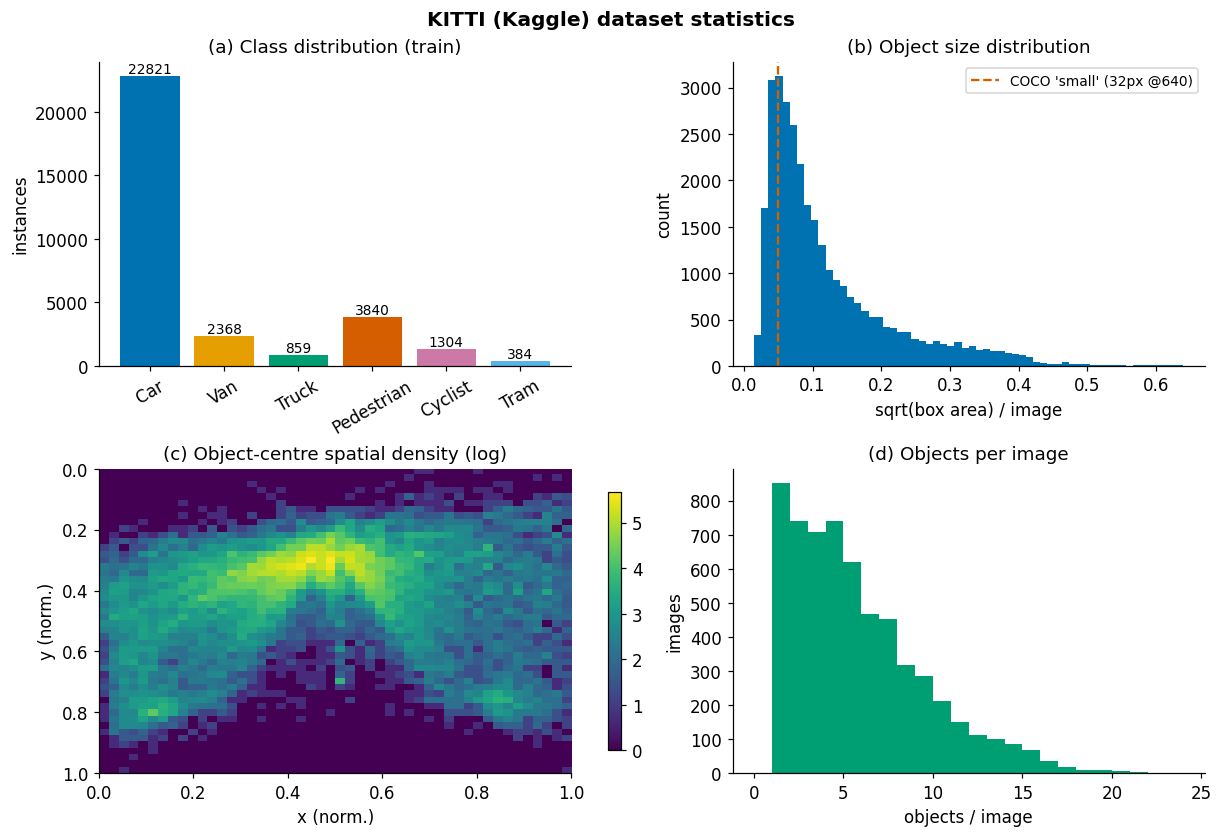

saved -> figures/F02_annotated_samples.png|.pdf


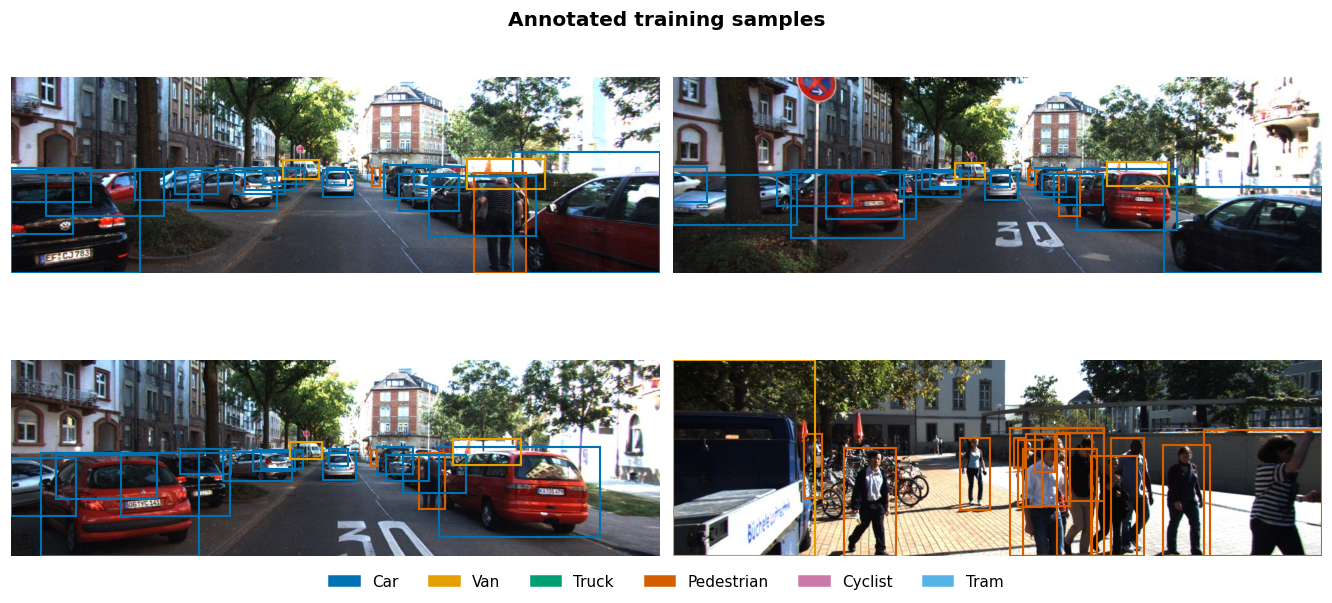

     Class  Train instances  Val instances Median rel. height
       Car            22821           5919             0.1254
       Van             2368            546             0.1386
     Truck              859            234              0.156
Pedestrian             3840            868             0.2366
   Cyclist             1304            323             0.1663
      Tram              384            127             0.1755
     TOTAL            31576           8017                   

Note the class imbalance: Pedestrian/Cyclist are ~10-20x rarer than Car -> motivates the PA-CP contribution (C3).


In [5]:
# ============================================================================
# CELL 4 — DATASET STATISTICS  ->  Figure F01, Figure F02, Table T1
# ============================================================================
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pandas as pd

# ---- unified publication style for ALL figures in this notebook ----
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "font.size": 11,
    "axes.titlesize": 12, "axes.labelsize": 11, "axes.spines.top": False,
    "axes.spines.right": False, "figure.constrained_layout.use": True,
})
# colorblind-safe palette (Okabe-Ito)
PAL = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9",
       "#F0E442", "#000000"]

def savefig(fig, name):
    """Save every figure as 300-dpi PNG (for review) + vector PDF (for LaTeX)."""
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=300)
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    print(f"saved -> figures/{name}.png|.pdf")

def load_labels(split):
    """Return DataFrame of all boxes: cls, xc, yc, w, h, image id."""
    rows = []
    for lf in sorted((DATA_LOCAL / f"labels/{split}").glob("*.txt")):
        for ln in lf.read_text().splitlines():
            c, xc, yc, w, h = ln.split()
            rows.append((int(c), float(xc), float(yc), float(w), float(h), lf.stem))
    return pd.DataFrame(rows, columns=["cls", "xc", "yc", "w", "h", "img"])

df_tr, df_va = load_labels("train"), load_labels("val")

# ---------------- Figure F01: dataset statistics (4 panels) ----------------
fig, ax = plt.subplots(2, 2, figsize=(11, 7.5))
cnt = df_tr.cls.value_counts().reindex(range(len(CFG.CLASSES)), fill_value=0)
bars = ax[0, 0].bar([CFG.CLASSES[i] for i in cnt.index], cnt.values,
                    color=[PAL[i] for i in cnt.index])
ax[0, 0].bar_label(bars, fmt="%d", fontsize=9)
ax[0, 0].set(title="(a) Class distribution (train)", ylabel="instances")
ax[0, 0].tick_params(axis="x", rotation=30)

area = (df_tr.w * df_tr.h) ** 0.5           # sqrt(rel. area) = relative object size
ax[0, 1].hist(area, bins=60, color=PAL[0])
ax[0, 1].axvline(32/640, color=PAL[3], ls="--", lw=1.5,
                 label="COCO 'small' (32px @640)")
ax[0, 1].set(title="(b) Object size distribution", xlabel="sqrt(box area) / image",
             ylabel="count"); ax[0, 1].legend(fontsize=9)

h2, x2, y2 = np.histogram2d(df_tr.xc, df_tr.yc, bins=48)
im = ax[1, 0].imshow(np.log1p(h2.T), extent=[0, 1, 1, 0], aspect="auto", cmap="viridis")
ax[1, 0].set(title="(c) Object-centre spatial density (log)", xlabel="x (norm.)",
             ylabel="y (norm.)")
fig.colorbar(im, ax=ax[1, 0], shrink=0.85)

per_img = df_tr.groupby("img").size()
ax[1, 1].hist(per_img, bins=range(0, 25), color=PAL[2])
ax[1, 1].set(title="(d) Objects per image", xlabel="objects / image", ylabel="images")
fig.suptitle("KITTI (Kaggle) dataset statistics", fontweight="bold")
savefig(fig, "F01_dataset_statistics"); plt.show()

# ---------------- Figure F02: annotated samples ----------------
fig, axes = plt.subplots(2, 2, figsize=(12, 5.4))
sample_ids = per_img.sort_values(ascending=False).index[[3, 10, 25, 60]]
for a, iid in zip(axes.flat, sample_ids):
    img = plt.imread(DATA_LOCAL / f"images/train/{iid}.jpg")
    a.imshow(img); a.axis("off")
    H, W = img.shape[:2]
    for _, b in df_tr[df_tr.img == iid].iterrows():
        x1, y1 = (b.xc - b.w/2) * W, (b.yc - b.h/2) * H
        a.add_patch(mpatches.Rectangle((x1, y1), b.w*W, b.h*H, fill=False,
                                       edgecolor=PAL[int(b.cls)], lw=1.4))
handles = [mpatches.Patch(color=PAL[i], label=c) for i, c in enumerate(CFG.CLASSES)]
fig.legend(handles=handles, ncol=6, loc="lower center", fontsize=10, frameon=False)
fig.suptitle("Annotated training samples", fontweight="bold")
savefig(fig, "F02_annotated_samples"); plt.show()

# ---------------- Table T1: dataset summary ----------------
t1 = pd.DataFrame({
    "Class": CFG.CLASSES,
    "Train instances": [int((df_tr.cls == i).sum()) for i in range(len(CFG.CLASSES))],
    "Val instances":   [int((df_va.cls == i).sum()) for i in range(len(CFG.CLASSES))],
    "Median rel. height": [round(float(df_tr[df_tr.cls == i].h.median()), 4)
                           for i in range(len(CFG.CLASSES))],
})
t1.loc[len(t1)] = ["TOTAL", int(len(df_tr)), int(len(df_va)), ""]
t1.to_csv(TAB_DIR / "T1_dataset_summary.csv", index=False)
(TAB_DIR / "T1_dataset_summary.tex").write_text(
    t1.to_latex(index=False, caption="KITTI dataset summary (5,985 train / 1,496 val images).",
                label="tab:dataset"))
print(t1.to_string(index=False))
print("\nNote the class imbalance: Pedestrian/Cyclist are ~10-20x rarer than Car -> "
      "motivates the PA-CP contribution (C3).")

## Section 2 — The Perspective-Geometry Prior (the paper's motivation figure)

**Hypothesis:** because the camera is rigidly mounted and objects sit on the road plane,
the normalized image row `y` of an object deterministically constrains its apparent height `h`.

The next cell **quantifies** this on the *training* labels only (no leakage):
it bins `y` and computes the median / inter-quartile height per class, producing

* `perspective_prior.json` — the single learned prior consumed by **all three contributions**
  (PGSA & PGCSF read the row-conditioning; PA-CP samples paste sizes from it), and
* **Figure F03** — the motivation figure: a hexbin of 25k+ (y, h) pairs with per-class median
  curves, plus the Spearman rank correlation printed for the paper text.

A Spearman ρ ≳ 0.9 between `y` and `h` is the empirical justification reviewers will ask for.

Spearman rho(y_bottom, height) over 31576 train boxes: 0.917  <- quote this in the paper (Section: Motivation)
  Car         rho=0.954  (n=22821)
  Van         rho=0.883  (n=2368)
  Truck       rho=0.885  (n=859)
  Pedestrian  rho=0.959  (n=3840)
  Cyclist     rho=0.930  (n=1304)
  Tram        rho=0.923  (n=384)
prior saved -> /content/drive/MyDrive/PGP-YOLO/prior/perspective_prior.json
saved -> figures/F03_perspective_prior.png|.pdf


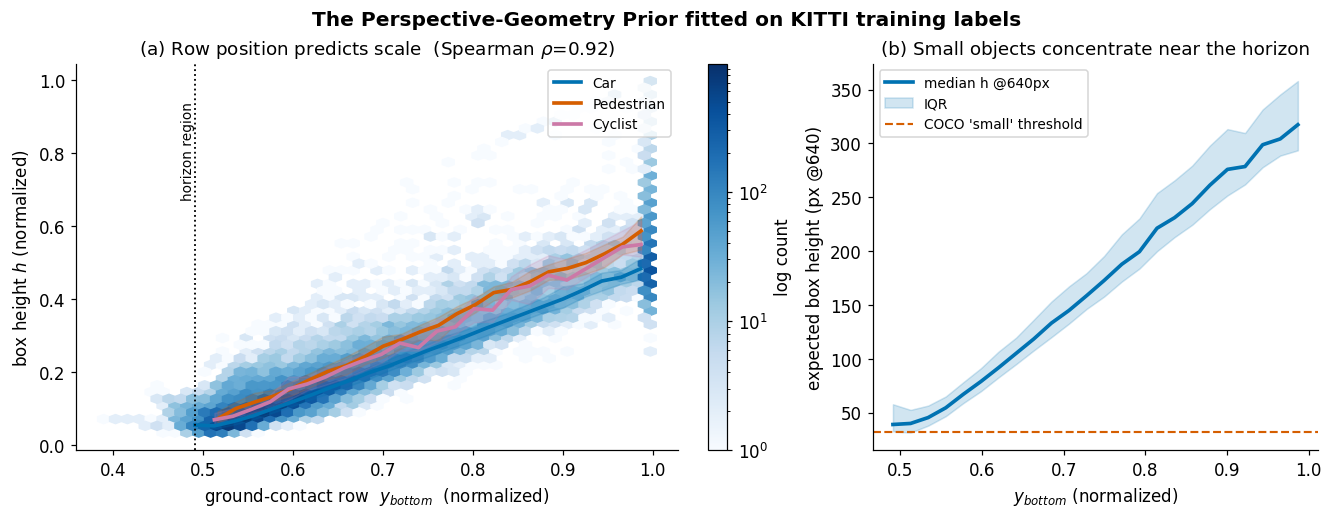


Reading of F03: IF a detector exploited this prior, P3 (small objects) would
specialize on horizon rows and P5 on the lower rows. Whether training actually
learns such routing is TESTED in F17 - do not assert it in the paper before
checking that figure (in our controlled runs the gates stayed near identity,
which is itself a reportable finding).


In [6]:
# ============================================================================
# CELL 5 — FIT THE PERSPECTIVE-GEOMETRY PRIOR  ->  Figure F03 + prior JSON
# ============================================================================
from scipy.stats import spearmanr

# geometric anchor = ground-contact row (box bottom), the physically meaningful coord
df_tr["yb"] = (df_tr.yc + df_tr.h / 2).clip(0, 1)

rho_all, _ = spearmanr(df_tr.yb, df_tr.h)
print(f"Spearman rho(y_bottom, height) over {len(df_tr)} train boxes: {rho_all:.3f}"
      "  <- quote this in the paper (Section: Motivation)")

def fit_prior(d, bins=CFG.PRIOR_BINS):
    """Binned robust prior: median + IQR of box height as a function of y_bottom."""
    lo, hi = float(d.yb.quantile(0.005)), float(d.yb.quantile(0.995))
    edges = np.linspace(lo, hi, bins + 1)
    ctr, med, p25, p75, n = [], [], [], [], []
    for a, b in zip(edges[:-1], edges[1:]):
        seg = d[(d.yb >= a) & (d.yb < b)].h
        if len(seg) >= 8:
            ctr.append(float((a + b) / 2)); med.append(float(seg.median()))
            p25.append(float(seg.quantile(.25))); p75.append(float(seg.quantile(.75)))
            n.append(int(len(seg)))
    return dict(y=ctr, h_med=med, h_p25=p25, h_p75=p75, n=n,
                y_min=lo, y_max=hi)

prior = {"pooled": fit_prior(df_tr), "spearman_rho": float(rho_all),
         "classes": {}}
for i, cname in enumerate(CFG.CLASSES):
    seg = df_tr[df_tr.cls == i]
    if len(seg) > 200:
        prior["classes"][str(i)] = fit_prior(seg)
        r, _ = spearmanr(seg.yb, seg.h)
        print(f"  {cname:<11s} rho={r:.3f}  (n={len(seg)})")
PRIOR_JSON.write_text(json.dumps(prior))
print(f"prior saved -> {PRIOR_JSON}")

def prior_h(y, cls=None):
    """Median expected height at ground-contact row y (linear interpolation)."""
    p = prior["classes"].get(str(cls), prior["pooled"]) if cls is not None else prior["pooled"]
    return float(np.interp(y, p["y"], p["h_med"]))

# ---------------- Figure F03: THE motivation figure ----------------
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.6),
                             gridspec_kw={"width_ratios": [1.35, 1]})
hb = a1.hexbin(df_tr.yb, df_tr.h, gridsize=46, bins="log", cmap="Blues", mincnt=1)
for i in [0, 3, 4]:                                   # Car, Pedestrian, Cyclist curves
    p = prior["classes"].get(str(i))
    if p:
        a1.plot(p["y"], p["h_med"], color=PAL[i], lw=2.4, label=CFG.CLASSES[i])
        a1.fill_between(p["y"], p["h_p25"], p["h_p75"], color=PAL[i], alpha=0.18)
hz = prior["pooled"]["y"][int(np.argmin(prior["pooled"]["h_med"]))]
a1.axvline(hz, color="k", ls=":", lw=1.2)
a1.annotate("horizon region", (hz, a1.get_ylim()[1] * 0.9), fontsize=9,
            rotation=90, va="top", ha="right")
a1.set(xlabel="ground-contact row  $y_{bottom}$  (normalized)",
       ylabel="box height $h$ (normalized)",
       title=f"(a) Row position predicts scale  (Spearman $\\rho$={rho_all:.2f})")
a1.legend(fontsize=9); fig.colorbar(hb, ax=a1, label="log count")

# right panel: same prior in *pixel* space intuition at 640px + row occupancy
p = prior["pooled"]
a2.plot(p["y"], np.array(p["h_med"]) * 640, color=PAL[0], lw=2.4, label="median h @640px")
a2.fill_between(p["y"], np.array(p["h_p25"]) * 640, np.array(p["h_p75"]) * 640,
                color=PAL[0], alpha=0.18, label="IQR")
a2.axhline(32, color=PAL[3], ls="--", lw=1.4, label="COCO 'small' threshold")
a2.set(xlabel="$y_{bottom}$ (normalized)", ylabel="expected box height (px @640)",
       title="(b) Small objects concentrate near the horizon")
a2.legend(fontsize=9)
fig.suptitle("The Perspective-Geometry Prior fitted on KITTI training labels",
             fontweight="bold")
savefig(fig, "F03_perspective_prior"); plt.show()

print("\nReading of F03: IF a detector exploited this prior, P3 (small objects) would\n"
      "specialize on horizon rows and P5 on the lower rows. Whether training actually\n"
      "learns such routing is TESTED in F17 - do not assert it in the paper before\n"
      "checking that figure (in our controlled runs the gates stayed near identity,\n"
      "which is itself a reportable finding).")

## Section 3 — PGP-YOLO: method implementation

The next three cells implement the proposed model **inside the Ultralytics framework** so that
checkpointing, resume, AMP, EMA, and export all keep working:

1. **`pgp_modules.py`** (written to disk — required so checkpoints can be un-pickled after a
   Colab reconnect): defines `PGSA` and `PGCSF`, both **zero-initialized to identity** — at epoch 0,
   PGP-YOLO is *exactly* YOLO11 + COCO weights, so any gain is learned, not initialization luck.
2. **Graph surgery**: reads the *installed* stock `yolo11.yaml`, inserts `PGCSF` after every neck
   `Concat` and `PGSA` after each of the three head branches (P3/P4/P5), and rewrites all layer
   indices. Because this manipulates the official YAML programmatically, it is robust to the exact
   channel configuration and survives Ultralytics' model re-instantiation during training/resume.
3. **Pretrained-weight remapping**: COCO YOLO11 weights are transferred layer-by-layer through the
   computed old→new index map (expected transfer rate is printed — all backbone + neck weights map
   over; only the 6-class heads re-initialize).

Design constraints worth stating in the paper: both modules are **content-independent**
(they consume only the normalized row coordinate — a pure geometric prior, unlike CoordAtt/CBAM
which derive attention from features), add **< 20k parameters and < 0.1% FLOPs**, and are
plug-compatible with any FPN-style detector.

In [7]:
%%writefile pgp_modules.py
# ============================================================================
# pgp_modules.py - PGP-YOLO custom modules + model builder.
# This file must exist on disk in every session: Ultralytics checkpoints pickle
# references to these classes, so resuming after a Colab reconnect re-imports it.
# ============================================================================
import math
from copy import deepcopy
from datetime import datetime
from pathlib import Path

import torch
import torch.nn as nn
import yaml as pyyaml


def _row_feats(H, device, dtype):
    """Fourier-style embedding of the normalized image row r in [0,1] -> (H,4)."""
    r = torch.linspace(0.0, 1.0, H, device=device, dtype=dtype)
    return torch.stack([r, r * r, torch.sin(math.pi * r), torch.cos(math.pi * r)], dim=1)


class PGSA(nn.Module):
    """Perspective-Guided Scale Attention (contribution C1).

    Content-INDEPENDENT gating: a tiny MLP maps (row-embedding, pyramid-level
    one-hot) -> per-row gains for `groups` channel groups. Zero-init => identity
    at the start of training. The gate depends only on WHERE (image row), not on
    WHAT (features) - it is a learned camera-geometry prior.
    """

    def __init__(self, groups=8, level=0, hidden=32):
        super().__init__()
        self.k, self.level = int(groups), int(level)
        self.mlp = nn.Sequential(nn.Linear(7, hidden), nn.SiLU(),
                                 nn.Linear(hidden, self.k))
        nn.init.zeros_(self.mlp[-1].weight)
        nn.init.zeros_(self.mlp[-1].bias)

    def forward(self, x):
        B, C, H, W = x.shape
        # The gate is content-independent -> at inference it is a CONSTANT per
        # feature-map size. Cache it (getattr guard keeps checkpoints pickled
        # with older versions of this class loadable). Identical math, removes
        # the per-forward MLP overhead from the latency benchmark.
        if not self.training:
            key = (H, C, str(x.dtype), str(x.device))
            c = getattr(self, "_gcache", None)
            if c is not None and c[0] == key:
                return x * c[1]
        f = _row_feats(H, x.device, x.dtype)                    # (H,4)
        lv = f.new_zeros(H, 3)
        lv[:, self.level] = 1.0
        g = torch.tanh(self.mlp(torch.cat([f, lv], dim=1)))     # (H,k) in (-1,1)
        k = self.k if C % self.k == 0 else 1
        if k == 1:
            g = g.mean(dim=1, keepdim=True)
        gate = g.repeat_interleave(C // k, dim=1)               # (H,C)
        gate = 1.0 + gate.t().unsqueeze(0).unsqueeze(-1)        # (1,C,H,1)
        if not self.training:
            self._gcache = (key, gate.detach())
        return x * gate


class PGCSF(nn.Module):
    """Perspective-Guided Cross-Scale Fusion (contribution C2).

    Placed right after a neck `Concat`. Splits the fused tensor back into its
    source pathways (deep/semantic vs shallow/detail) and re-weights them per
    image row with a softmax gate (sum preserved). Zero-init => equal weights =>
    identity. `base_splits` are the unscaled channel counts of the concatenated
    sources; actual splits are recovered proportionally at runtime, so the same
    module definition works for every model scale.
    """

    def __init__(self, base_splits, hidden=16):
        super().__init__()
        self.base = [int(b) for b in base_splits]
        self.n = len(self.base)
        self.mlp = nn.Sequential(nn.Linear(4, hidden), nn.SiLU(),
                                 nn.Linear(hidden, self.n))
        nn.init.zeros_(self.mlp[-1].weight)
        nn.init.zeros_(self.mlp[-1].bias)

    def forward(self, x):
        B, C, H, W = x.shape
        tot = sum(self.base)
        splits = [C * b // tot for b in self.base]
        splits[-1] = C - sum(splits[:-1])
        w = None
        if not self.training:                      # same eval-time cache as PGSA
            key = (H, str(x.dtype), str(x.device))
            c = getattr(self, "_wcache", None)
            if c is not None and c[0] == key:
                w = c[1]
        if w is None:
            w = torch.softmax(self.mlp(_row_feats(H, x.device, x.dtype)), dim=1) * self.n
            if not self.training:
                self._wcache = (key, w.detach())
        parts = torch.split(x, splits, dim=1)
        return torch.cat([p * w[:, i].view(1, 1, H, 1) for i, p in enumerate(parts)],
                         dim=1)


def model_complexity(m, imgsz=640):
    """Return (num_params, gflops) robustly across Ultralytics versions.

    `YOLO.info()` changed its return contract between releases (some return None),
    so we count parameters directly and fetch FLOPs via the stable util, guarded.
    `m` may be a YOLO wrapper or a raw nn.Module.
    """
    net = getattr(m, "model", m)
    params = sum(p.numel() for p in net.parameters())
    gflops = float("nan")
    try:
        from ultralytics.utils.torch_utils import get_flops
        gflops = float(get_flops(net, imgsz))
    except Exception:
        pass
    return params, gflops


def register_pgp_modules():
    """Make PGSA/PGCSF resolvable by Ultralytics' YAML parser and safe to unpickle."""
    import ultralytics.nn.tasks as _tasks
    import ultralytics.nn.modules as _mods
    for cls in (PGSA, PGCSF):
        setattr(_tasks, cls.__name__, cls)   # parse_model() resolves via tasks globals
        setattr(_mods, cls.__name__, cls)
    try:  # torch>=2.6 pickling allow-list (harmless no-op on older torch)
        torch.serialization.add_safe_globals([PGSA, PGCSF])
    except Exception:
        pass


# ----------------------------------------------------------------------------
# Graph surgery: stock yolo11.yaml -> pgp-yolo yaml (+ index map for weights)
# ----------------------------------------------------------------------------
_CH_MODULES = ("Conv", "C3k2", "SPPF", "C2PSA", "C2f", "SPPELAN", "ELAN1")


def build_pgp_yaml(scale="s", nc=6, include_pgcsf=True,
                   groups=8, sa_hidden=32, csf_hidden=16):
    """Return (yaml_dict, old->new absolute-layer-index map)."""
    import ultralytics
    stock = Path(ultralytics.__file__).parent / "cfg/models/11/yolo11.yaml"
    assert stock.exists(), f"stock yolo11.yaml not found at {stock}"
    d = pyyaml.safe_load(stock.read_text())
    backbone, head = d["backbone"], d["head"]
    nb = len(backbone)

    def src_idx(f, i):                       # resolve a 'from' ref to absolute index
        return i - 1 if f == -1 else (f if f >= 0 else i + f)

    # base (unscaled) output channels of each ORIGINAL row - needed by PGCSF splits
    base_ch = {}
    for i, (f, n, m, args) in enumerate(backbone + head):
        if m in _CH_MODULES:
            base_ch[i] = args[0]
        elif m == "nn.Upsample":
            base_ch[i] = base_ch[src_idx(f, i)]
        elif m == "Concat":
            base_ch[i] = sum(base_ch[src_idx(x, i)] for x in f)
        else:                                # Detect etc.
            base_ch[i] = None

    detect_srcs = list(head[-1][0])
    assert head[-1][2] == "Detect", "unexpected stock head layout"

    old2new = {i: i for i in range(nb)}      # backbone indices are unchanged
    det_repl, new_head, cur = {}, [], nb

    def remap(f, old_i):
        if isinstance(f, list):
            return [remap(x, old_i) for x in f]
        return -1 if f == -1 else old2new[src_idx(f, old_i)]

    for j, (f, n, m, args) in enumerate(head):
        old_i = nb + j
        if m == "Detect":
            new_head.append([[det_repl.get(s, old2new[s]) for s in detect_srcs],
                             n, m, list(args)])
            old2new[old_i] = cur; cur += 1
            continue
        new_head.append([remap(f, old_i), n, m, list(args)])
        old2new[old_i] = cur; cur += 1
        if m == "Concat" and include_pgcsf:  # C2: row-conditioned fusion re-weighting
            srcs = [src_idx(x, old_i) for x in f]
            new_head.append([-1, 1, "PGCSF", [[base_ch[s] for s in srcs], csf_hidden]])
            cur += 1
        if old_i in detect_srcs:             # C1: row-conditioned level gating
            level = detect_srcs.index(old_i)
            new_head.append([-1, 1, "PGSA", [groups, level, sa_hidden]])
            det_repl[old_i] = cur; cur += 1

    d["head"], d["nc"], d["scale"] = new_head, nc, scale
    return d, old2new


def transfer_coco_weights(new_det_model, scale, old2new):
    """Copy COCO-pretrained YOLO11 weights through the index map (shape-checked)."""
    from ultralytics import YOLO
    donor_sd = YOLO(f"yolo11{scale}.pt").model.state_dict()
    remapped = {}
    for k, v in donor_sd.items():
        parts = k.split(".")
        if parts[0] == "model" and parts[1].isdigit():
            parts[1] = str(old2new.get(int(parts[1]), int(parts[1])))
        remapped[".".join(parts)] = v
    msd = new_det_model.state_dict()
    ok = {k: v for k, v in remapped.items() if k in msd and v.shape == msd[k].shape}
    new_det_model.load_state_dict(ok, strict=False)
    return len(ok), len(msd)


def save_init_ckpt(det_model, path):
    """Save an Ultralytics-schema checkpoint so YOLO(path).train() rebuilds
    the custom architecture (yaml dict travels inside the pickled model)."""
    import ultralytics
    m = deepcopy(det_model).half()
    for p in m.parameters():
        p.requires_grad = False
    torch.save({"epoch": -1, "best_fitness": None, "model": m, "ema": None,
                "updates": None, "optimizer": None, "train_args": {},
                "date": datetime.now().isoformat(),
                "version": ultralytics.__version__}, path)

Writing pgp_modules.py


In [8]:
# ============================================================================
# CELL 7 — BUILD PGP-YOLO VARIANTS (A1, A2) + transfer COCO weights
# Re-run every session (fast, deterministic): registers custom modules and
# regenerates the init checkpoints used by not-yet-started training runs.
# ============================================================================
import importlib, pgp_modules
importlib.reload(pgp_modules)
from pgp_modules import (PGSA, PGCSF, register_pgp_modules, build_pgp_yaml,
                         transfer_coco_weights, save_init_ckpt, model_complexity)
register_pgp_modules()

VARIANTS = {  # init-ckpt filename -> config
    "pgp_a1_init.pt": dict(include_pgcsf=False, tag="A1: YOLO11 + PGSA"),
    "pgp_a2_init.pt": dict(include_pgcsf=True,  tag="A2: YOLO11 + PGSA + PGCSF"),
}
pgp_meta = {}
for fname, kw in VARIANTS.items():
    tag = kw.pop("tag")
    d, old2new = build_pgp_yaml(scale=CFG.SCALE, nc=len(CFG.CLASSES),
                                groups=CFG.PGSA_GROUPS, sa_hidden=CFG.PGSA_HIDDEN,
                                csf_hidden=CFG.PGCSF_HIDDEN, **kw)
    # filename must contain 'yolo11<scale>' so Ultralytics infers the scale
    ypath = LOCAL_ROOT / fname.replace("_init.pt", f"_yolo11{CFG.SCALE}.yaml")
    import yaml as pyyaml
    ypath.write_text(pyyaml.safe_dump(d, sort_keys=False))

    model = YOLO(str(ypath), task="detect")
    n_sa  = sum(isinstance(m, PGSA)  for m in model.model.modules())
    n_csf = sum(isinstance(m, PGCSF) for m in model.model.modules())
    assert n_sa == 3, f"expected 3 PGSA modules, got {n_sa}"
    assert n_csf == (4 if kw["include_pgcsf"] else 0), f"unexpected PGCSF count {n_csf}"

    with torch.no_grad():                       # sanity: identity-init forward pass
        model.model.eval()(torch.zeros(1, 3, CFG.IMGSZ, CFG.IMGSZ))

    n_ok, n_all = transfer_coco_weights(model.model, CFG.SCALE, old2new)
    params, gflops = model_complexity(model, CFG.IMGSZ)
    init_path = LOCAL_ROOT / fname
    save_init_ckpt(model.model, init_path)
    shutil.copy(init_path, DRIVE_ROOT / "env" / fname)      # provenance copy
    shutil.copy(ypath, DRIVE_ROOT / "env" / ypath.name)
    pgp_meta[fname] = dict(params=params, gflops=gflops)
    print(f"{tag}\n  PGSA x{n_sa}, PGCSF x{n_csf} | {params/1e6:.2f}M params, "
          f"{gflops:.1f} GFLOPs | COCO tensors transferred: {n_ok}/{n_all} "
          f"| init -> {init_path.name}")
    del model; gc.collect()

# overhead vs. stock YOLO11 (paper: "negligible cost" claim, quantified)
stock = YOLO(f"yolo11{CFG.SCALE}.pt")
p0, g0 = model_complexity(stock, CFG.IMGSZ)
p1, g1 = pgp_meta["pgp_a2_init.pt"]["params"], pgp_meta["pgp_a2_init.pt"]["gflops"]
print(f"\nOverhead of full PGP head vs stock YOLO11{CFG.SCALE}: "
      f"+{(p1-p0)/1e3:.1f}k params (+{100*(p1-p0)/p0:.3f}%), "
      f"+{g1-g0:.2f} GFLOPs (+{100*(g1-g0)/max(g0,1e-9):.3f}%)")
del stock; gc.collect()

100%|██████████| 18.4M/18.4M [00:00<00:00, 62.8MB/s]


A1: YOLO11 + PGSA
  PGSA x3, PGCSF x0 | 9.43M params, 21.6 GFLOPs | COCO tensors transferred: 493/511 | init -> pgp_a1_init.pt
A2: YOLO11 + PGSA + PGCSF
  PGSA x3, PGCSF x4 | 9.43M params, 21.6 GFLOPs | COCO tensors transferred: 493/527 | init -> pgp_a2_init.pt

Overhead of full PGP head vs stock YOLO11s: +-26.6k params (+-0.281%), +-0.16 GFLOPs (+-0.717%)


6882

Restoring PA-CP images from Drive cache...
restored 1735 images
saved -> figures/F04_pacp_examples.png|.pdf


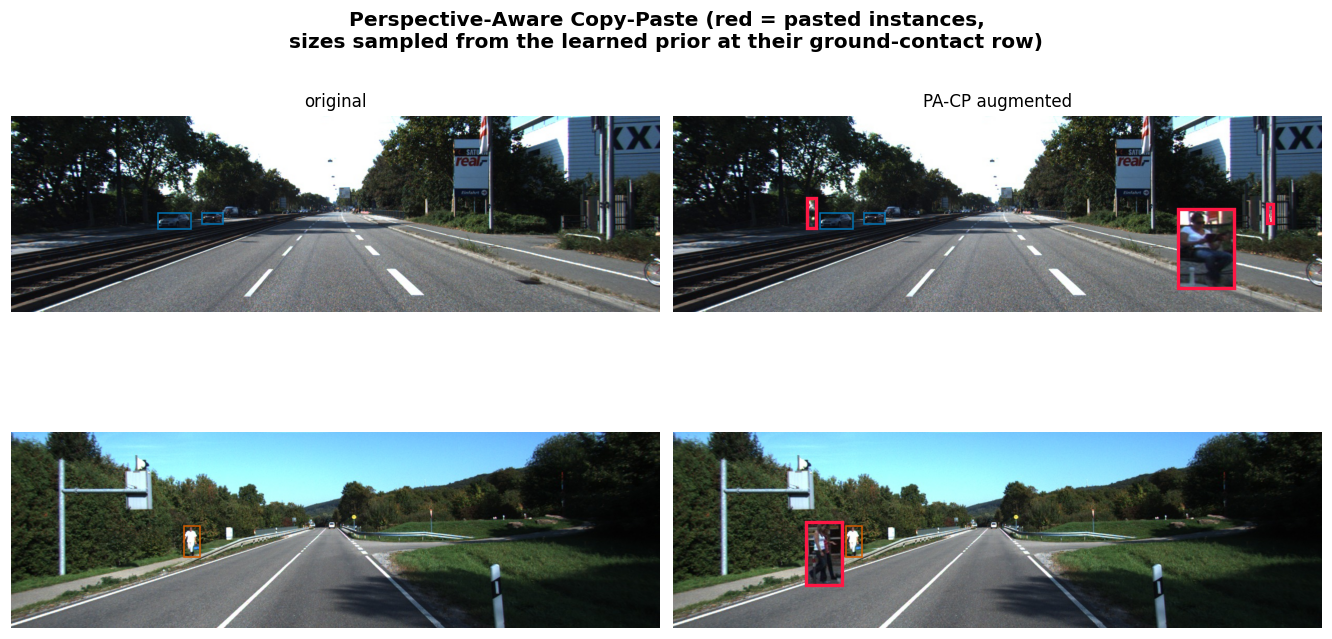

In [9]:
# ============================================================================
# CELL 8 — PA-CP: Perspective-Aware Copy-Paste augmentation  ->  Figure F04
# Offline, deterministic (seeded), Drive-cached. Only the PROPOSED run uses
# the augmented yaml; ablations A1/A2 and baselines never see these images.
# ============================================================================
from PIL import Image, ImageFilter

PACP_IMG = DATA_LOCAL / "images/train_pacp"
PACP_LBL = DATA_LOCAL / "labels/train_pacp"
PACP_IMG.mkdir(parents=True, exist_ok=True); PACP_LBL.mkdir(parents=True, exist_ok=True)

def _iou_1d(b1, boxes):
    """IoU of box b1 (xc,yc,w,h normalized) against an array of boxes."""
    if len(boxes) == 0:
        return np.zeros(0)
    b1 = np.array(b1); boxes = np.array(boxes)
    x11, y11 = b1[0]-b1[2]/2, b1[1]-b1[3]/2; x12, y12 = b1[0]+b1[2]/2, b1[1]+b1[3]/2
    x21, y21 = boxes[:,0]-boxes[:,2]/2, boxes[:,1]-boxes[:,3]/2
    x22, y22 = boxes[:,0]+boxes[:,2]/2, boxes[:,1]+boxes[:,3]/2
    iw = np.maximum(0, np.minimum(x12,x22) - np.maximum(x11,x21))
    ih = np.maximum(0, np.minimum(y12,y22) - np.maximum(y11,y21))
    inter = iw*ih
    return inter / (b1[2]*b1[3] + boxes[:,2]*boxes[:,3] - inter + 1e-9)

if len(list(PACP_IMG.glob("*.jpg"))) > 100:
    print("PA-CP images already present - skipping generation.")
elif PACP_CACHE.exists():
    print("Restoring PA-CP images from Drive cache...")
    shutil.unpack_archive(PACP_CACHE, DATA_LOCAL, "zip")
    print(f"restored {len(list(PACP_IMG.glob('*.jpg')))} images")
else:
    rng = random.Random(CFG.SEED + 1)
    # ---- 1. crop bank: clean rare-class instances from TRAIN images only ----
    bank = []
    for _, b in df_tr[df_tr.cls.isin(CFG.PACP_CLASSES) &
                      (df_tr.h > CFG.PACP_MIN_SRC_H)].iterrows():
        bank.append(b)
    rng.shuffle(bank); bank = bank[:800]
    print(f"crop bank: {len(bank)} source instances "
          f"({[CFG.CLASSES[c] for c in CFG.PACP_CLASSES]})")

    # ---- 2. paste at geometry-consistent positions sampled from THE prior ----
    pooled = prior["pooled"]
    y_lo = max(pooled["y_min"], pooled["y"][int(np.argmin(pooled["h_med"]))])  # below horizon
    y_hi = min(pooled["y_max"], 0.96)
    train_ids = sorted(p.stem for p in (DATA_LOCAL/"images/train").glob("*.jpg"))
    chosen = rng.sample(train_ids, int(len(train_ids) * CFG.PACP_FRACTION))
    added = {c: 0 for c in CFG.PACP_CLASSES}

    for iid in tqdm(chosen, desc="PA-CP"):
        im = Image.open(DATA_LOCAL/f"images/train/{iid}.jpg").convert("RGB")
        W, H = im.size
        lblf = DATA_LOCAL/f"labels/train/{iid}.txt"
        lines = lblf.read_text().splitlines() if lblf.exists() else []
        boxes = [list(map(float, l.split()[1:])) for l in lines]
        new_lines = list(lines)
        for _ in range(rng.randint(1, CFG.PACP_MAX_PASTE)):
            src = bank[rng.randrange(len(bank))]
            # geometry-consistent placement: sample ground-contact row, look up size
            yb = rng.uniform(y_lo, y_hi)
            h_t = prior_h(yb, int(src.cls)) * rng.uniform(0.85, 1.2)
            w_t = h_t * (src.w / src.h)               # keep source aspect ratio
            xc = rng.uniform(w_t/2 + 0.01, 1 - w_t/2 - 0.01)
            yc = yb - h_t/2
            cand = [xc, yc, w_t, h_t]
            if yc - h_t/2 < 0 or (_iou_1d(cand, boxes) > 0.25).any():
                continue                              # reject overlaps / out-of-frame
            # cut source crop from its original image
            simg = Image.open(DATA_LOCAL/f"images/train/{src.img}.jpg").convert("RGB")
            sW, sH = simg.size
            cx1 = int((src.xc-src.w/2)*sW); cy1 = int((src.yc-src.h/2)*sH)
            crop = simg.crop((cx1, cy1, cx1+int(src.w*sW)+1, cy1+int(src.h*sH)+1))
            tw, th = max(int(w_t*W), 6), max(int(h_t*H), 10)
            crop = crop.resize((tw, th), Image.LANCZOS)
            # feathered alpha mask -> no hard paste borders (avoids paste artifacts)
            mask = Image.new("L", (tw, th), 255)
            mask = mask.filter(ImageFilter.GaussianBlur(max(1, min(tw, th)//12)))
            im.paste(crop, (int((xc-w_t/2)*W), int((yc-h_t/2)*H)), mask)
            new_lines.append(f"{int(src.cls)} {xc:.6f} {yc:.6f} {w_t:.6f} {h_t:.6f}")
            boxes.append(cand); added[int(src.cls)] += 1
        if len(new_lines) > len(lines):               # only save if something was pasted
            im.save(PACP_IMG/f"{iid}_pacp.jpg", quality=CFG.JPEG_QUALITY)
            (PACP_LBL/f"{iid}_pacp.txt").write_text("\n".join(new_lines))

    print("PA-CP added instances:",
          {CFG.CLASSES[c]: n for c, n in added.items()},
          f"| {len(list(PACP_IMG.glob('*.jpg')))} augmented images")
    # cache to Drive so every future session trains on BYTE-IDENTICAL images
    tmp = LOCAL_ROOT/"pacp_cache"
    shutil.make_archive(str(tmp), "zip", DATA_LOCAL, "images/train_pacp")
    # include labels in the same zip
    import zipfile
    with zipfile.ZipFile(str(tmp)+".zip", "a") as z:
        for f in PACP_LBL.glob("*.txt"):
            z.write(f, f"labels/train_pacp/{f.name}")
    shutil.move(str(tmp)+".zip", PACP_CACHE)
    print(f"cached -> {PACP_CACHE}")

# ---------------- Figure F04: PA-CP examples ----------------
ex = sorted(PACP_IMG.glob("*.jpg"))[:2]
if ex:
    fig, axes = plt.subplots(len(ex), 2, figsize=(12, 3.1*len(ex)), squeeze=False)
    for r, p in enumerate(ex):
        iid = p.stem.replace("_pacp", "")
        orig_lb = (DATA_LOCAL/f"labels/train/{iid}.txt").read_text().splitlines()
        aug_lb  = (PACP_LBL/f"{p.stem}.txt").read_text().splitlines()
        for c, (title, ipath, lbl, mark_new) in enumerate([
                ("original", DATA_LOCAL/f"images/train/{iid}.jpg", orig_lb, False),
                ("PA-CP augmented", p, aug_lb, True)]):
            img = plt.imread(ipath); Hh, Ww = img.shape[:2]
            axes[r, c].imshow(img); axes[r, c].axis("off")
            axes[r, c].set_title(title if r == 0 else "", fontsize=11)
            for k, ln in enumerate(lbl):
                cl, xc, yc, w, h = map(float, ln.split())
                is_new = mark_new and k >= len(orig_lb)
                axes[r, c].add_patch(mpatches.Rectangle(
                    ((xc-w/2)*Ww, (yc-h/2)*Hh), w*Ww, h*Hh, fill=False,
                    edgecolor="#FF1744" if is_new else PAL[int(cl)],
                    lw=2.2 if is_new else 1.0))
    fig.suptitle("Perspective-Aware Copy-Paste (red = pasted instances,\n"
                 "sizes sampled from the learned prior at their ground-contact row)",
                 fontweight="bold")
    savefig(fig, "F04_pacp_examples"); plt.show()

saved -> figures/F05_architecture.png|.pdf


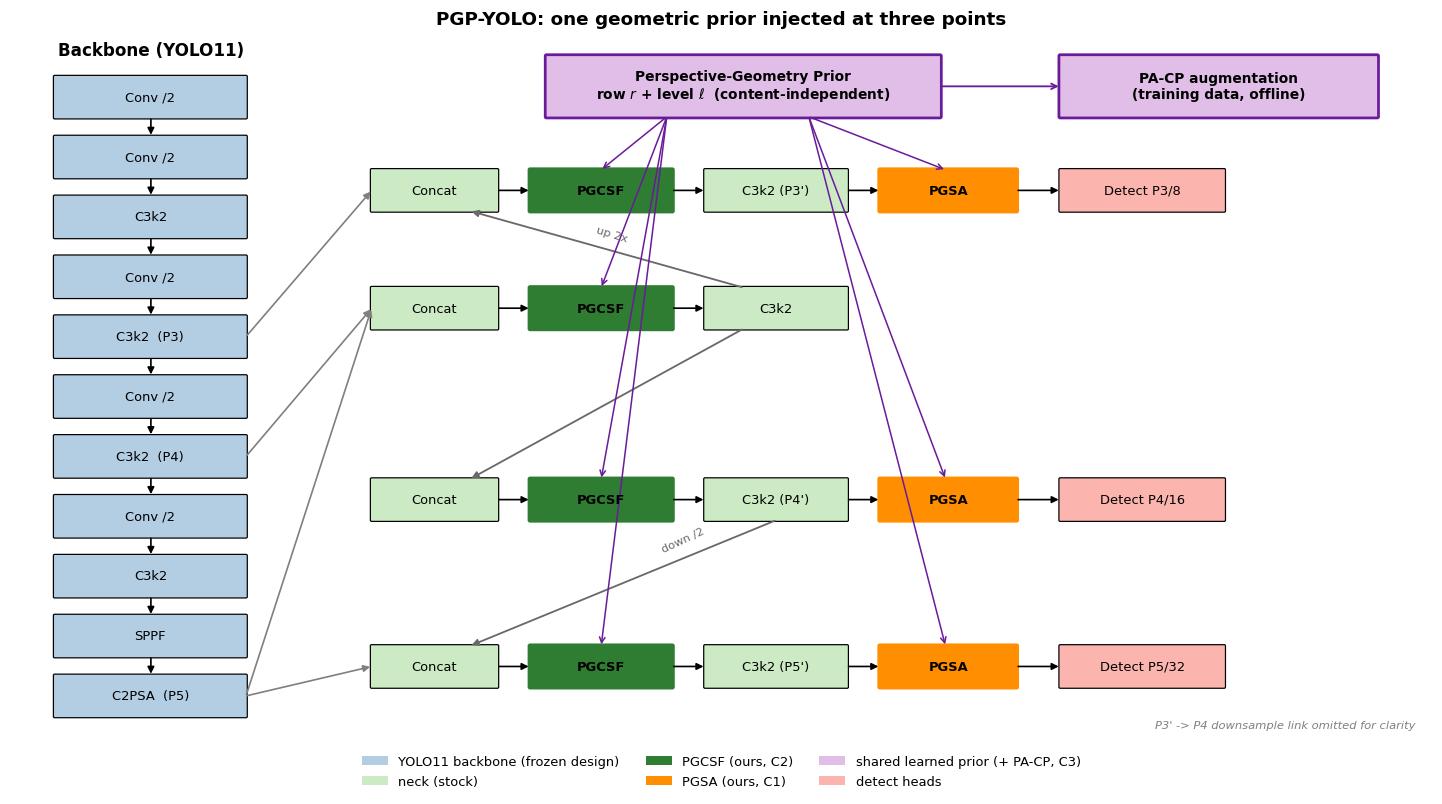

saved -> figures/F06_module_detail.png|.pdf


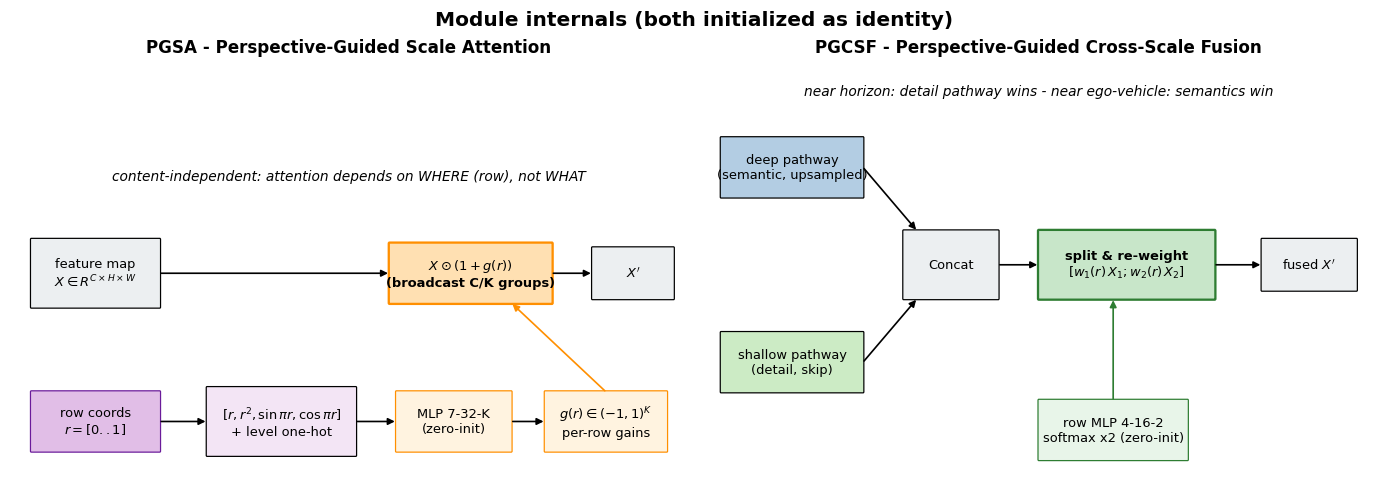

In [10]:
# ============================================================================
# CELL 9 — ARCHITECTURE DIAGRAMS  ->  Figure F05 (network), Figure F06 (modules)
# Publication-grade schematics drawn with matplotlib (fully reproducible).
# ============================================================================
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from matplotlib.lines import Line2D

C_BB, C_NECK, C_HEAD = "#B3CDE3", "#CCEBC5", "#FBB4AE"
C_PGSA, C_PGCSF, C_PRIOR = "#FF8F00", "#2E7D32", "#6A1B9A"

def box(ax, xy, w, h, label, fc, fs=8.5, ec="k", lw=0.8, bold=False):
    ax.add_patch(FancyBboxPatch(xy, w, h, boxstyle="round,pad=0.012",
                                fc=fc, ec=ec, lw=lw))
    ax.text(xy[0]+w/2, xy[1]+h/2, label, ha="center", va="center", fontsize=fs,
            fontweight="bold" if bold else "normal")

def arrow(ax, p1, p2, color="k", lw=1.1, style="-|>"):
    ax.add_patch(FancyArrowPatch(p1, p2, arrowstyle=style, mutation_scale=9,
                                 color=color, lw=lw, shrinkA=1, shrinkB=1))

# ---------------- Figure F05: full PGP-YOLO architecture ----------------
fig, ax = plt.subplots(figsize=(13, 7.2)); ax.set_xlim(0, 13); ax.set_ylim(0, 7.2)
ax.axis("off")

# backbone column
bb = ["Conv /2", "Conv /2", "C3k2", "Conv /2", "C3k2  (P3)", "Conv /2",
      "C3k2  (P4)", "Conv /2", "C3k2", "SPPF", "C2PSA  (P5)"]
ys = np.linspace(6.55, 0.45, len(bb))
for i, (lbl, y) in enumerate(zip(bb, ys)):
    box(ax, (0.4, y-0.21), 1.75, 0.42, lbl, C_BB)
    if i: arrow(ax, (1.28, ys[i-1]-0.21), (1.28, y+0.21))
ax.text(1.28, 6.98, "Backbone (YOLO11)", ha="center", fontsize=11, fontweight="bold")

# neck: top-down + bottom-up with PGCSF after each concat, PGSA on P3/P4/P5 out
def neck_row(yc, label_cat, label_c3k2, label_sa=None):
    box(ax, (3.3, yc-0.21), 1.15, 0.42, "Concat", C_NECK)
    box(ax, (4.75, yc-0.21), 1.3, 0.42, "PGCSF", C_PGCSF, ec=C_PGCSF, lw=1.6, bold=True)
    box(ax, (6.35, yc-0.21), 1.3, 0.42, label_c3k2, C_NECK)
    arrow(ax, (4.45, yc), (4.75, yc)); arrow(ax, (6.05, yc), (6.35, yc))
    if label_sa:
        box(ax, (7.95, yc-0.21), 1.25, 0.42, "PGSA", C_PGSA, ec=C_PGSA, lw=1.6, bold=True)
        arrow(ax, (7.65, yc), (7.95, yc))

y_p5, y_p4, y_p3 = 1.1, 3.0, 4.9
neck_row(4.4, "cat", "C3k2")                       # top-down P5->P4 fusion (no PGSA here)
neck_row(y_p3+0.7, "cat", "C3k2 (P3')", True)
neck_row(y_p4-0.55, "cat", "C3k2 (P4')", True)
neck_row(y_p5-0.35, "cat", "C3k2 (P5')", True)
# backbone->neck skip arrows (YOLO11 head: backbone P4 feeds the INTERMEDIATE
# top-down fusion, backbone P3 the P3 fusion, C2PSA(P5) the mid + P5 fusions)
arrow(ax, (2.15, ys[4]), (3.3, y_p3+0.7), color="gray")
arrow(ax, (2.15, ys[6]), (3.3, 4.4), color="gray")
arrow(ax, (2.15, ys[10]), (3.3, y_p5-0.35), color="gray")
arrow(ax, (2.15, ys[10]), (3.3, 4.4), color="gray")
# neck vertical flow, so the intermediate row is not a dead end: its C3k2 output
# feeds the P3 fusion (upsampled) and the P4 fusion; P4' feeds the P5 fusion.
arrow(ax, (6.7, 4.61), (4.2, y_p3+0.7-0.21), color="dimgray", lw=1.2)
ax.text(5.5, 5.08, "up 2x", fontsize=7.5, color="dimgray", rotation=-17, ha="center")
arrow(ax, (6.7, 4.19), (4.2, y_p4-0.55+0.21), color="dimgray", lw=1.2)
arrow(ax, (7.0, y_p4-0.55-0.21), (4.2, y_p5-0.35+0.21), color="dimgray", lw=1.2)
ax.text(6.15, 1.92, "down /2", fontsize=7.5, color="dimgray", rotation=25, ha="center")
ax.text(12.85, 0.12, "P3' -> P4 downsample link omitted for clarity",
        fontsize=7.5, style="italic", color="gray", ha="right")

# detect heads
for yc, s in [(y_p3+0.7, "P3/8"), (y_p4-0.55, "P4/16"), (y_p5-0.35, "P5/32")]:
    box(ax, (9.6, yc-0.21), 1.5, 0.42, f"Detect {s}", C_HEAD)
    arrow(ax, (9.2, yc), (9.6, yc))

# the shared prior block
box(ax, (4.9, 6.35), 3.6, 0.62,
    "Perspective-Geometry Prior\nrow $r$ + level $\\ell$  (content-independent)",
    "#E1BEE7", ec=C_PRIOR, lw=1.8, fs=9, bold=True)
# prior -> PGCSF on all four fusion rows, but prior -> PGSA only on the three
# head rows: the intermediate 4.4 row has no PGSA box (this stray arrow was the
# "arrow to nothing" bug)
for yc, has_sa in [(y_p3+0.7, True), (y_p4-0.55, True), (y_p5-0.35, True),
                   (4.4, False)]:
    arrow(ax, (6.0, 6.35), (5.4, yc+0.21), color=C_PRIOR, lw=1.0, style="->")
    if has_sa:
        arrow(ax, (7.3, 6.35), (8.55, yc+0.21), color=C_PRIOR, lw=1.0, style="->")
box(ax, (9.6, 6.35), 2.9, 0.62, "PA-CP augmentation\n(training data, offline)",
    "#E1BEE7", ec=C_PRIOR, lw=1.8, fs=9, bold=True)
arrow(ax, (8.5, 6.66), (9.6, 6.66), color=C_PRIOR, lw=1.2, style="->")

ax.legend(handles=[
    mpatches.Patch(fc=C_BB, label="YOLO11 backbone (frozen design)"),
    mpatches.Patch(fc=C_NECK, label="neck (stock)"),
    mpatches.Patch(fc=C_PGCSF, label="PGCSF (ours, C2)"),
    mpatches.Patch(fc=C_PGSA, label="PGSA (ours, C1)"),
    mpatches.Patch(fc="#E1BEE7", label="shared learned prior (+ PA-CP, C3)"),
    mpatches.Patch(fc=C_HEAD, label="detect heads")],
    loc="upper center", bbox_to_anchor=(0.5, -0.005), ncol=3,
    fontsize=8.5, frameon=False)
ax.set_title("PGP-YOLO: one geometric prior injected at three points",
             fontweight="bold")
savefig(fig, "F05_architecture"); plt.show()

# ---------------- Figure F06: module internals ----------------
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.4))
for a in (a1, a2): a.axis("off"); a.set_xlim(0, 10); a.set_ylim(0, 5)

# PGSA internals
a1.set_title("PGSA - Perspective-Guided Scale Attention", fontweight="bold", fontsize=11)
box(a1, (0.3, 2.1), 1.9, 0.8, "feature map\n$X\\in R^{C\\times H\\times W}$", "#ECEFF1")
box(a1, (0.3, 0.4), 1.9, 0.7, "row coords\n$r=[0..1]$", "#E1BEE7", ec=C_PRIOR)
box(a1, (2.9, 0.35), 2.2, 0.8, "$[r, r^2, \\sin\\pi r, \\cos\\pi r]$\n+ level one-hot", "#F3E5F5")
box(a1, (5.7, 0.4), 1.7, 0.7, "MLP 7-32-K\n(zero-init)", "#FFF3E0", ec=C_PGSA)
box(a1, (7.9, 0.4), 1.8, 0.7, "$g(r)\\in(-1,1)^{K}$\nper-row gains", "#FFF3E0", ec=C_PGSA)
box(a1, (5.6, 2.15), 2.4, 0.7, "$X\\odot(1+g(r))$\n(broadcast C/K groups)", "#FFE0B2",
    ec=C_PGSA, lw=1.5, bold=True)
box(a1, (8.6, 2.2), 1.2, 0.6, "$X'$", "#ECEFF1")
arrow(a1, (2.2, 2.5), (5.6, 2.5)); arrow(a1, (2.2, 0.75), (2.9, 0.75))
arrow(a1, (5.1, 0.75), (5.7, 0.75)); arrow(a1, (7.4, 0.75), (7.9, 0.75))
arrow(a1, (8.8, 1.1), (7.4, 2.15), color=C_PGSA); arrow(a1, (8.0, 2.5), (8.6, 2.5))
a1.text(5, 3.6, "content-independent: attention depends on WHERE (row), not WHAT",
        ha="center", fontsize=9, style="italic")

# PGCSF internals
a2.set_title("PGCSF - Perspective-Guided Cross-Scale Fusion", fontweight="bold", fontsize=11)
box(a2, (0.3, 3.4), 2.1, 0.7, "deep pathway\n(semantic, upsampled)", "#B3CDE3")
box(a2, (0.3, 1.1), 2.1, 0.7, "shallow pathway\n(detail, skip)", "#CCEBC5")
box(a2, (3.0, 2.2), 1.4, 0.8, "Concat", "#ECEFF1")
box(a2, (5.0, 0.3), 2.2, 0.7, "row MLP 4-16-2\nsoftmax x2 (zero-init)", "#E8F5E9", ec=C_PGCSF)
box(a2, (5.0, 2.2), 2.6, 0.8, "split & re-weight\n$[w_1(r)\\,X_1 ; w_2(r)\\,X_2]$",
    "#C8E6C9", ec=C_PGCSF, lw=1.5, bold=True)
box(a2, (8.3, 2.3), 1.4, 0.6, "fused $X'$", "#ECEFF1")
arrow(a2, (2.4, 3.75), (3.2, 3.0)); arrow(a2, (2.4, 1.45), (3.2, 2.2))
arrow(a2, (4.4, 2.6), (5.0, 2.6)); arrow(a2, (6.1, 1.0), (6.1, 2.2), color=C_PGCSF)
arrow(a2, (7.6, 2.6), (8.3, 2.6))
a2.text(5, 4.6, "near horizon: detail pathway wins - near ego-vehicle: semantics win",
        ha="center", fontsize=9, style="italic")
fig.suptitle("Module internals (both initialized as identity)", fontweight="bold")
savefig(fig, "F06_module_detail"); plt.show()

## Section 4 — Training: checkpoint-to-Drive, auto-resume, fair protocol

**How the interruption-proofing works** (the free-Colab survival kit):

* Every run trains with `project = <Drive>/runs/<name>` → Ultralytics writes
  `weights/last.pt` + `weights/best.pt` + `results.csv` to **Google Drive after every epoch**.
* A `<name>.done` flag is written to Drive only after a run completes.
* On every (re)start the manager decides per run:
  `done flag → skip` · `last.pt exists → resume from it` · `otherwise → fresh start`.
* So after any disconnect: **Runtime → Run all**, walk away. Nothing is retrained, nothing is lost
  (at most the current epoch repeats).

**Fairness protocol** (state this in the paper): every run uses identical data, split, image size,
batch, epochs, seed, and *default* Ultralytics hyper-parameters — no per-model tuning that could
favor the proposed method. The proposed run differs from ablation A2 **only** by the PA-CP images,
and A1/A2 differ from the YOLO11 baseline **only** by the inserted modules (identity at init).

In [11]:
# ============================================================================
# CELL 10 — TRAINING MANAGER (checkpoint-to-Drive + auto-resume)
# ============================================================================
def exp_paths(name):
    run_dir = RUNS_DIR / name
    return dict(run=run_dir,
                last=run_dir / "weights" / "last.pt",
                best=run_dir / "weights" / "best.pt",
                done=RES_DIR / f"{name}.done")

def is_done(name):
    return exp_paths(name)["done"].exists()

def _mark_done(name):
    exp_paths(name)["done"].write_text(time.strftime("%Y-%m-%d %H:%M:%S"))
    print(f"[{name}] COMPLETE - flag written to Drive.")

def free_gpu(*objs):
    """Aggressively release GPU memory. Training leaves a model<->Trainer
    reference cycle (optimizer state, EMA shadow weights, AMP scaler) that a
    plain `del model` does not fully release within one long-lived Colab
    process - later cells can OOM even though nothing is 'wrong'. Breaking the
    cycle explicitly + a 2-pass gc collects it immediately instead of waiting
    on the cyclic collector."""
    for o in objs:
        try:
            if hasattr(o, "trainer"):
                if hasattr(o.trainer, "optimizer"):
                    o.trainer.optimizer = None
                if hasattr(o.trainer, "ema"):
                    o.trainer.ema = None
                o.trainer = None
        except Exception:
            pass
        del o
    gc.collect(); gc.collect()
    torch.cuda.empty_cache()

def _resolve_weights(weights):
    """'PARENT:<exp>' -> that experiment's best.pt (must be finished)."""
    if weights.startswith("PARENT:"):
        parent = weights.split(":", 1)[1]
        pw = exp_paths(parent)["best"]
        assert is_done(parent) and pw.exists(), \
            f"parent experiment '{parent}' must finish before this run"
        return str(pw)
    if weights.startswith("pgp"):
        return str(LOCAL_ROOT / weights)
    return weights

def run_experiment(name, weights, data_yaml, overrides=None):
    """Idempotent: skip if finished, resume if interrupted, else start fresh.
    All checkpoints live on Google Drive -> Colab disconnects lose at most 1 epoch.
    `overrides` (dict) replaces default train kwargs (used by geo fine-tune runs)."""
    p = exp_paths(name)
    if is_done(name):
        print(f"[{name}] already complete - skipping.")
        return

    if name.startswith("pgp"):   # custom modules must be importable before loading ckpts
        import ultralytics.nn.tasks as _t
        assert hasattr(_t, "PGSA"), "run the module cell (CELL 7) first!"

    t0 = time.time()
    try:
        if p["last"].exists():
            print(f"[{name}] found last.pt on Drive -> RESUMING")
            model = YOLO(str(p["last"]))
            model.train(resume=True)
        else:
            src = _resolve_weights(weights)
            print(f"[{name}] fresh start from {src}")
            kwargs = dict(
                data=str(data_yaml), epochs=CFG.EPOCHS, imgsz=CFG.IMGSZ,
                batch=CFG.BATCH, patience=CFG.PATIENCE, workers=CFG.WORKERS,
                seed=CFG.SEED, project=str(RUNS_DIR), name=name, exist_ok=True,
                verbose=True, plots=True,
            )
            kwargs.update(overrides or {})
            model = YOLO(src)
            model.train(**kwargs)
        _mark_done(name)
    except Exception as e:
        msg = str(e).lower()
        if "nothing to resume" in msg or "is finished" in msg:
            _mark_done(name)         # training had already finished before the flag
        elif isinstance(e, KeyboardInterrupt):
            print(f"[{name}] interrupted - just re-run this cell to resume.")
            raise
        else:
            print(f"[{name}] FAILED after {(time.time()-t0)/60:.1f} min: {e}")
            raise
    finally:
        try:
            free_gpu(model)
        except NameError:
            pass
    print(f"[{name}] session time: {(time.time()-t0)/60:.1f} min")

def status_table():
    print(f"{'experiment':<22s} {'status':<12s} {'epochs done':<12s}")
    print("-" * 48)
    for name, *_ in experiment_matrix():
        p = exp_paths(name)
        if is_done(name):
            st = "DONE"
        elif p["last"].exists():
            st = "partial"
        else:
            st = "pending"
        ep = "-"
        csv = p["run"] / "results.csv"
        if csv.exists():
            try:
                ep = str(sum(1 for _ in open(csv)) - 1)
            except Exception:
                pass
        print(f"{name:<22s} {st:<12s} {ep:<12s}")

status_table()

experiment             status       epochs done 
------------------------------------------------
yolov5su               DONE         80          
yolov8s                DONE         80          
yolov10s               DONE         80          
yolo11s                DONE         80          
pgp_A1_pgsa            DONE         80          
pgp_A2_pgsa_pgcsf      DONE         80          
pgp_yolo_full          DONE         80          
yolo11s_geo            DONE         25          
pgp_v2                 DONE         25          
yolov5su_geo           DONE         25          
yolov8s_geo            DONE         25          
yolov10s_geo           DONE         25          
pgp_a1_geo             DONE         25          
yolo11s_stdft          DONE         25          
yolov8s_stdft          DONE         25          
yolov5su_stdft         DONE         25          
yolov10s_stdft         DONE         25          
yolo11s_scr1           DONE         80          
yolo11s_geo_scr1    

## Section 4b — v2: why a geometry-consistent fine-tuning stage exists

The v1 run exposed a real (and publishable) phenomenon: **mosaic augmentation fights the
perspective prior.** With `mosaic=1.0`, every training sample is a 4-image collage whose random
crops/scales destroy the row↔scale correlation (ρ = 0.92 in the raw data → ~0 in mosaic-ed data).
The zero-initialized PGP gates therefore *correctly* learned to stay near identity
(F17 v1: gains ≈ 0.996–1.004), and the architecture could not express its advantage.

**The fix — two-stage training** (a standard trick, e.g. YOLO's own `close_mosaic`, taken further):

1. **Stage 1** (already trained, reused as-is): 80 epochs with full augmentation → strong general features.
2. **Stage 2** (`GEO_EPOCHS`, cheap): fine-tune with *geometry-consistent* augmentation —
   `mosaic=0, scale=0.2, translate=0.05`, low LR — so the input distribution finally matches the
   camera geometry and the gates can learn the prior.

Fairness is preserved because the **baseline receives the identical stage-2** (`yolo11s_geo`).
The ablation then cleanly separates: recipe effect (A0 → A0+geo) vs architecture effect
(A0+geo → v2). Report both pairs in the paper — reviewers will ask.

Extra GPU cost: 2 × ~75 min on a T4. The training-loop cell below picks these runs up
automatically (their parents are already `DONE`).

### v2.1 — the fairness round (added after the v2 results)

The v2 numbers exposed two things that must be fixed *before* any "highest benchmark" claim:

1. **Budget fairness.** `pgp_v2` and `yolo11s_geo` trained 105 total epochs; the other baselines
   only 80. The registry therefore now geo-fine-tunes **every** baseline (`yolov5su_geo`,
   `yolov8s_geo`, `yolov10s_geo`) with the identical stage-2. Table T2 gains an *Epochs* column
   so the budgets are explicit.
2. **Component honesty.** Across v1 *and* v2, PGCSF and PA-CP consistently hurt small objects and
   Pedestrian AP, while PGSA alone (A1) was the best module result. The new `pgp_a1_geo` run
   (PGSA-only + geo fine-tune) tests the cleanest form of the proposed method. The eval cell
   automatically promotes whichever proposed variant (`pgp_v2` or `pgp_a1_geo`) scores higher,
   and prints whether it beats the **strongest equal-budget rival**.

Extra GPU cost for v2.1: 4 × ~75 min. After that, set `CFG.EXTRA_SEEDS = [1, 2]` and re-run once
more (~6 h) to get mean ± std for the final claims.

### v2.2 — the Std-FT control (added after the fairness round)

The fairness round settled the architecture question (see the final cell's verdict) and promoted
the **geometry-consistent fine-tuning recipe** to the paper's main claim: +0.5 to +1.2 mAP@0.5:0.95
on *all four* architectures. One objection remains: *"maybe 25 extra epochs at low LR helps
regardless of augmentation."* The `*_stdft` runs answer it — identical budget, LR, and optimizer,
but with standard augmentation kept on (mosaic never closed). If Geo-FT > Std-FT consistently,
the geometry effect is isolated (Table T6, Figure F19). Extra cost: 2 × ~75 min, then seeds.

In [12]:
# ============================================================================
# CELL 11 — RUN ALL EXPERIMENTS (the long cell: ~1 run per free-Colab session)
# Re-run after every disconnect: finished runs are skipped, the interrupted one
# resumes from its Drive checkpoint, then the next pending run starts.
# ============================================================================
for name, weights, data_yaml, overrides in experiment_matrix():
    print("\n" + "=" * 70)
    print(f"EXPERIMENT: {name}   (data: {Path(data_yaml).name}"
          + (", geometry-consistent fine-tune" if overrides else "") + ")")
    print("=" * 70)
    run_experiment(name, weights, data_yaml, overrides)

print("\nALL EXPERIMENTS COMPLETE.\n")
status_table()


EXPERIMENT: yolov5su   (data: kitti.yaml)
[yolov5su] already complete - skipping.

EXPERIMENT: yolov8s   (data: kitti.yaml)
[yolov8s] already complete - skipping.

EXPERIMENT: yolov10s   (data: kitti.yaml)
[yolov10s] already complete - skipping.

EXPERIMENT: yolo11s   (data: kitti.yaml)
[yolo11s] already complete - skipping.

EXPERIMENT: pgp_A1_pgsa   (data: kitti.yaml)
[pgp_A1_pgsa] already complete - skipping.

EXPERIMENT: pgp_A2_pgsa_pgcsf   (data: kitti.yaml)
[pgp_A2_pgsa_pgcsf] already complete - skipping.

EXPERIMENT: pgp_yolo_full   (data: kitti_pacp.yaml)
[pgp_yolo_full] already complete - skipping.

EXPERIMENT: yolo11s_geo   (data: kitti.yaml, geometry-consistent fine-tune)
[yolo11s_geo] already complete - skipping.

EXPERIMENT: pgp_v2   (data: kitti_pacp.yaml, geometry-consistent fine-tune)
[pgp_v2] already complete - skipping.

EXPERIMENT: yolov5su_geo   (data: kitti.yaml, geometry-consistent fine-tune)
[yolov5su_geo] already complete - skipping.

EXPERIMENT: yolov8s_geo   

100%|██████████| 755k/755k [00:00<00:00, 178MB/s]


TensorBoard: Start with 'tensorboard --logdir /content/drive/MyDrive/PGP-YOLO/runs/bdd_yolov8s_stdft', view at http://localhost:6006/

                   from  n    params  module                                       arguments                     
  0                  -1  1       928  ultralytics.nn.modules.conv.Conv             [3, 32, 3, 2]                 
  1                  -1  1     18560  ultralytics.nn.modules.conv.Conv             [32, 64, 3, 2]                
  2                  -1  1     29056  ultralytics.nn.modules.block.C2f             [64, 64, 1, True]             
  3                  -1  1     73984  ultralytics.nn.modules.conv.Conv             [64, 128, 3, 2]               
  4                  -1  2    197632  ultralytics.nn.modules.block.C2f             [128, 128, 2, True]           
  5                  -1  1    295424  ultralytics.nn.modules.conv.Conv             [128, 256, 3, 2]              
  6                  -1  2    788480  ultralytics.nn.modules.block.

100%|██████████| 5.35M/5.35M [00:00<00:00, 317MB/s]


AMP: checks passed ✅


...

                   all       1500      28300      0.643      0.391      0.423      0.229

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


      17/25      6.64G      1.131     0.6058     0.9217        487        640: 100%|██████████| 375/375 [02:11<00:00,  2.85it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 47/47 [00:14<00:00,  3.32it/s]


                   all       1500      28300       0.62      0.384      0.413      0.225
EarlyStopping: Training stopped early as no improvement observed in last 15 epochs. Best results observed at epoch 2, best model saved as best.pt.
To update EarlyStopping(patience=15) pass a new patience value, i.e. `patience=300` or use `patience=0` to disable EarlyStopping.

17 epochs completed in 0.709 hours.
Optimizer stripped from /content/drive/MyDrive/PGP-YOLO/runs/bdd_yolov8s_stdft_s2/weights/last.pt, 22.5MB
Optimizer stripped from /content/drive/MyDrive/PGP-YOLO/runs/bdd_yolov8s_stdft_s2/weights/best.pt, 22.5MB

Validating /content/drive/MyDrive/PGP-YOLO/runs/bdd_yolov8s_stdft_s2/weights/best.pt...
Ultralytics 8.3.107 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,129,454 parameters, 0 gradients, 28.5 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 47/47 [00:20<00:00,  2.35it/s]


                   all       1500      28300       0.54       0.39      0.424       0.23
                person        509       2136      0.643      0.513      0.547      0.258
                 rider         74         87      0.587      0.322      0.385      0.181
                   car       1481      15599      0.735      0.691      0.736      0.452
                   bus        181        234      0.577      0.444      0.487      0.356
                 truck        407        651       0.53      0.445      0.453       0.31
                  bike         84        141      0.498      0.284      0.318      0.158
                 motor         40         45      0.538      0.267      0.302      0.147
         traffic light        869       4201      0.644      0.437      0.475      0.171
          traffic sign       1229       5203      0.652      0.503      0.534      0.265
                 train          2          3          0          0          0          0
Speed: 0.1ms preproce

## Section 5 — Evaluation & benchmark figures

Everything below runs on **completed experiments only** and caches all extracted numbers to
`results/<name>.json` on Drive — so figures/tables can be rebuilt in any later session (even on
CPU) without re-evaluating. Metrics follow the standard protocol: COCO-style mAP@0.5 and
mAP@0.5:0.95 on the 1,496-image validation split; latency measured on the same GPU with FP16,
batch = 1, averaged over 50 images after warm-up (report the GPU model in the paper).

In [13]:
# ============================================================================
# CELL 12 — EVALUATE ALL COMPLETED RUNS -> results/<name>.json (Drive-cached)
# ============================================================================
import re

BENCH_VERSION = 2   # bumping this re-evaluates cached results once (v2 = median
                    # latency benchmark + eval-time gate caching in the modules)

def pretty(name):
    s = CFG.SCALE
    m = re.match(r"(.+)_s(\d+)$", name)
    if m:                                     # seed variants: "<base> [s1]"
        return pretty(m.group(1)) + f" [s{m.group(2)}]"
    return {f"yolov5{s}u": f"YOLOv5{s}-u", f"yolov8{s}": f"YOLOv8{s}",
            f"yolov10{s}": f"YOLOv10{s}", f"yolo11{s}": f"YOLO11{s}",
            "pgp_A1_pgsa": "+PGSA (A1)", "pgp_A2_pgsa_pgcsf": "+PGSA+PGCSF (A2)",
            "pgp_yolo_full": "PGP-YOLO v1", f"yolo11{s}_geo": f"YOLO11{s} (geo-ft)",
            f"yolov5{s}u_geo": f"YOLOv5{s}-u (geo-ft)",
            f"yolov8{s}_geo": f"YOLOv8{s} (geo-ft)",
            f"yolov10{s}_geo": f"YOLOv10{s} (geo-ft)",
            f"yolo11{s}_stdft": f"YOLO11{s} (std-ft ctrl)",
            f"yolov8{s}_stdft": f"YOLOv8{s} (std-ft ctrl)",
            f"yolov5{s}u_stdft": f"YOLOv5{s}-u (std-ft ctrl)",
            f"yolov10{s}_stdft": f"YOLOv10{s} (std-ft ctrl)",
            "pgp_a1_geo": "PGP-YOLO-A1geo (ours)",
            "pgp_v2": "PGP-YOLO v2 (ours)", "rtdetr-l": "RT-DETR-L"}.get(name, name)

def evaluate_experiment(name, data_yaml):
    out_json = RES_DIR / f"{name}.json"
    if out_json.exists() and not CFG.FORCE_REEVAL:
        cached = json.loads(out_json.read_text())
        if cached.get("bench") == BENCH_VERSION:
            print(f"[{name}] cached results found - skipping eval.")
            return cached
        print(f"[{name}] cache is from an older benchmark version - re-evaluating.")
    p = exp_paths(name)
    wpath = p["best"] if p["best"].exists() else p["last"]
    if not wpath.exists():
        print(f"[{name}] no weights yet - train first."); return None

    model = YOLO(str(wpath))
    dev = 0 if torch.cuda.is_available() else "cpu"
    m = model.val(data=str(data_yaml), split="val", imgsz=CFG.IMGSZ, batch=16,
                  device=dev, verbose=False, plots=False)

    res = dict(name=name, weights=str(wpath))
    res["precision"], res["recall"] = float(m.box.mp), float(m.box.mr)
    res["map50"], res["map5095"] = float(m.box.map50), float(m.box.map)

    # ---- per-class AP (classes absent from val get NaN) ----
    names = {int(k): v for k, v in model.names.items()}
    per50 = {v: float("nan") for v in names.values()}
    per   = {v: float("nan") for v in names.values()}
    try:
        for i, ci in enumerate(m.box.ap_class_index):
            per50[names[int(ci)]] = float(m.box.ap50[i])
            per[names[int(ci)]]   = float(m.box.ap[i])
    except Exception as e:
        print("  per-class AP extraction issue:", e)
    res["ap50_per_class"], res["ap5095_per_class"] = per50, per

    # ---- confusion matrix (last row/col = background) ----
    try:
        res["confusion"] = m.confusion_matrix.matrix.tolist()
        res["confusion_names"] = list(names.values()) + ["background"]
    except Exception as e:
        print("  confusion matrix issue:", e)

    # ---- PR curves ----
    try:
        for c in m.box.curves_results:
            x, y, xl, yl = c[0], c[1], c[2], c[3]
            if str(xl).lower().startswith("recall"):
                y = np.array(y)
                res["pr_x"] = np.array(x).tolist()
                res["pr_y"] = (y if y.ndim == 2 else y[None]).tolist()
                break
    except Exception as e:
        print("  PR curve extraction issue:", e)

    # ---- complexity ----
    from pgp_modules import model_complexity
    params, gflops = model_complexity(model, CFG.IMGSZ)
    res["params_M"], res["gflops"] = params / 1e6, float(gflops)

    # ---- latency (FP16, batch=1): MEDIAN of 200 repeats on a fixed image ----
    # A fresh model instance is required: model.val() ran under
    # torch.inference_mode(), and torch>=2.6 refuses predict() on that object
    # ("Inference tensors do not track version counter"). The MEDIAN over many
    # repeats of the SAME image is used because per-image means on a shared
    # Colab T4 are dominated by disk/thermal outliers (v1 runs measured up to
    # 4x the true latency this way).
    free_gpu(model)
    speed_model = YOLO(str(wpath))
    bench_img = sorted((DATA_LOCAL / "images/val").glob("*.jpg"))[0]
    im = plt.imread(bench_img)[..., :3].copy()          # in-memory: no disk I/O
    sp = {"preprocess": [], "inference": [], "postprocess": []}
    for i in range(220):
        r = speed_model.predict(im, imgsz=CFG.IMGSZ, device=dev,
                                half=torch.cuda.is_available(), verbose=False)
        if i >= 20:                                     # discard warm-up
            for k in sp:
                sp[k].append(r[0].speed[k])
    res["latency_ms"] = {k: float(np.median(v)) for k, v in sp.items()}
    inf = res["latency_ms"]["inference"]
    e2e = sum(res["latency_ms"].values())
    res["fps_inference"], res["fps_e2e"] = 1000.0 / inf, 1000.0 / e2e
    res["bench"] = BENCH_VERSION

    out_json.write_text(json.dumps(res, indent=1))
    print(f"[{name}] mAP50={res['map50']:.4f}  mAP50-95={res['map5095']:.4f}  "
          f"{inf:.1f} ms ({res['fps_inference']:.0f} FPS)  -> results/{name}.json")
    free_gpu(speed_model)
    return res

free_gpu()   # start this cell with a clean slate (training may have just finished)
RESULTS = {}
for name, _, data_yaml, _ in experiment_matrix():
    if is_done(name) or exp_paths(name)["best"].exists():
        r = evaluate_experiment(name, data_yaml)
        if r:
            RESULTS[name] = r
    else:
        print(f"[{name}] not trained yet - excluded from figures below.")

assert RESULTS, "No completed experiments yet - run the training cell first."

# once geo fine-tuned variants exist, the BEST proposed variant becomes the
# headline model, compared against the same-backbone geo control
_pgp_geo = [n for n in ("pgp_v2", "pgp_a1_geo") if n in RESULTS]
if _pgp_geo and f"yolo11{CFG.SCALE}_geo" in RESULTS:
    PROPOSED_NAME = max(_pgp_geo, key=lambda n: RESULTS[n]["map5095"])
    BASELINE_NAME = f"yolo11{CFG.SCALE}_geo"
    print(f"\nheadline pair: {pretty(PROPOSED_NAME)} vs {pretty(BASELINE_NAME)}")

# fairness verdict: does the proposed model beat the strongest EQUAL-BUDGET rival?
_rivals = [n for n in RESULTS if n.endswith("_geo") and not n.startswith("pgp")
           and not is_extval(n) and not re.match(r".+_s\d+$", n)]
if len(_rivals) >= 2 and PROPOSED_NAME in RESULTS:
    top = max(_rivals, key=lambda n: RESULTS[n]["map5095"])
    d = RESULTS[PROPOSED_NAME]["map5095"] - RESULTS[top]["map5095"]
    print(f"strongest equal-budget rival: {pretty(top)} "
          f"(mAP50-95 {RESULTS[top]['map5095']:.4f}) -> ours {d:+.4f}")
elif PROPOSED_NAME.startswith("pgp") and len(_rivals) < 4:
    print("\nWARNING: not all baselines have the geo stage-2 yet - the benchmark "
          "table mixes 80- and 105-epoch budgets. Finish the fairness runs before "
          "claiming 'highest benchmark'.")
print(f"\n{len(RESULTS)} experiments evaluated: {list(RESULTS)}")

[yolov5su] cached results found - skipping eval.
[yolov8s] cached results found - skipping eval.
[yolov10s] cached results found - skipping eval.
[yolo11s] cached results found - skipping eval.
[pgp_A1_pgsa] cached results found - skipping eval.
[pgp_A2_pgsa_pgcsf] cached results found - skipping eval.
[pgp_yolo_full] cached results found - skipping eval.
[yolo11s_geo] cached results found - skipping eval.
[pgp_v2] cached results found - skipping eval.
[yolov5su_geo] cached results found - skipping eval.
[yolov8s_geo] cached results found - skipping eval.
[yolov10s_geo] cached results found - skipping eval.
[pgp_a1_geo] cached results found - skipping eval.
[yolo11s_stdft] cached results found - skipping eval.
[yolov8s_stdft] cached results found - skipping eval.
[yolov5su_stdft] cached results found - skipping eval.
[yolov10s_stdft] cached results found - skipping eval.
Ultralytics 8.3.107 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 lay

val: Scanning /content/kitti_yolo/labels/val... 1497 images, 0 backgrounds, 0 corrupt: 100%|██████████| 1497/1497 [00:03<00:00, 475.93it/s]


val: New cache created: /content/kitti_yolo/labels/val.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 94/94 [00:11<00:00,  8.10it/s]


                   all       1497       8017      0.948      0.864      0.939      0.735
Speed: 0.1ms preprocess, 3.2ms inference, 0.0ms loss, 1.3ms postprocess per image
[yolo11s_scr1] mAP50=0.9386  mAP50-95=0.7346  8.7 ms (116 FPS)  -> results/yolo11s_scr1.json
Ultralytics 8.3.107 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,415,122 parameters, 0 gradients, 21.3 GFLOPs


...

                   all       1500      28300      0.654      0.384       0.42      0.229
Speed: 0.2ms preprocess, 5.4ms inference, 0.0ms loss, 1.4ms postprocess per image
[bdd_yolov8s_stdft_s1] mAP50=0.4199  mAP50-95=0.2286  8.3 ms (121 FPS)  -> results/bdd_yolov8s_stdft_s1.json
Ultralytics 8.3.107 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,129,454 parameters, 0 gradients, 28.5 GFLOPs


val: Scanning /content/bdd_yolo/labels/val.cache... 1500 images, 0 backgrounds, 0 corrupt: 100%|██████████| 1500/1500 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 94/94 [00:16<00:00,  5.87it/s]


                   all       1500      28300      0.622      0.391      0.415      0.225
Speed: 0.2ms preprocess, 5.4ms inference, 0.0ms loss, 1.4ms postprocess per image
[bdd_yolov8s_geo_s2] mAP50=0.4149  mAP50-95=0.2254  6.7 ms (149 FPS)  -> results/bdd_yolov8s_geo_s2.json
Ultralytics 8.3.107 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,129,454 parameters, 0 gradients, 28.5 GFLOPs


val: Scanning /content/bdd_yolo/labels/val.cache... 1500 images, 0 backgrounds, 0 corrupt: 100%|██████████| 1500/1500 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 94/94 [00:16<00:00,  5.85it/s]


                   all       1500      28300      0.534      0.393      0.423       0.23
Speed: 0.2ms preprocess, 5.4ms inference, 0.0ms loss, 1.4ms postprocess per image
[bdd_yolov8s_stdft_s2] mAP50=0.4233  mAP50-95=0.2301  8.3 ms (120 FPS)  -> results/bdd_yolov8s_stdft_s2.json

headline pair: PGP-YOLO v2 (ours) vs YOLO11s (geo-ft)
strongest equal-budget rival: YOLO11s (geo-ft) (mAP50-95 0.7463) -> ours +0.0013

47 experiments evaluated: ['yolov5su', 'yolov8s', 'yolov10s', 'yolo11s', 'pgp_A1_pgsa', 'pgp_A2_pgsa_pgcsf', 'pgp_yolo_full', 'yolo11s_geo', 'pgp_v2', 'yolov5su_geo', 'yolov8s_geo', 'yolov10s_geo', 'pgp_a1_geo', 'yolo11s_stdft', 'yolov8s_stdft', 'yolov5su_stdft', 'yolov10s_stdft', 'yolo11s_scr1', 'yolo11s_geo_scr1', 'yolo11s_stdft_scr1', 'yolov8s_scr1', 'yolov8s_geo_scr1', 'yolov8s_stdft_scr1', 'pgp_A1_pgsa_scr1', 'pgp_a1_geo_scr1', 'yolo11s_scr2', 'yolo11s_geo_scr2', 'yolo11s_stdft_scr2', 'yolov8s_scr2', 'yolov8s_geo_scr2', 'yolov8s_stdft_scr2', 'pgp_A1_pgsa_scr2', 'pgp_a1_ge

analyzing: ['yolo11s', 'yolov8s', 'pgp_yolo_full', 'yolo11s_geo', 'yolo11s_stdft', 'yolov8s_geo', 'yolov8s_stdft', 'pgp_a1_geo', 'pgp_v2']
[yolo11s] cached analysis
[yolov8s] cached analysis
[pgp_yolo_full] cached analysis
[yolo11s_geo] cached analysis
[yolo11s_stdft] cached analysis
[yolov8s_geo] cached analysis
[yolov8s_stdft] cached analysis
[pgp_a1_geo] cached analysis
[pgp_v2] cached analysis
saved -> figures/F18_stratified_ap.png|.pdf


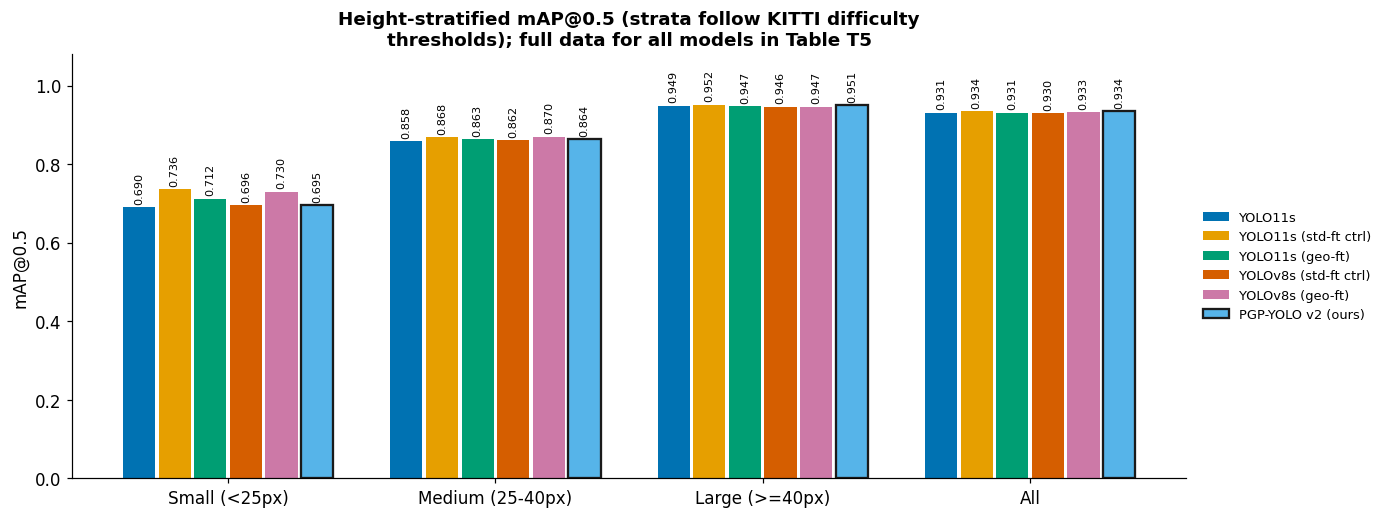

                Model  Small (<25px)  Medium (25-40px)  Large (>=40px)    All  PG-Filter tau  All +PG-Filter
              YOLO11s         0.6898            0.8581          0.9487 0.9310            1.2          0.9310
              YOLOv8s         0.6833            0.8619          0.9478 0.9306            1.2          0.9306
          PGP-YOLO v1         0.6654            0.8537          0.9496 0.9305            1.2          0.9305
     YOLO11s (geo-ft)         0.7121            0.8630          0.9475 0.9312            1.0          0.9306
YOLO11s (std-ft ctrl)         0.7363            0.8681          0.9516 0.9341            1.0          0.9341
     YOLOv8s (geo-ft)         0.7300            0.8700          0.9466 0.9325            1.5          0.9325
YOLOv8s (std-ft ctrl)         0.6961            0.8615          0.9464 0.9303            1.0          0.9302
PGP-YOLO-A1geo (ours)         0.6843            0.8568          0.9498 0.9318            1.2          0.9318
   PGP-YOLO v2 (our

In [14]:
# ============================================================================
# CELL 12b — DEEP ANALYSIS: height-stratified AP, corrected confusion matrices,
#            and the PG-Filter (prior-based plausibility filtering)
#
# WHY THIS CELL EXISTS (v2):
#  * KITTI overall mAP is near-saturated (~0.93), compressing model differences.
#    The perspective prior targets SMALL/DISTANT objects, so the honest headline
#    is the height-stratified AP (strata follow KITTI's difficulty thresholds:
#    <25 px, 25-40 px, >=40 px box height).
#  * The Ultralytics confusion matrix returned empty background rows in v1
#    (impossible given recall 0.877), so we recompute it from raw predictions
#    with a transparent matcher.  -> corrected F11/F12
#  * PG-Filter: a training-free use of the SAME prior at test time - detections
#    whose height is geometrically implausible for their image row are removed.
#    tau is tuned on TRAIN images only (no val leakage).
# Everything is cached to results/preds_*.json / analysis_*.json (idempotent).
# ============================================================================

def _predict_cached(name, img_dir, stems, tag, chunk=250):
    """Run (or load cached) full-range predictions for one model.
    Predicts in chunks with a cache checkpoint after each chunk, so a mid-run
    OOM (e.g. from GPU memory not yet released by a training run earlier in
    this Colab session) loses at most one chunk instead of the whole pass."""
    cache = RES_DIR / f"preds_{tag}_{name}.json"
    if cache.exists():
        return json.loads(cache.read_text())
    part = RES_DIR / f"preds_{tag}_{name}.partial.json"
    out = json.loads(part.read_text()) if part.exists() else []
    done_files = {o["file"] for o in out}
    remaining = [s for s in stems if s not in done_files]
    if not remaining:
        cache.write_text(json.dumps(out)); part.unlink(missing_ok=True)
        return out
    wpath = exp_paths(name)["best"]
    if not wpath.exists():
        return None
    free_gpu()   # clear any memory left resident from a prior cell/model
    mdl = YOLO(str(wpath))
    dev = 0 if torch.cuda.is_available() else "cpu"
    for start in range(0, len(remaining), chunk):
        batch = remaining[start:start + chunk]
        for r in mdl.predict([str(img_dir / f"{s}.jpg") for s in batch],
                             imgsz=CFG.IMGSZ, conf=0.001, max_det=300, stream=True,
                             device=dev, half=torch.cuda.is_available(), verbose=False):
            H0, W0 = r.orig_shape
            out.append({"file": Path(r.path).stem, "H": int(H0), "W": int(W0),
                       "boxes": [[int(c), round(float(cf), 5)] + [round(float(v), 2) for v in xy]
                                 for c, cf, xy in zip(r.boxes.cls.tolist(),
                                                      r.boxes.conf.tolist(),
                                                      r.boxes.xyxy.tolist())]})
        part.write_text(json.dumps(out))   # checkpoint after every chunk

    cache.write_text(json.dumps(out))
    part.unlink(missing_ok=True)
    free_gpu(mdl)
    return out

def _load_gt(lbl_dir, stem, H, W):
    """[[cls,x1,y1,x2,y2,h_px], ...] from a YOLO label file."""
    f = lbl_dir / f"{stem}.txt"
    g = []
    if f.exists():
        for ln in f.read_text().splitlines():
            c, xc, yc, w, h = map(float, ln.split())
            g.append([int(c), (xc-w/2)*W, (yc-h/2)*H, (xc+w/2)*W, (yc+h/2)*H, h*H])
    return g

def _iou_mat(a, b):
    a, b = np.array(a, float), np.array(b, float)
    if not len(a) or not len(b):
        return np.zeros((len(a), len(b)))
    ix = (np.minimum(a[:, None, 2], b[None, :, 2]) -
          np.maximum(a[:, None, 0], b[None, :, 0])).clip(0)
    iy = (np.minimum(a[:, None, 3], b[None, :, 3]) -
          np.maximum(a[:, None, 1], b[None, :, 1])).clip(0)
    inter = ix * iy
    ar_a = (a[:, 2]-a[:, 0]) * (a[:, 3]-a[:, 1])
    ar_b = (b[:, 2]-b[:, 0]) * (b[:, 3]-b[:, 1])
    return inter / (ar_a[:, None] + ar_b[None, :] - inter + 1e-9)

def _ap_101(tp, conf, n_gt):
    if n_gt == 0:
        return float("nan")
    if not len(tp):
        return 0.0
    o = np.argsort(-np.array(conf)); tp = np.array(tp, float)[o]
    ctp, cfp = np.cumsum(tp), np.cumsum(1 - tp)
    rec, prec = ctp / n_gt, ctp / (ctp + cfp + 1e-12)
    return float(np.mean([prec[rec >= t].max() if (rec >= t).any() else 0.0
                          for t in np.linspace(0, 1, 101)]))

STRATA = {"Small (<25px)": (0, 25), "Medium (25-40px)": (25, 40),
          "Large (>=40px)": (40, 1e9), "All": (0, 1e9)}

def stratified_ap50(preds, lbl_dir, iou_thr=0.5):
    """COCO-style area-range evaluation, by original-pixel box height."""
    out = {}
    for sname, (lo, hi) in STRATA.items():
        cls_ap = {}
        for ci in range(len(CFG.CLASSES)):
            tps, confs, n_gt = [], [], 0
            for P in preds:
                gt = [g for g in _load_gt(lbl_dir, P["file"], P["H"], P["W"])
                      if g[0] == ci]
                ig = [not (lo <= g[5] < hi) for g in gt]
                n_gt += sum(1 for x in ig if not x)
                pb = sorted([b for b in P["boxes"] if b[0] == ci],
                            key=lambda b: -b[1])
                if not pb:
                    continue
                M = _iou_mat([b[2:6] for b in pb], [g[1:5] for g in gt])
                used = set()
                for pi, b in enumerate(pb):
                    cand = [(M[pi, gi], gi) for gi in range(len(gt))
                            if gi not in used and M[pi, gi] >= iou_thr]
                    real = [c for c in cand if not ig[c[1]]]
                    if real:                       # TP on an in-stratum GT
                        gi = max(real)[1]; used.add(gi)
                        tps.append(1); confs.append(b[1])
                    elif cand:                     # matched an ignored GT -> ignore
                        used.add(max(cand)[1])
                    else:                          # unmatched: FP only if in-stratum
                        if lo <= (b[5] - b[3]) < hi:
                            tps.append(0); confs.append(b[1])
            cls_ap[CFG.CLASSES[ci]] = _ap_101(tps, confs, n_gt)
        vals = [v for v in cls_ap.values() if not np.isnan(v)]
        out[sname] = {"per_class": cls_ap, "mAP50": float(np.mean(vals))}
    return out

def confusion_from_preds(preds, lbl_dir, conf_thr=0.25, iou_thr=0.5):
    nc = len(CFG.CLASSES)
    cm = np.zeros((nc + 1, nc + 1), int)          # rows=pred (+bg), cols=gt (+bg)
    for P in preds:
        gt = _load_gt(lbl_dir, P["file"], P["H"], P["W"])
        pb = sorted([b for b in P["boxes"] if b[1] >= conf_thr], key=lambda b: -b[1])
        M = _iou_mat([b[2:6] for b in pb], [g[1:5] for g in gt])
        used = set()
        for pi, b in enumerate(pb):
            cand = [(M[pi, gi], gi) for gi in range(len(gt))
                    if gi not in used and M[pi, gi] >= iou_thr]
            if cand:
                gi = max(cand)[1]; used.add(gi)
                cm[b[0], gt[gi][0]] += 1
            else:
                cm[b[0], nc] += 1                  # ghost (FP on background)
        for gi, g in enumerate(gt):
            if gi not in used:
                cm[nc, g[0]] += 1                  # missed (FN)
    return cm

def pg_filter(preds, tau):
    """Drop detections whose height is implausible for their ground-contact row."""
    out = []
    for P in preds:
        keep = []
        for b in P["boxes"]:
            cls, h_n = b[0], (b[5] - b[3]) / P["H"]
            yb = min(b[5] / P["H"], 1.0)
            if str(cls) in prior["classes"] and h_n > 1e-4:
                exp_h = prior_h(yb, cls)
                if abs(math.log(h_n / max(exp_h, 1e-4))) > tau:
                    continue
            keep.append(b)
        out.append({**P, "boxes": keep})
    return out

# ---------------------------- run the analysis ------------------------------
free_gpu()   # this cell often runs right after training/eval - start clean
val_stems = sorted(p.stem for p in (DATA_LOCAL / "images/val").glob("*.jpg"))
tr_stems = sorted(p.stem for p in (DATA_LOCAL / "images/train").glob("*.jpg"))[:400]
ANALYZE = [n for n in dict.fromkeys(
    [f"yolo11{CFG.SCALE}", f"yolov8{CFG.SCALE}", "pgp_yolo_full",
     f"yolo11{CFG.SCALE}_geo", f"yolo11{CFG.SCALE}_stdft",
     f"yolov8{CFG.SCALE}_geo", f"yolov8{CFG.SCALE}_stdft",
     "pgp_a1_geo", "pgp_v2", BASELINE_NAME, PROPOSED_NAME])
    if exp_paths(n)["best"].exists()]
print("analyzing:", ANALYZE)

ANALYSIS = {}
for n in ANALYZE:
    aj = RES_DIR / f"analysis_{n}.json"
    if aj.exists() and not CFG.FORCE_REEVAL:
        ANALYSIS[n] = json.loads(aj.read_text()); print(f"[{n}] cached analysis")
        continue
    free_gpu()   # between models: don't let one model's residual memory OOM the next
    preds = _predict_cached(n, DATA_LOCAL / "images/val", val_stems, "val")
    A = {"strat": stratified_ap50(preds, DATA_LOCAL / "labels/val"),
         "cm": confusion_from_preds(preds, DATA_LOCAL / "labels/val").tolist(),
         "cm_names": CFG.CLASSES + ["background"]}
    # ---- PG-Filter: tune tau on TRAIN predictions, evaluate on val ----
    tr_preds = _predict_cached(n, DATA_LOCAL / "images/train", tr_stems, "tr")
    best_tau, best = None, -1
    for tau in [0.6, 0.8, 1.0, 1.2, 1.5, 2.0]:
        s = stratified_ap50(pg_filter(tr_preds, tau), DATA_LOCAL / "labels/train")
        if s["All"]["mAP50"] > best:
            best, best_tau = s["All"]["mAP50"], tau
    filt = stratified_ap50(pg_filter(preds, best_tau), DATA_LOCAL / "labels/val")
    A["pgfilter"] = {"tau": best_tau,
                     "map50_before": A["strat"]["All"]["mAP50"],
                     "map50_after": filt["All"]["mAP50"],
                     "small_before": A["strat"]["Small (<25px)"]["mAP50"],
                     "small_after": filt["Small (<25px)"]["mAP50"]}
    aj.write_text(json.dumps(A)); ANALYSIS[n] = A
    print(f"[{n}] stratified AP done | PG-Filter tau={best_tau} "
          f"mAP50 {A['pgfilter']['map50_before']:.4f}->{A['pgfilter']['map50_after']:.4f}")

# ---------------------------- -----------------------------------
# plot a readable 6-model subset (the full data lives in Table T5); legend sits
# OUTSIDE the axes so no bars are covered
_s = CFG.SCALE
F18_MODELS = [n for n in dict.fromkeys(
    [f"yolo11{_s}", f"yolo11{_s}_stdft", f"yolo11{_s}_geo",
     f"yolov8{_s}_stdft", f"yolov8{_s}_geo", PROPOSED_NAME])
    if n in ANALYSIS][:6]
snames = list(STRATA)
fig, ax = plt.subplots(figsize=(12.5, 4.6))
bw = 0.8 / len(F18_MODELS)
for i, n in enumerate(F18_MODELS):
    vals = [ANALYSIS[n]["strat"][s]["mAP50"] for s in snames]
    bars = ax.bar(np.arange(len(snames)) + i * bw, vals, bw * 0.9, label=pretty(n),
                  color=PAL[i], edgecolor="k" if n == PROPOSED_NAME else "none",
                  linewidth=1.5)
    ax.bar_label(bars, fmt="%.3f", fontsize=7.4, rotation=90, padding=2)
ax.set_xticks(np.arange(len(snames)) + bw * (len(F18_MODELS) - 1) / 2)
ax.set_xticklabels(snames); ax.set_ylabel("mAP@0.5"); ax.set_ylim(0, 1.08)
ax.legend(fontsize=8.5, loc="center left", bbox_to_anchor=(1.005, 0.5),
          frameon=False)
ax.set_title("Height-stratified mAP@0.5 (strata follow KITTI difficulty\n"
             "thresholds); full data for all models in Table T5", fontweight="bold")
savefig(fig, "F18_stratified_ap"); plt.show()

# ---------------------------- Table T5 + verdict ----------------------------
t5 = pd.DataFrame([{"Model": pretty(n),
                    **{s: round(ANALYSIS[n]["strat"][s]["mAP50"], 4) for s in snames},
                    "PG-Filter tau": ANALYSIS[n]["pgfilter"]["tau"],
                    "All +PG-Filter": round(ANALYSIS[n]["pgfilter"]["map50_after"], 4)}
                   for n in ANALYZE])
t5.to_csv(TAB_DIR / "T5_stratified.csv", index=False)
(TAB_DIR / "T5_stratified.tex").write_text(t5.to_latex(
    index=False, label="tab:stratified",
    caption="Height-stratified mAP@0.5 and the effect of prior-based plausibility filtering."))
print(t5.to_string(index=False))

# ---- honest automatic verdict: geometry vs budget, per stratum ----
_g, _f = f"yolo11{_s}_geo", f"yolo11{_s}_stdft"
if _g in ANALYSIS and _f in ANALYSIS:
    print("\nGeo-FT vs the equal-budget Std-FT control (YOLO11, mAP@0.5 per stratum):")
    for s in snames:
        gv = ANALYSIS[_g]["strat"][s]["mAP50"]
        fv = ANALYSIS[_f]["strat"][s]["mAP50"]
        print(f"  {s:<18s} std-ft {fv:.4f}  geo-ft {gv:.4f}  (geo - std {gv-fv:+.4f})")
    print("Interpretation guide: if std-ft wins the Small stratum, mosaic's synthetic "
          "down-scaling\nhelps small-object detection and the 'geometry recovers distant "
          "objects' claim is NOT\nsupported - report the trade-off (mosaic helps AP@0.5 "
          "small; geometry-consistent aug\nhelps strict-IoU localization) instead of a "
          "one-sided claim.")

saved -> figures/F07_map_curves.png|.pdf


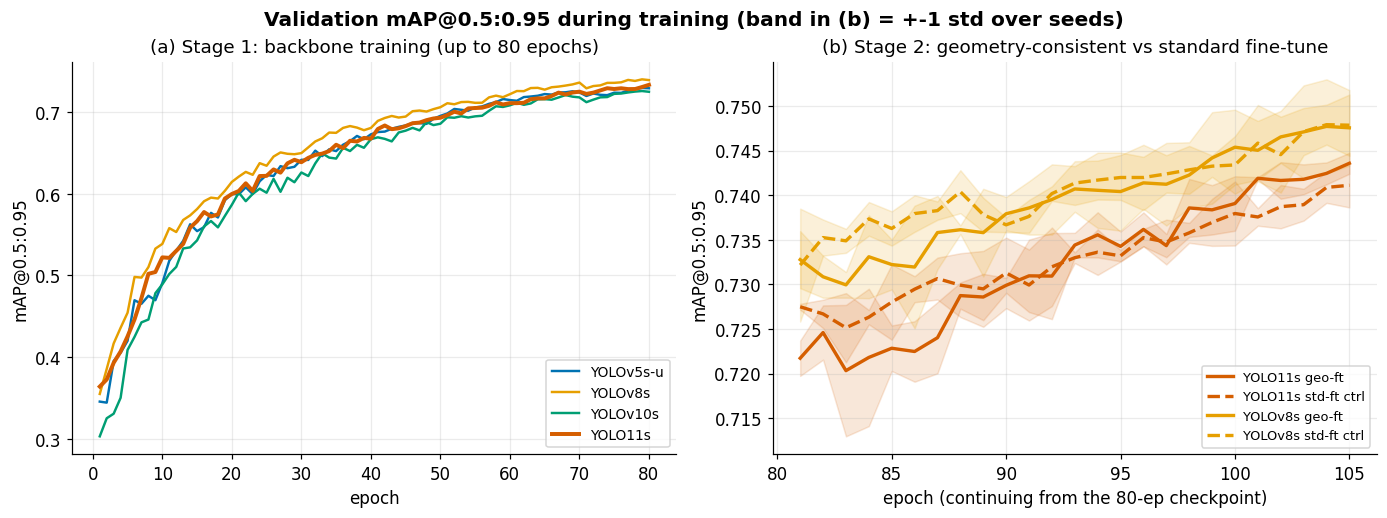

saved -> figures/F08_loss_curves.png|.pdf


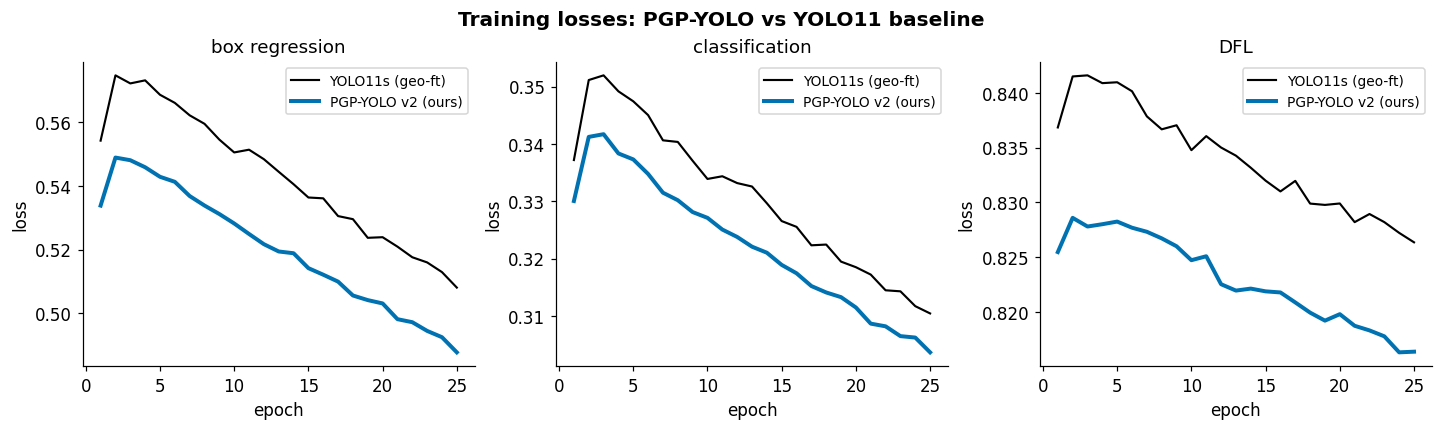

In [15]:
# ============================================================================
# CELL 13 — TRAINING DYNAMICS  ->  Figure F07 (mAP curves), Figure F08 (losses)
# ============================================================================
def read_results_csv(name):
    csv = exp_paths(name)["run"] / "results.csv"
    if not csv.exists():
        return None
    df = pd.read_csv(csv)
    df.columns = [c.strip() for c in df.columns]
    return df

def col_like(df, key):
    hits = [c for c in df.columns if key in c]
    return hits[0] if hits else None

ORDER = [n for n, *_ in experiment_matrix() if n in RESULTS]
STYLE = {n: dict(color=PAL[i % len(PAL)],
                 lw=2.6 if n == PROPOSED_NAME else 1.4,
                 zorder=5 if n == PROPOSED_NAME else 2)
         for i, n in enumerate(ORDER)}

# ---------------- Figure F07: training dynamics, split by the two stages --------
# 17 overlapping curves (7 full trainings + 10 fine-tunes on one axis) were an
# unreadable tangle, with the 25-epoch fine-tunes forming a disconnected cluster.
# The paper reasons in two stages, so the figure now does too, on the headline
# metric only: (a) stage-1 convergence for the 4 architectures; (b) a zoom on the
# stage-2 geo-vs-std comparison the argument rests on (invisible in the old plot),
# with +-1 std seed bands so the reader SEES the effect is consistent.
import re
KEY = "mAP50-95(B)"

def _curve(name):
    df = read_results_csv(name)
    if df is None:
        return None
    c = col_like(df, KEY)
    return df[c].values if c else None

def _family(base):
    """base run + its _s/_scr seed replicates -> (mean, std) per epoch, min-len aligned."""
    cs = [v for n in RESULTS if re.fullmatch(rf"{re.escape(base)}(_(?:s|scr)\d+)?", n)
          for v in [_curve(n)] if v is not None]
    if not cs:
        return None
    L = min(map(len, cs)); A = np.stack([c[:L] for c in cs])
    return A.mean(0), (A.std(0, ddof=1) if len(cs) > 1 else np.zeros(L))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.6))

# panel (a): stage-1 backbone training, the 4 canonical architectures
base4 = [f"yolov5{CFG.SCALE}u", f"yolov8{CFG.SCALE}",
         f"yolov10{CFG.SCALE}", f"yolo11{CFG.SCALE}"]
for i, n in enumerate(base4):
    v = _curve(n)
    if v is None:
        continue
    hero = (n == f"yolo11{CFG.SCALE}")
    a1.plot(np.arange(1, len(v) + 1), v, color=PAL[i], lw=2.6 if hero else 1.6,
            label=pretty(n), zorder=5 if hero else 2)
a1.set(xlabel="epoch", ylabel="mAP@0.5:0.95",
       title="(a) Stage 1: backbone training (up to 80 epochs)")
a1.legend(fontsize=9, loc="lower right"); a1.grid(alpha=0.25)

# panel (b): stage-2 fine-tuning, geo-consistent (solid) vs standard control (dashed)
banded = False
for base, col in [(f"yolo11{CFG.SCALE}", PAL[3]), (f"yolov8{CFG.SCALE}", PAL[1])]:
    for suff, ls, tag in [("_geo", "-", "geo-ft"), ("_stdft", "--", "std-ft ctrl")]:
        fam = _family(base + suff)
        if fam is None:
            continue
        mean, std = fam
        x = 80 + np.arange(1, len(mean) + 1)
        a2.plot(x, mean, ls, color=col, lw=2.2, label=f"{pretty(base)} {tag}")
        if std.any():
            a2.fill_between(x, mean - std, mean + std, color=col, alpha=0.15)
            banded = True
a2.set(xlabel="epoch (continuing from the 80-ep checkpoint)", ylabel="mAP@0.5:0.95",
       title="(b) Stage 2: geometry-consistent vs standard fine-tune")
a2.legend(fontsize=8.5, loc="lower right"); a2.grid(alpha=0.25)
fig.suptitle("Validation mAP@0.5:0.95 during training"
             + (" (band in (b) = +-1 std over seeds)" if banded else ""),
             fontweight="bold")
savefig(fig, "F07_map_curves"); plt.show()

# ---------------- Figure F08: loss curves (proposed vs strongest baseline) ----
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for n in [BASELINE_NAME, PROPOSED_NAME]:
    df = read_results_csv(n)
    if df is None:
        continue
    for a, key, ttl in zip(axes, ["train/box_loss", "train/cls_loss", "train/dfl_loss"],
                           ["box regression", "classification", "DFL"]):
        c = col_like(df, key)
        if c:
            a.plot(df.index + 1, df[c], label=pretty(n), **STYLE.get(n, {}))
            a.set(xlabel="epoch", ylabel="loss", title=ttl)
for a in axes:
    a.legend(fontsize=9)
fig.suptitle("Training losses: PGP-YOLO vs YOLO11 baseline", fontweight="bold")
savefig(fig, "F08_loss_curves"); plt.show()

saved -> figures/F09_benchmark_bars.png|.pdf


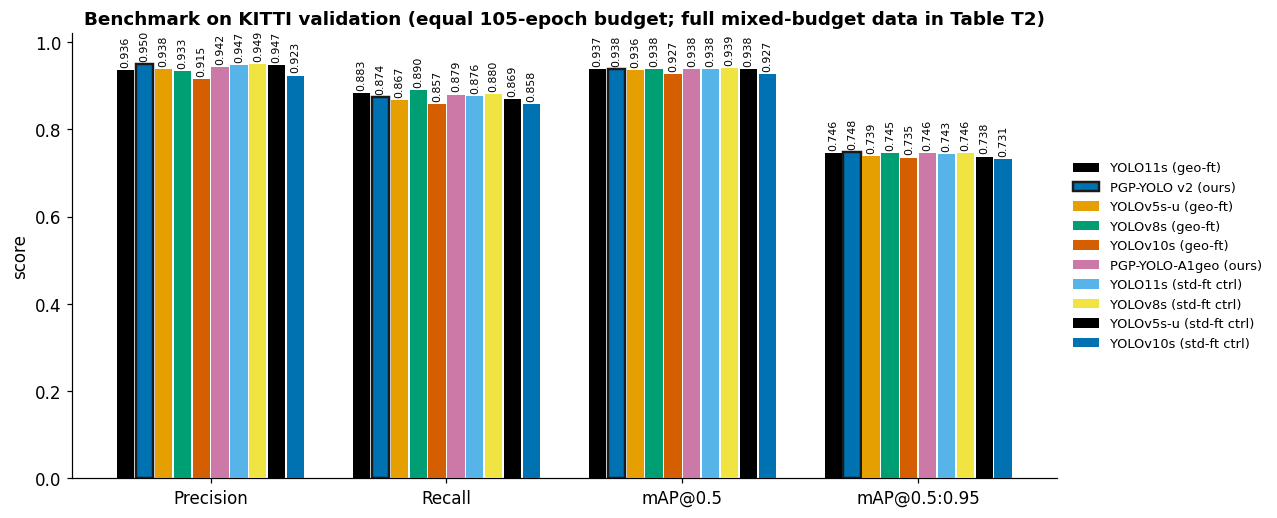

saved -> figures/F10_speed_accuracy.png|.pdf


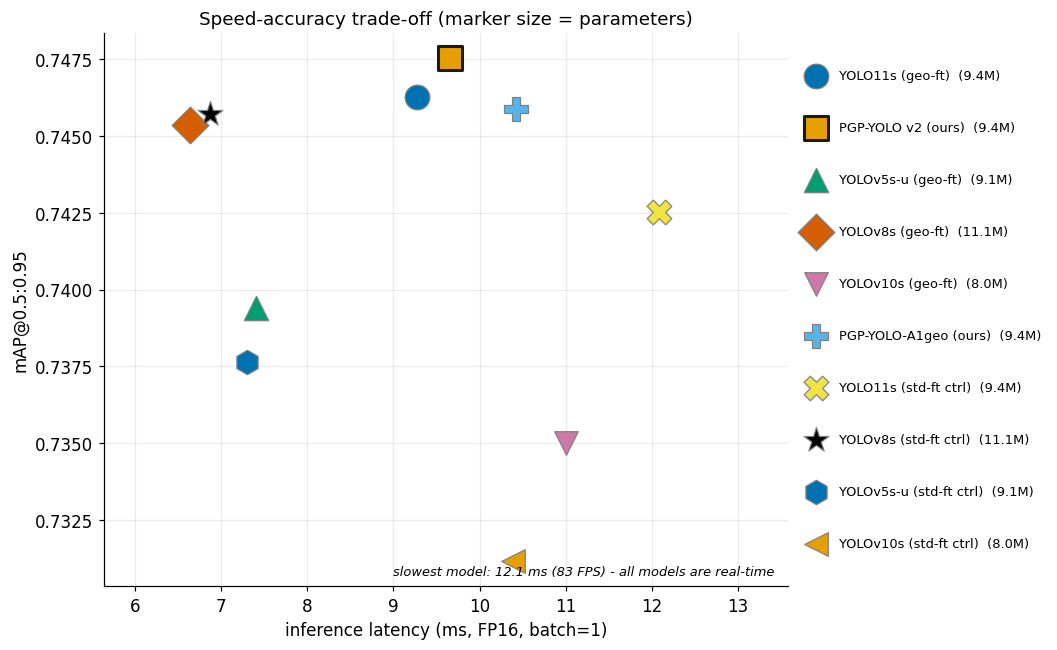

YOLO11s (geo-ft)     mAP50=0.9375  mAP50-95=0.7463  9.3ms  108 FPS  9.42M  21.3 GFLOPs
PGP-YOLO v2 (ours)   mAP50=0.9376  mAP50-95=0.7475  9.7ms  104 FPS  9.42M  21.3 GFLOPs
YOLOv5s-u (geo-ft)   mAP50=0.9362  mAP50-95=0.7394  7.4ms  135 FPS  9.11M  23.8 GFLOPs
YOLOv8s (geo-ft)     mAP50=0.9384  mAP50-95=0.7454  6.6ms  151 FPS  11.13M  28.4 GFLOPs
YOLOv10s (geo-ft)    mAP50=0.9266  mAP50-95=0.7350  11.0ms  91 FPS  8.04M  24.5 GFLOPs
PGP-YOLO-A1geo (ours) mAP50=0.9377  mAP50-95=0.7459  10.4ms  96 FPS  9.42M  21.3 GFLOPs
YOLO11s (std-ft ctrl) mAP50=0.9385  mAP50-95=0.7425  12.1ms  83 FPS  9.42M  21.3 GFLOPs
YOLOv8s (std-ft ctrl) mAP50=0.9395  mAP50-95=0.7457  6.9ms  146 FPS  11.13M  28.4 GFLOPs
YOLOv5s-u (std-ft ctrl) mAP50=0.9378  mAP50-95=0.7376  7.3ms  137 FPS  9.11M  23.8 GFLOPs
YOLOv10s (std-ft ctrl) mAP50=0.9270  mAP50-95=0.7312  10.4ms  96 FPS  8.04M  24.5 GFLOPs


In [28]:
# ============================================================================
# CELL 14 — BENCHMARK  ->  Figure F09 (bars), Figure F10 (speed-accuracy)
# ============================================================================
import re
# only compare full models here: ablation variants (pgp_A*) get figure F15,
# seed repetitions (_s<k>) get the mean+-std table in the tables cell.
# Once the equal-budget (105-epoch) set exists, the FIGURE shows only that fair
# set - mixing 80- and 105-epoch runs in one chart invites reviewer objections.
# The full mixed-budget data (with an explicit Epochs column) stays in Table T2.
_all = [n for n in ORDER
        if not n.startswith("pgp_A") and not is_extval(n)
        and not re.match(r".+_(?:s|scr)\d+$", n)]
_fair = [n for n in _all if n.endswith(("_geo", "_stdft")) or n == "pgp_v2"]
BENCH = _fair if len(_fair) >= 4 else _all

# ---------------- Figure F09: headline benchmark ----------------
metrics_keys = [("precision", "Precision"), ("recall", "Recall"),
                ("map50", "mAP@0.5"), ("map5095", "mAP@0.5:0.95")]
x = np.arange(len(metrics_keys)); bw = 0.8 / len(BENCH)
fig, ax = plt.subplots(figsize=(11.5, 4.6))
for i, n in enumerate(BENCH):
    vals = [RESULTS[n][k] for k, _ in metrics_keys]
    bars = ax.bar(x + i * bw, vals, bw * 0.92, label=pretty(n),
                  color=PAL[ORDER.index(n) % len(PAL)],
                  edgecolor="k" if n == PROPOSED_NAME else "none",
                  linewidth=1.6, zorder=3)
    ax.bar_label(bars, fmt="%.3f", fontsize=7.2, rotation=90, padding=2)
ax.set_xticks(x + bw * (len(BENCH) - 1) / 2)
ax.set_xticklabels([l for _, l in metrics_keys])
ax.set_ylim(0, 1.02); ax.set_ylabel("score")
ax.legend(fontsize=8.5, loc="center left", bbox_to_anchor=(1.005, 0.5), frameon=False)
_budget = "equal 105-epoch budget" if BENCH and BENCH[0].endswith(("_geo", "_stdft")) \
          or "pgp_v2" in BENCH else "identical training protocol"
ax.set_title(f"Benchmark on KITTI validation ({_budget}; "
             "full mixed-budget data in Table T2)", fontweight="bold")
savefig(fig, "F09_benchmark_bars"); plt.show()

# ---------------- Figure F10: speed-accuracy trade-off ----------------
# Legend-based design: on-point labels collided in the dense <13 ms region, so
# each model gets a distinct color+marker pair resolved in a legend outside the
# axes. Axis is fitted to the data (the old fixed 30-FPS line wasted half the
# plot; all models are comfortably real-time, stated in the annotation instead).
fig, ax = plt.subplots(figsize=(9.5, 5.8))
MARKERS = ["o", "s", "^", "D", "v", "P", "X", "*", "h", "<", ">", "p"]
lats = [RESULTS[n]["latency_ms"]["inference"] for n in BENCH]
for i, n in enumerate(BENCH):
    r = RESULTS[n]
    ax.scatter(r["latency_ms"]["inference"], r["map5095"],
               s=110 + r["params_M"] * 16,
               color=PAL[i % len(PAL)], marker=MARKERS[i % len(MARKERS)],
               edgecolor="k" if n == PROPOSED_NAME else "gray",
               linewidth=2.0 if n == PROPOSED_NAME else 0.8, zorder=3,
               label=f"{pretty(n)}  ({r['params_M']:.1f}M)")
ax.set(xlabel="inference latency (ms, FP16, batch=1)", ylabel="mAP@0.5:0.95",
       title="Speed-accuracy trade-off (marker size = parameters)")
ax.set_xlim(min(lats) - 1.0, max(lats) + 1.5)
ax.grid(alpha=0.25)
worst_fps = 1000.0 / max(lats)
ax.annotate(f"slowest model: {max(lats):.1f} ms ({worst_fps:.0f} FPS) - "
            "all models are real-time", xy=(0.98, 0.02),
            xycoords="axes fraction", ha="right", fontsize=8.5, style="italic")
ax.legend(fontsize=8.5, loc="center left", bbox_to_anchor=(1.005, 0.5), labelspacing=3,
          frameon=False)
savefig(fig, "F10_speed_accuracy"); plt.show()

for n in BENCH:
    r = RESULTS[n]
    print(f"{pretty(n):<20s} mAP50={r['map50']:.4f}  mAP50-95={r['map5095']:.4f}  "
          f"{r['latency_ms']['inference']:.1f}ms  {r['fps_inference']:.0f} FPS  "
          f"{r['params_M']:.2f}M  {r['gflops']:.1f} GFLOPs")

saved -> figures/F11_confusion.png|.pdf


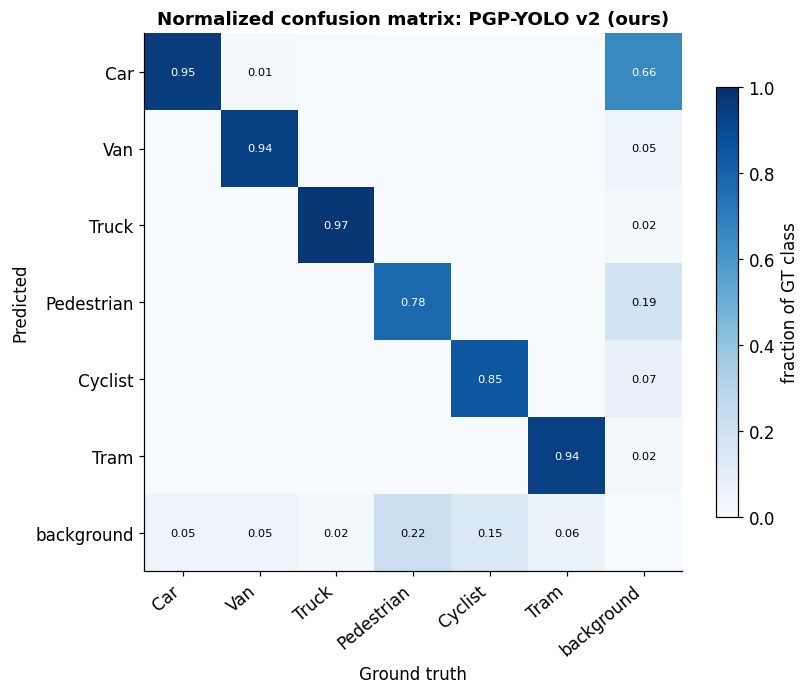

saved -> figures/F12_confusion.png|.pdf


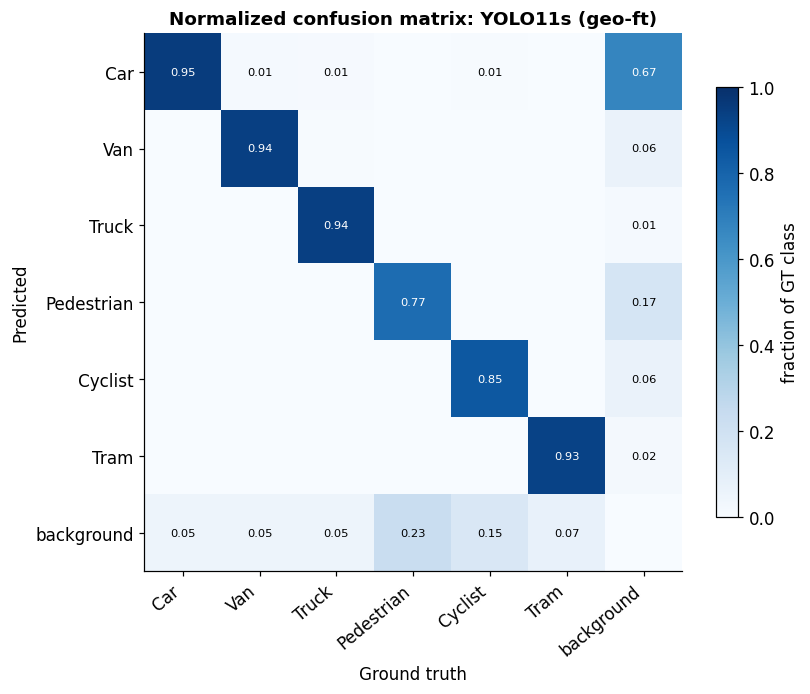

YOLO11s (geo-ft)     missed objects (FN): 576   ghost detections (FP): 727
PGP-YOLO v2 (ours)   missed objects (FN): 555   ghost detections (FP): 737


In [17]:
# ============================================================================
# CELL 15 — CONFUSION MATRICES  ->  Figure F11 (proposed), Figure F12 (baseline)
# ============================================================================
# Clean up stale confusion figures first. Earlier runs embedded the model name in
# the filename (F11_confusion_<name>), so when the eval cell upgrades the headline
# pair (pgp_yolo_full->pgp_v2, yolo11s->yolo11s_geo) the OLD files were orphaned
# on Drive and never overwritten - they showed up as empty leftovers. We now write
# canonical names (F11_confusion / F12_confusion) and delete every old variant.
for _stale in list(FIG_DIR.glob("F11_confusion*")) + list(FIG_DIR.glob("F12_confusion*")):
    if _stale.name not in ("F11_confusion.png", "F11_confusion.pdf",
                           "F12_confusion.png", "F12_confusion.pdf"):
        _stale.unlink(missing_ok=True)
        print(f"removed stale confusion figure: {_stale.name}")

def plot_confusion(name, fig_id):
    # prefer the corrected matrix from the transparent matcher (Cell 12b):
    # the Ultralytics-extracted matrix had empty background rows in v1.
    if name in globals().get("ANALYSIS", {}):
        M = np.array(ANALYSIS[name]["cm"], dtype=float)
        labels = ANALYSIS[name]["cm_names"]
    elif (RES_DIR / f"analysis_{name}.json").exists():
        A = json.loads((RES_DIR / f"analysis_{name}.json").read_text())
        M, labels = np.array(A["cm"], dtype=float), A["cm_names"]
    else:
        r = RESULTS.get(name)
        if not r or "confusion" not in r:
            print(f"no confusion matrix for {name}"); return
        M = np.array(r["confusion"], dtype=float)
        labels = r["confusion_names"]
    Mn = M / M.sum(axis=0, keepdims=True).clip(min=1e-9)     # column-normalized (per GT)
    fig, ax = plt.subplots(figsize=(7.4, 6.2))
    im = ax.imshow(Mn, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=40, ha="right")
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
    ax.set(xlabel="Ground truth", ylabel="Predicted")
    for i in range(len(labels)):
        for j in range(len(labels)):
            if Mn[i, j] > 0.005:
                ax.text(j, i, f"{Mn[i, j]:.2f}", ha="center", va="center", fontsize=7.5,
                        color="white" if Mn[i, j] > 0.55 else "black")
    fig.colorbar(im, ax=ax, shrink=0.8, label="fraction of GT class")
    ax.set_title(f"Normalized confusion matrix: {pretty(name)}",
                 fontweight="bold")
    # canonical, model-independent filename so it is always overwritten in place
    savefig(fig, f"{fig_id}_confusion"); plt.show()

plot_confusion(PROPOSED_NAME, "F11")
plot_confusion(BASELINE_NAME, "F12")

# quick error-analysis printout for the paper's discussion section
def bg_errors(name):
    if name in globals().get("ANALYSIS", {}):
        M = np.array(ANALYSIS[name]["cm"], dtype=float)
    else:
        r = RESULTS.get(name)
        if not r or "confusion" not in r:
            return None
        M = np.array(r["confusion"], dtype=float)
    missed = M[-1, :-1].sum()          # GT objects predicted as background (FN)
    ghosts = M[:-1, -1].sum()          # background predicted as objects (FP)
    return missed, ghosts

for n in [BASELINE_NAME, PROPOSED_NAME]:
    e = bg_errors(n)
    if e:
        print(f"{pretty(n):<20s} missed objects (FN): {e[0]:.0f}   ghost detections (FP): {e[1]:.0f}")

saved -> figures/F13_pr_curves.png|.pdf


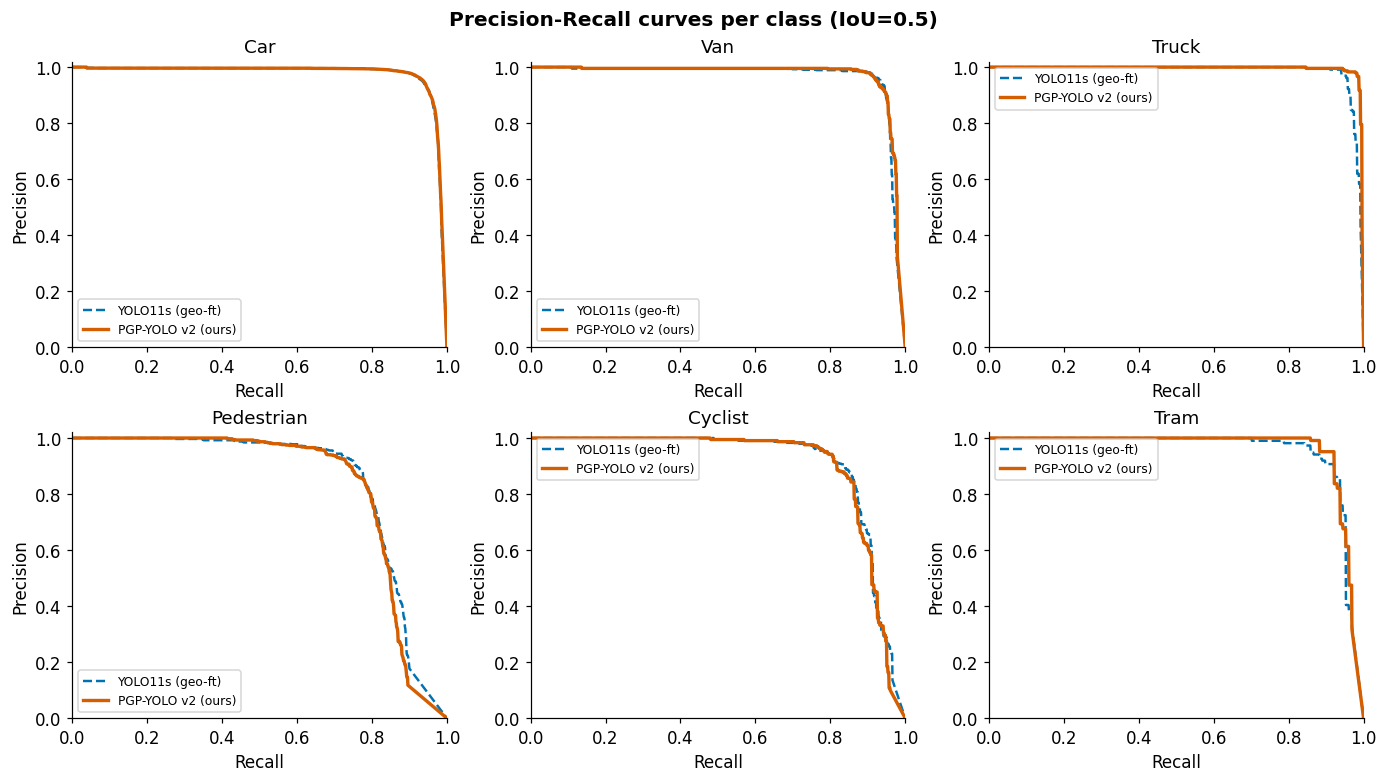

saved -> figures/F14_per_class_ap.png|.pdf


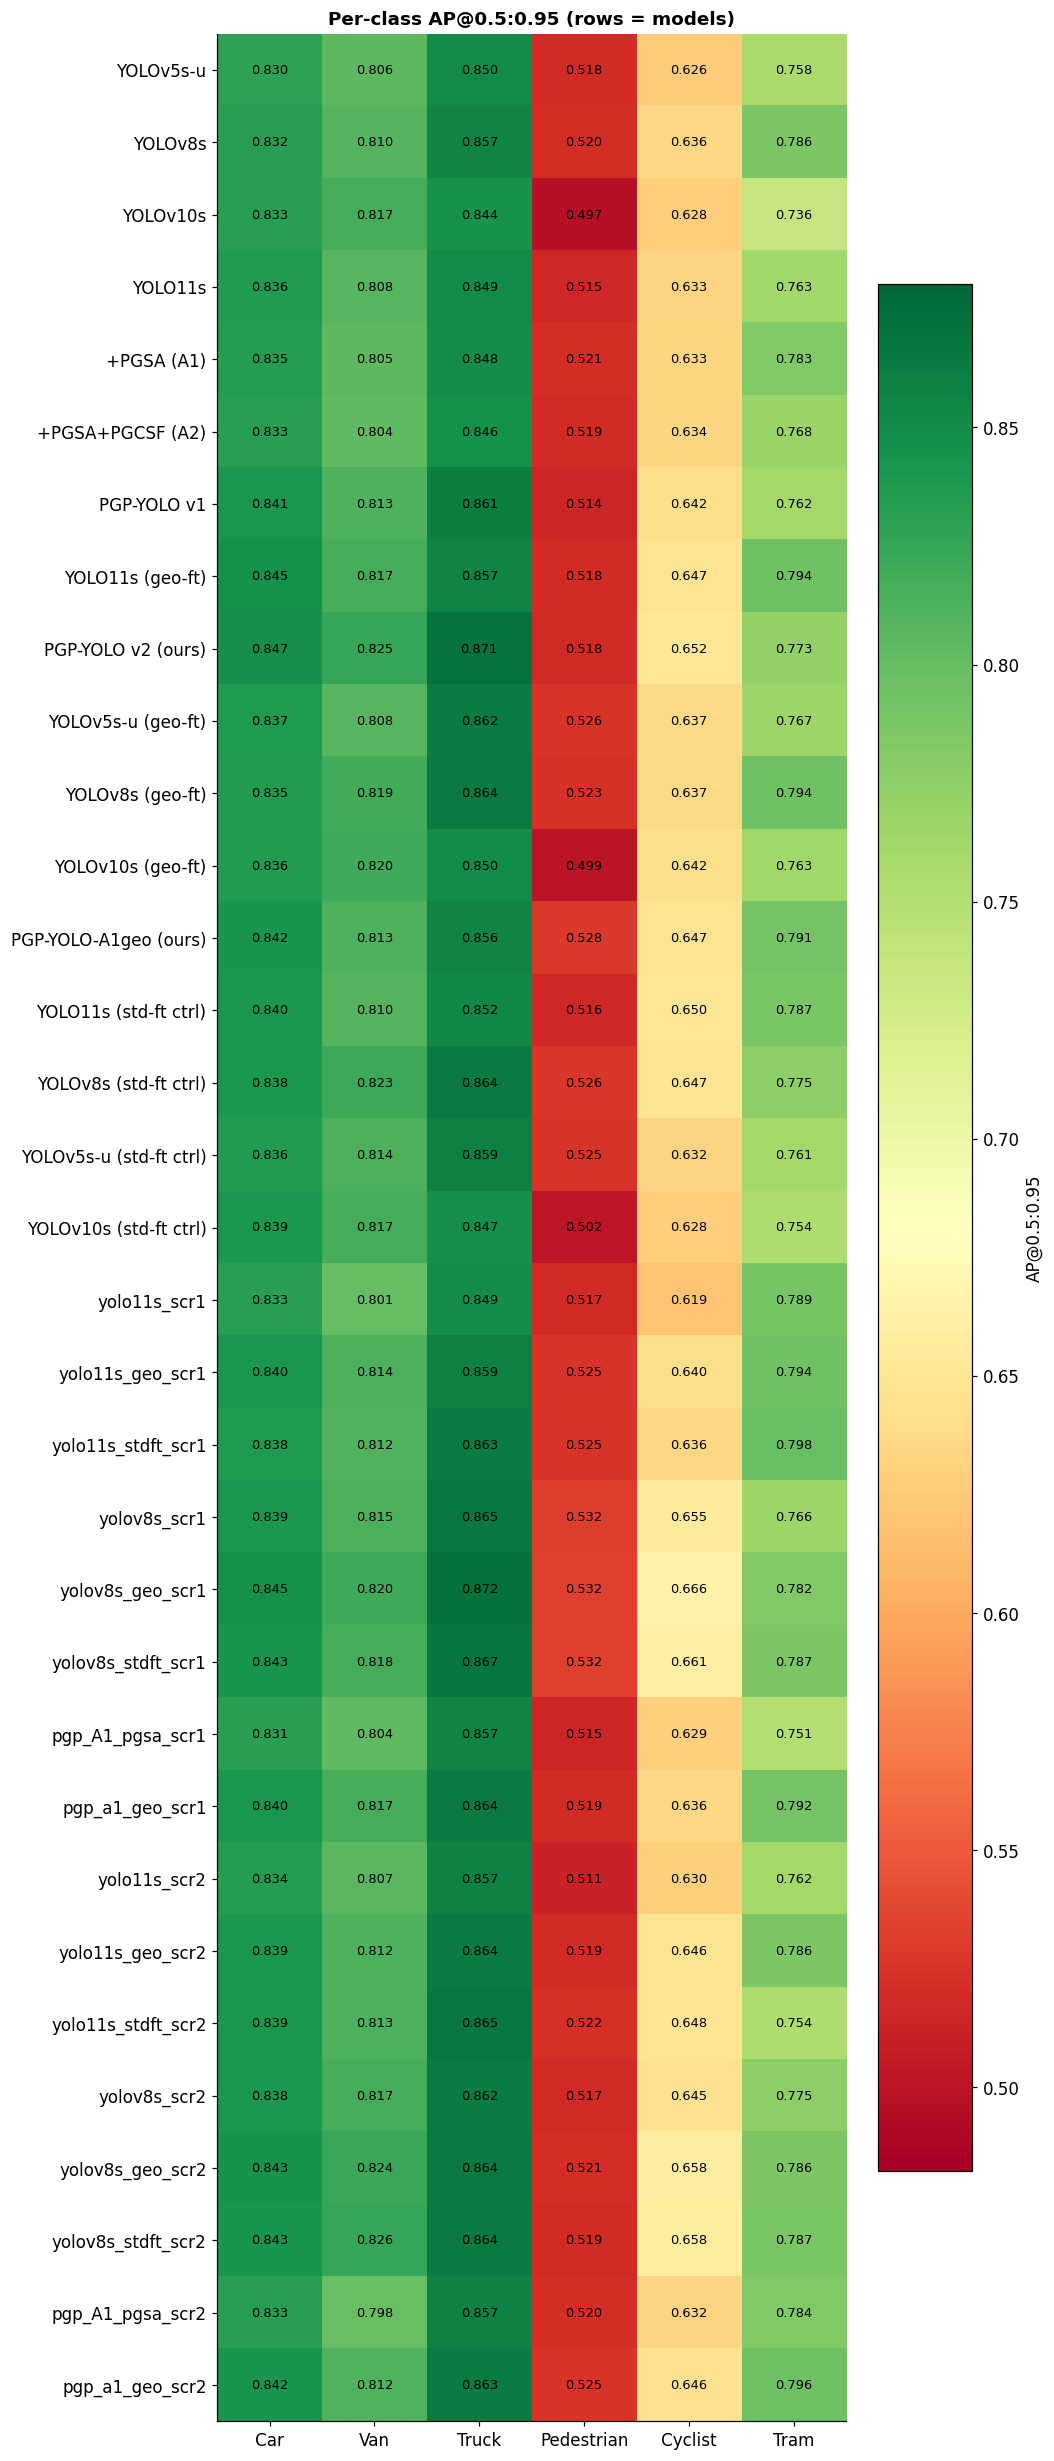

Pedestrian: baseline 0.5181 -> PGP-YOLO 0.5178  (delta -0.0003)
Cyclist: baseline 0.6471 -> PGP-YOLO 0.6516  (delta +0.0045)


In [18]:
# ============================================================================
# CELL 16 — PR CURVES + PER-CLASS AP  ->  Figure F13, Figure F14
# ============================================================================
# ---------------- Figure F13: PR curves per class, ours vs baseline ----------
have_pr = [n for n in [BASELINE_NAME, PROPOSED_NAME]
           if n in RESULTS and "pr_y" in RESULTS[n]]
if len(have_pr) == 2:
    fig, axes = plt.subplots(2, 3, figsize=(12.5, 7))
    for ci, ax in enumerate(axes.flat):
        if ci >= len(CFG.CLASSES):
            ax.axis("off"); continue
        for n, ls in zip(have_pr, ["--", "-"]):
            r = RESULTS[n]
            py = np.array(r["pr_y"])
            if ci < py.shape[0]:
                ax.plot(r["pr_x"], py[ci], ls,
                        color=PAL[0] if n == BASELINE_NAME else PAL[3],
                        lw=1.6 if n == BASELINE_NAME else 2.2, label=pretty(n))
        ax.set(title=CFG.CLASSES[ci], xlabel="Recall", ylabel="Precision",
               xlim=(0, 1), ylim=(0, 1.02))
        ax.legend(fontsize=8)
    fig.suptitle("Precision-Recall curves per class (IoU=0.5)",
                 fontweight="bold")
    savefig(fig, "F13_pr_curves"); plt.show()
else:
    print("PR curve data not cached for both models yet:", have_pr)

# ---------------- Figure F14: per-class AP heatmap across ALL models ----------
rows, names_r = [], []
for n in ORDER:
    if is_extval(n):                 # BDD100K uses different classes -> its own analysis
        continue
    r = RESULTS.get(n)
    if r:
        rows.append([r["ap5095_per_class"].get(c, np.nan) for c in CFG.CLASSES])
        names_r.append(pretty(n))
A = np.array(rows, dtype=float)
fig, ax = plt.subplots(figsize=(9.5, 0.62 * len(rows) + 1.8))
im = ax.imshow(A, cmap="RdYlGn", vmin=np.nanmin(A) * 0.97, vmax=np.nanmax(A) * 1.01,
               aspect="auto")
ax.set_xticks(range(len(CFG.CLASSES))); ax.set_xticklabels(CFG.CLASSES)
ax.set_yticks(range(len(names_r))); ax.set_yticklabels(names_r)
for i in range(A.shape[0]):
    for j in range(A.shape[1]):
        if not np.isnan(A[i, j]):
            ax.text(j, i, f"{A[i, j]:.3f}", ha="center", va="center", fontsize=8.5)
fig.colorbar(im, ax=ax, shrink=0.8, label="AP@0.5:0.95")
ax.set_title("Per-class AP@0.5:0.95 (rows = models)", fontweight="bold")
savefig(fig, "F14_per_class_ap"); plt.show()

# rare-class gain summary for the abstract
if BASELINE_NAME in RESULTS and PROPOSED_NAME in RESULTS:
    for c in ["Pedestrian", "Cyclist"]:
        b = RESULTS[BASELINE_NAME]["ap5095_per_class"].get(c, np.nan)
        o = RESULTS[PROPOSED_NAME]["ap5095_per_class"].get(c, np.nan)
        print(f"{c}: baseline {b:.4f} -> PGP-YOLO {o:.4f}  (delta {o-b:+.4f})")

saved -> figures/F15_ablation.png|.pdf


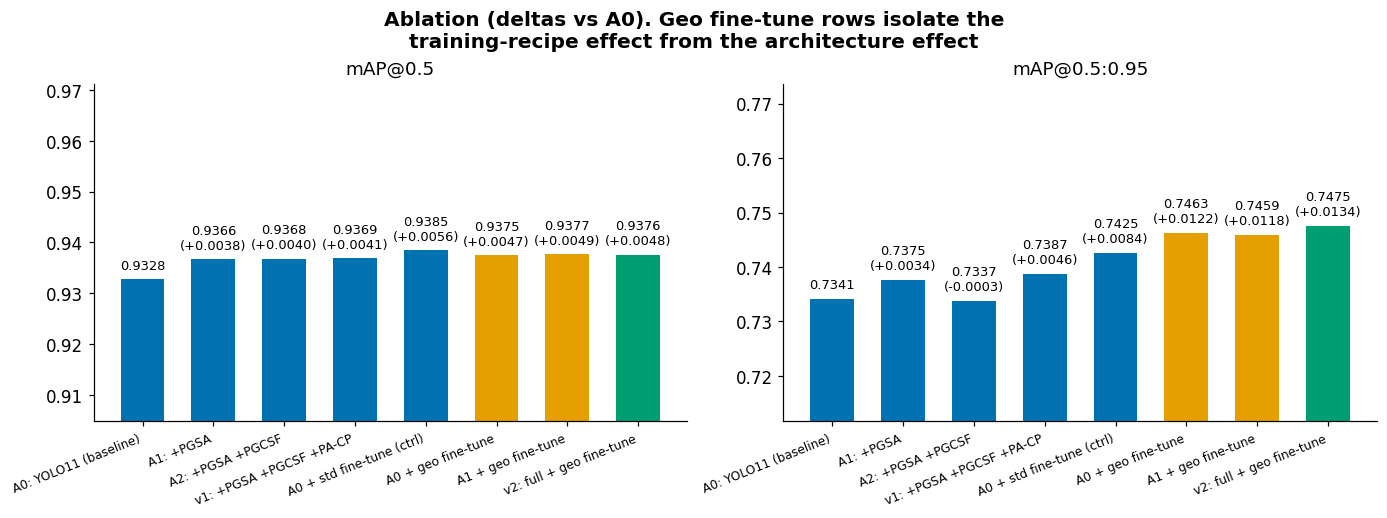

            Configuration PGSA PGCSF PA-CP Std-FT Geo-FT  mAP@0.5  mAP@0.5:0.95  Params (M)  Latency (ms)
    A0: YOLO11 (baseline)                                  0.9328        0.7341        9.42          11.6
                A1: +PGSA    x                             0.9366        0.7375        9.42           9.3
         A2: +PGSA +PGCSF    x     x                       0.9368        0.7337        9.42          10.2
  v1: +PGSA +PGCSF +PA-CP    x     x     x                 0.9369        0.7387        9.42           9.7
A0 + std fine-tune (ctrl)                       x          0.9385        0.7425        9.42          12.1
       A0 + geo fine-tune                              x   0.9375        0.7463        9.42           9.3
       A1 + geo fine-tune    x                         x   0.9377        0.7459        9.42          10.4
 v2: full + geo fine-tune    x     x     x             x   0.9376        0.7475        9.42           9.7
saved -> figures/F16_qualitative.png|.pdf


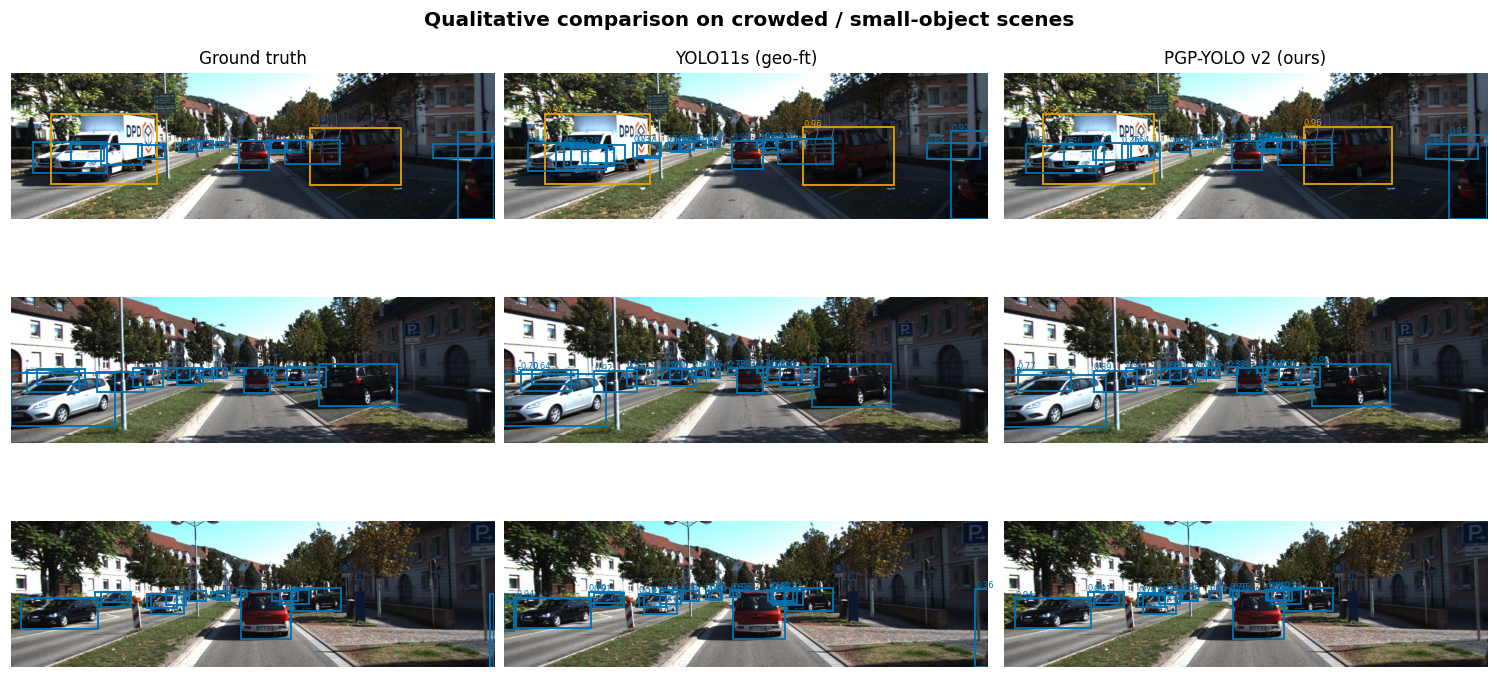

In [19]:
# ============================================================================
# CELL 17 — ABLATION + QUALITATIVE  ->  Figure F15, Figure F16 (+ Table T3)
# ============================================================================
# rows: (exp name, label, component marks)
_s = CFG.SCALE
ABL = [(f"yolo11{_s}", "A0: YOLO11 (baseline)",           dict()),
       ("pgp_A1_pgsa", "A1: +PGSA",                        dict(PGSA="x")),
       ("pgp_A2_pgsa_pgcsf", "A2: +PGSA +PGCSF",           dict(PGSA="x", PGCSF="x")),
       ("pgp_yolo_full", "v1: +PGSA +PGCSF +PA-CP",        dict(PGSA="x", PGCSF="x", PACP="x")),
       (f"yolo11{_s}_stdft", "A0 + std fine-tune (ctrl)",  dict(STD="x")),
       (f"yolo11{_s}_geo", "A0 + geo fine-tune",           dict(GEO="x")),
       ("pgp_a1_geo", "A1 + geo fine-tune",                dict(PGSA="x", GEO="x")),
       ("pgp_v2", "v2: full + geo fine-tune",              dict(PGSA="x", PGCSF="x", PACP="x", GEO="x"))]
abl_have = [(n, l, mk) for n, l, mk in ABL if n in RESULTS]

# ---------------- Figure F15: ablation study ----------------
if len(abl_have) >= 2:
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.6))
    xs = np.arange(len(abl_have))
    for a, key, ttl in [(a1, "map50", "mAP@0.5"), (a2, "map5095", "mAP@0.5:0.95")]:
        vals = [RESULTS[n][key] for n, _, _ in abl_have]
        cols = [PAL[2] if n == PROPOSED_NAME else
                (PAL[1] if mk.get("GEO") else PAL[0]) for n, _, mk in abl_have]
        a.bar(xs, vals, color=cols, width=0.62)
        for i, v in enumerate(vals):
            d = v - vals[0]
            a.text(i, v + 0.002, f"{v:.4f}\n({d:+.4f})" if i else f"{v:.4f}",
                   ha="center", fontsize=8.5)
        a.set_xticks(xs)
        a.set_xticklabels([l for _, l, _ in abl_have], rotation=22, ha="right",
                          fontsize=8)
        a.set_title(ttl); a.set_ylim(min(vals) * 0.97, max(vals) * 1.035)
    fig.suptitle("Ablation (deltas vs A0). Geo fine-tune rows isolate the\n"
                 "training-recipe effect from the architecture effect", fontweight="bold")
    savefig(fig, "F15_ablation"); plt.show()

    t3 = pd.DataFrame({
        "Configuration": [l for _, l, _ in abl_have],
        "PGSA":  [mk.get("PGSA", "") for _, _, mk in abl_have],
        "PGCSF": [mk.get("PGCSF", "") for _, _, mk in abl_have],
        "PA-CP": [mk.get("PACP", "") for _, _, mk in abl_have],
        "Std-FT": [mk.get("STD", "") for _, _, mk in abl_have],
        "Geo-FT": [mk.get("GEO", "") for _, _, mk in abl_have],
        "mAP@0.5": [round(RESULTS[n]["map50"], 4) for n, _, _ in abl_have],
        "mAP@0.5:0.95": [round(RESULTS[n]["map5095"], 4) for n, _, _ in abl_have],
        "Params (M)": [round(RESULTS[n]["params_M"], 2) for n, _, _ in abl_have],
        "Latency (ms)": [round(RESULTS[n]["latency_ms"]["inference"], 1)
                         for n, _, _ in abl_have]})
    t3.to_csv(TAB_DIR / "T3_ablation.csv", index=False)
    (TAB_DIR / "T3_ablation.tex").write_text(
        t3.to_latex(index=False, caption="Ablation study of PGP-YOLO components.",
                    label="tab:ablation"))
    print(t3.to_string(index=False))

# ---------------- Figure F16: qualitative comparison on hard scenes ----------
qb, qp = exp_paths(BASELINE_NAME)["best"], exp_paths(PROPOSED_NAME)["best"]
if qb.exists() and qp.exists():
    # hardest val images = many objects incl. very small ones
    df_va["small"] = df_va.h < 0.055
    hard = (df_va.groupby("img").agg(n=("cls", "size"), s=("small", "sum"))
            .query("s >= 2").sort_values("n", ascending=False).index[:3])
    mb, mp_ = YOLO(str(qb)), YOLO(str(qp))
    dev = 0 if torch.cuda.is_available() else "cpu"
    fig, axes = plt.subplots(len(hard), 3, figsize=(13.5, 1.72 * len(hard) + 1.2),
                             squeeze=False)
    for r_i, iid in enumerate(hard):
        ipath = DATA_LOCAL / f"images/val/{iid}.jpg"
        img = plt.imread(ipath); Hh, Ww = img.shape[:2]
        # column 0: ground truth
        axes[r_i, 0].imshow(img)
        for _, b in df_va[df_va.img == iid].iterrows():
            axes[r_i, 0].add_patch(mpatches.Rectangle(
                ((b.xc - b.w/2) * Ww, (b.yc - b.h/2) * Hh), b.w * Ww, b.h * Hh,
                fill=False, edgecolor=PAL[int(b.cls)], lw=1.2))
        # columns 1-2: predictions
        for c_i, mdl in enumerate([mb, mp_], start=1):
            axes[r_i, c_i].imshow(img)
            pr = mdl.predict(str(ipath), imgsz=CFG.IMGSZ, conf=0.25, device=dev,
                             verbose=False)[0]
            for bx, cl, cf in zip(pr.boxes.xyxy.cpu().numpy(),
                                  pr.boxes.cls.cpu().numpy(),
                                  pr.boxes.conf.cpu().numpy()):
                axes[r_i, c_i].add_patch(mpatches.Rectangle(
                    (bx[0], bx[1]), bx[2]-bx[0], bx[3]-bx[1], fill=False,
                    edgecolor=PAL[int(cl)], lw=1.2))
                axes[r_i, c_i].text(bx[0], bx[1] - 2, f"{cf:.2f}", fontsize=5.5,
                                    color=PAL[int(cl)])
        for c_i, ttl in enumerate(["Ground truth", pretty(BASELINE_NAME),
                                   pretty(PROPOSED_NAME)]):
            axes[r_i, c_i].axis("off")
            if r_i == 0:
                axes[r_i, c_i].set_title(ttl, fontsize=11)
    fig.suptitle("Qualitative comparison on crowded / small-object scenes",
                 fontweight="bold")
    savefig(fig, "F16_qualitative"); plt.show()
    del mb, mp_; gc.collect(); torch.cuda.empty_cache()
else:
    print("train baseline + proposed first for the qualitative figure")

saved -> figures/F17_learned_gates.png|.pdf


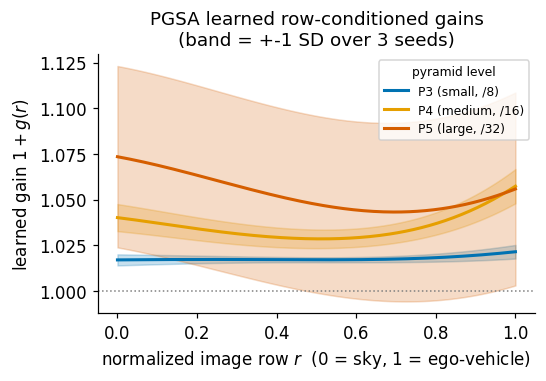

gate figure from 3 seed model(s): ['pgp_a1_geo', 'pgp_a1_geo_scr1', 'pgp_a1_geo_scr2']
P3 gain at horizon (r=0.49): 1.017 | at r=0.95: 1.021  (near 1.0 and flat => the module stayed near-inert)


In [20]:
# ============================================================================
# CELL 18 - INTERPRETABILITY  ->  Figure F17: what did the learned gate learn?
# Reads the content-independent PGSA gate as a function of image row and plots
# the MEAN with an across-seed +-1 SD error band (advisor #7). If only one seed
# model exists the band collapses to the min/max over channel groups. Uses a
# single, near-square panel sized for a double-column journal page.
# ============================================================================
from pgp_modules import PGSA, PGCSF, _row_feats

def _seed_variants(base):
    names = [base] + [n for n in RESULTS if re.fullmatch(rf"{re.escape(base)}_(?:s|scr)\d+", n)]
    return [n for n in names if exp_paths(n)["best"].exists()]

# prefer whichever PGSA-bearing family has the most seed replicates
_cands = [PROPOSED_NAME, "pgp_a1_geo", "pgp_A1_pgsa"]
_fam = max(_cands, key=lambda b: len(_seed_variants(b)))
_models = _seed_variants(_fam)
H = 200; r = np.linspace(0, 1, H)

def _gate_curves(name):
    """per-level PGSA gain 1+g(r) (mean over channel groups) for one model; also
    return the channel-group spread so a single-seed plot still shows a band."""
    mdl = YOLO(str(exp_paths(name)["best"])).model.float().cpu().eval()
    sas = [m for m in mdl.modules() if isinstance(m, PGSA)]
    mean_out, lo_out, hi_out = {}, {}, {}
    with torch.no_grad():
        f = _row_feats(H, "cpu", torch.float32)
        for m, lbl in zip(sas, ["P3 (small, /8)", "P4 (medium, /16)", "P5 (large, /32)"]):
            lv = torch.zeros(H, 3); lv[:, m.level] = 1.0
            g = torch.tanh(m.mlp(torch.cat([f, lv], 1)))            # (H, K)
            mean_out[lbl] = 1 + g.mean(1).numpy()
            lo_out[lbl] = 1 + g.min(1).values.numpy()
            hi_out[lbl] = 1 + g.max(1).values.numpy()
    del mdl; gc.collect()
    return mean_out, lo_out, hi_out

if not _models:
    print("no gate-bearing model trained yet")
else:
    curves = [_gate_curves(n) for n in _models]
    levels = list(curves[0][0].keys())
    n_seeds = len(_models)
    fig, ax = plt.subplots(figsize=(5.0, 3.6))
    for lvl, col in zip(levels, [PAL[0], PAL[1], PAL[3]]):
        M = np.stack([c[0][lvl] for c in curves])                  # (n_seeds, H)
        mean = M.mean(0)
        ax.plot(r, mean, color=col, lw=2.0, label=lvl)
        if n_seeds > 1:                                            # across-seed +-1 SD band
            sd = M.std(0, ddof=1)
            ax.fill_between(r, mean - sd, mean + sd, color=col, alpha=0.22)
        else:                                                     # single seed: channel-group spread
            ax.fill_between(r, curves[0][1][lvl], curves[0][2][lvl], color=col, alpha=0.14)
    ax.axhline(1.0, color="gray", ls=":", lw=1)
    band = f"+-1 SD over {n_seeds} seeds" if n_seeds > 1 else "min/max over channel groups"
    ax.set(xlabel="normalized image row $r$  (0 = sky, 1 = ego-vehicle)",
           ylabel="learned gain $1+g(r)$",
           title=f"PGSA learned row-conditioned gains\n(band = {band})")
    ax.legend(fontsize=8, title="pyramid level", title_fontsize=8)
    fig.tight_layout()
    savefig(fig, "F17_learned_gates"); plt.show()

    # quantitative read-out for the paper text (mean over the seed models)
    hz = prior["pooled"]["y"][int(np.argmin(prior["pooled"]["h_med"]))]
    p3 = np.stack([c[0][levels[0]] for c in curves]).mean(0)
    print(f"gate figure from {n_seeds} seed model(s): {_models}")
    print(f"P3 gain at horizon (r={hz:.2f}): {p3[int(hz*(H-1))]:.3f} | "
          f"at r=0.95: {p3[int(0.95*(H-1))]:.3f}  "
          f"(near 1.0 and flat => the module stayed near-inert)")

TABLE T2 - Benchmark
                  Model  Epochs  Params (M)  GFLOPs  Precision  Recall  mAP@0.5  mAP@0.5:0.95  Latency (ms)   FPS
              YOLOv5s-u      80        9.11    23.8     0.9329  0.8766   0.9339        0.7313           7.8 128.0
                YOLOv8s      80       11.13    28.4     0.9390  0.8783   0.9363        0.7402           6.7 150.0
               YOLOv10s      80        8.04    24.5     0.9251  0.8370   0.9228        0.7258          10.8  92.0
                YOLO11s      80        9.42    21.3     0.9268  0.8771   0.9328        0.7341          11.6  87.0
            PGP-YOLO v1      80        9.42    21.3     0.9397  0.8772   0.9369        0.7387           9.7 103.0
       YOLO11s (geo-ft)     105        9.42    21.3     0.9359  0.8827   0.9375        0.7463           9.3 108.0
     PGP-YOLO v2 (ours)     105        9.42    21.3     0.9497  0.8738   0.9376        0.7475           9.7 104.0
     YOLOv5s-u (geo-ft)     105        9.11    23.8     0.9380  0.8

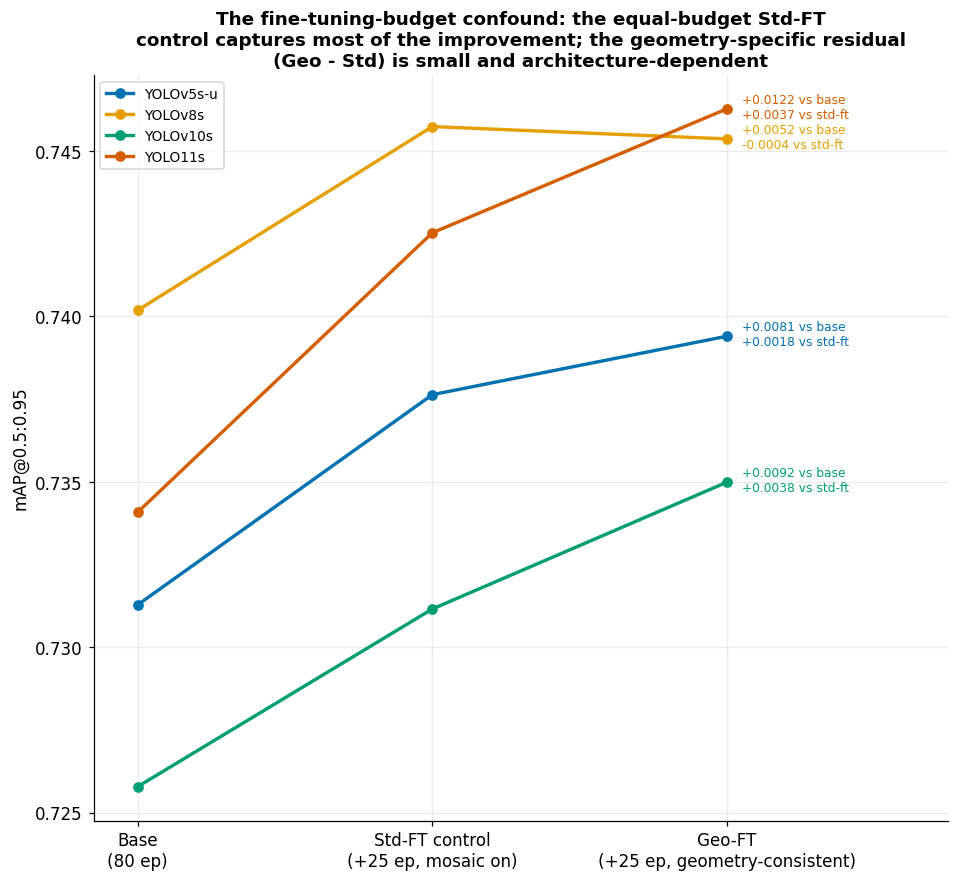


Seed robustness, mAP@0.5:0.95 (mean +- std over stage-2 seeds):
  +PGSA (A1)                 0.7353 +- 0.0037  (n=3)
  PGP-YOLO-A1geo (ours)      0.7458 +- 0.0012  (n=3)
  YOLO11s                    0.7341 +- 0.0006  (n=3)
  YOLO11s (geo-ft)           0.7452 +- 0.0010  (n=3)
  YOLO11s (std-ft ctrl)      0.7426 +- 0.0026  (n=3)
  YOLOv8s                    0.7427 +- 0.0026  (n=3)
  YOLOv8s (geo-ft)           0.7491 +- 0.0037  (n=3)
  YOLOv8s (std-ft ctrl)      0.7488 +- 0.0028  (n=3)

Geometry-specific residual (Geo-FT minus Std-FT), paired by seed:
  YOLO11s      Geo-Std = +0.0026 +- 0.0023  (n=3, seeds=[0, 1, 2]) -> within noise (n.s.)
  YOLOv8s      Geo-Std = +0.0003 +- 0.0011  (n=3, seeds=[0, 1, 2]) -> negligible (< 0.1 pt)
Report the mean+-std numbers in the paper instead of single-run values;
a residual counts as an 'architecture effect' only if it clears BOTH the
2-sigma and 0.1-point bars; otherwise it is a budget effect. This honest
rule IS the paper's contribution - do not so

In [31]:
# ============================================================================
# CELL 19 — TABLES T2 + T4 (CSV + LaTeX) and artifact manifest
# ============================================================================
import re

def total_epochs(n):
    """Stage-1 (80) + stage-2 (25) if the run is a fine-tune - shown in T2
    so the epoch budgets are transparent (fair-comparison requirement)."""
    return CFG.EPOCHS + (CFG.GEO_EPOCHS if (n.endswith(("_geo", "_stdft"))
                                            or n == "pgp_v2") else 0)

# ---------------- Table T2: main benchmark ----------------
rows = []
for n in [x for x in ORDER if not x.startswith("pgp_A") and not is_extval(x)
          and not re.match(r".+_(?:s|scr)\d+$", x)]:
    r = RESULTS[n]
    rows.append({
        "Model": pretty(n),
        "Epochs": total_epochs(n),
        "Params (M)": round(r["params_M"], 2),
        "GFLOPs": round(r["gflops"], 1),
        "Precision": round(r["precision"], 4),
        "Recall": round(r["recall"], 4),
        "mAP@0.5": round(r["map50"], 4),
        "mAP@0.5:0.95": round(r["map5095"], 4),
        "Latency (ms)": round(r["latency_ms"]["inference"], 1),
        "FPS": round(r["fps_inference"], 0),
    })
t2 = pd.DataFrame(rows)
t2.to_csv(TAB_DIR / "T2_benchmark.csv", index=False)
(TAB_DIR / "T2_benchmark.tex").write_text(t2.to_latex(
    index=False, label="tab:benchmark",
    caption="Benchmark on the KITTI validation split (identical training protocol; "
            "latency: FP16, batch 1, single GPU)."))
print("TABLE T2 - Benchmark\n" + t2.to_string(index=False))

# ---------------- Table T4: per-class AP@0.5 ----------------
rows = []
for n in [x for x in ORDER if not is_extval(x)]:
    r = RESULTS[n]
    row = {"Model": pretty(n)}
    row.update({c: round(r["ap50_per_class"].get(c, float("nan")), 4)
                for c in CFG.CLASSES})
    row["mAP@0.5"] = round(r["map50"], 4)
    rows.append(row)
t4 = pd.DataFrame(rows)
t4.to_csv(TAB_DIR / "T4_per_class_ap50.csv", index=False)
(TAB_DIR / "T4_per_class_ap50.tex").write_text(t4.to_latex(
    index=False, label="tab:perclass", caption="Per-class AP@0.5 on KITTI validation."))
print("\nTABLE T4 - Per-class AP@0.5\n" + t4.to_string(index=False))

# ---------------- Table T6 + Figure F19: THE RECIPE EFFECT --------------------
# The paper's headline analysis: geometry-consistent fine-tuning (Geo-FT) vs the
# equal-budget standard-augmentation control (Std-FT), across 4 architectures.
archs = [f"yolov5{CFG.SCALE}u", f"yolov8{CFG.SCALE}",
         f"yolov10{CFG.SCALE}", f"yolo11{CFG.SCALE}"]
rows6 = []
for a in archs:
    b, sft, g = RESULTS.get(a), RESULTS.get(a + "_stdft"), RESULTS.get(a + "_geo")
    if b and g:
        rows6.append({
            "Architecture": pretty(a),
            "Base (80 ep)": round(b["map5095"], 4),
            "Std-FT (+25 ep)": round(sft["map5095"], 4) if sft else float("nan"),
            "Geo-FT (+25 ep)": round(g["map5095"], 4),
            "Geo - Base": round(g["map5095"] - b["map5095"], 4),
            "Geo - Std": round(g["map5095"] - sft["map5095"], 4) if sft else float("nan"),
        })
if rows6:
    t6 = pd.DataFrame(rows6)
    t6.to_csv(TAB_DIR / "T6_recipe_effect.csv", index=False)
    (TAB_DIR / "T6_recipe_effect.tex").write_text(t6.to_latex(
        index=False, label="tab:recipe",
        caption="Geometry-consistent fine-tuning (Geo-FT) vs the equal-budget "
                "standard-augmentation control (Std-FT), mAP@0.5:0.95 on KITTI."))
    print("\nTABLE T6 - Recipe effect (mAP@0.5:0.95)\n" + t6.to_string(index=False))

    fig, ax = plt.subplots(figsize=(8.6, 7.9))
    for i, a in enumerate(archs):
        b, sft, g = RESULTS.get(a), RESULTS.get(a + "_stdft"), RESULTS.get(a + "_geo")
        if not (b and g):
            continue
        ys = [b["map5095"], sft["map5095"] if sft else np.nan, g["map5095"]]
        ax.plot([0, 1, 2], ys, "o-", color=PAL[i], lw=2.2, ms=6, label=pretty(a))
        note = f"+{ys[2]-ys[0]:.4f} vs base"
        if sft:
            note += f"\n{ys[2]-ys[1]:+.4f} vs std-ft"
        ax.annotate(note, (2, ys[2]), textcoords="offset points",
                    xytext=(10, -6), fontsize=8, color=PAL[i])
    ax.set_xticks([0, 1, 2])
    ax.set_xticklabels(["Base\n(80 ep)", "Std-FT control\n(+25 ep, mosaic on)",
                        "Geo-FT\n(+25 ep, geometry-consistent)"])
    ax.set_xlim(-0.15, 2.75)
    ax.set_ylabel("mAP@0.5:0.95"); ax.grid(alpha=0.25); ax.legend(fontsize=9)
    ax.set_title("The fine-tuning-budget confound: the equal-budget Std-FT\n"
                 "control captures most of the improvement; the geometry-specific residual\n"
                 "(Geo - Std) is small and architecture-dependent", fontweight="bold")
    savefig(fig, "F19_recipe_effect"); plt.show()

# ---------------- seed robustness (only if CFG.EXTRA_SEEDS runs exist) --------
# Group each config's runs across seeds. Seed 0 = the base (unsuffixed) run;
# seeds 1,2 = the "<name>_s<k>" runs. So yolo11s_geo + yolo11s_geo_s1 + _s2 -> n=3.
def _seed_group(n):
    m = re.match(r"(.+)_(?:s|scr)\d+$", n)     # strip _s<k> or _scr<k>
    return m.group(1) if m else n

# collect all runs per family, then prefer from-scratch (_scr) replicates over the
# stage-2-only (_s) ones so an across-seed SD is not computed from mixed sources
_fam_runs = {}
for n in RESULTS:
    if is_extval(n):                 # BDD100K seed variance is reported in T7, not here
        continue
    _fam_runs.setdefault(_seed_group(n), []).append(n)
groups = {}
for base, names in _fam_runs.items():
    has_scr = any(re.search(r"_scr\d+$", x) for x in names)
    keep = [x for x in names if x == base or
            (bool(re.search(r"_scr\d+$", x)) if has_scr else not re.search(r"_scr\d+$", x))]
    groups[base] = [RESULTS[x]["map5095"] for x in keep]
multi = {b: v for b, v in groups.items() if len(v) > 1}
if multi:
    print("\nSeed robustness, mAP@0.5:0.95 (mean +- std over stage-2 seeds):")
    for b, v in sorted(multi.items()):
        print(f"  {pretty(b):<26s} {np.mean(v):.4f} +- {np.std(v, ddof=1):.4f}  (n={len(v)})")

    # THE paper's central statistic: the geometry-specific residual (Geo - Std)
    # paired per seed, so its std reflects run-to-run noise. If |mean| < 2*std the
    # residual is NOT significant -> report the recipe as a budget effect, honestly.
    def _by_seed(base):
        """map {seed_int: map5095}; seed 0 = unsuffixed; prefer _scr over _s seeds."""
        out, scr = {}, {}
        for n, r in RESULTS.items():
            if n == base:
                out[0] = r["map5095"]; continue
            ms = re.match(rf"{re.escape(base)}_scr(\d+)$", n)
            if ms:
                scr[int(ms.group(1))] = r["map5095"]; continue
            m = re.match(rf"{re.escape(base)}_s(\d+)$", n)
            if m:
                out[int(m.group(1))] = r["map5095"]
        if scr:
            out = {0: out[0], **scr} if 0 in out else dict(scr)
        return out

    # A residual must clear BOTH bars to count: statistical (|mean| > 2*std over
    # seeds) AND practical (|mean| >= 0.001 mAP = 0.1 point). The practical floor
    # stops a trivially small but low-variance delta from being called "real".
    PRACTICAL = 0.001
    print("\nGeometry-specific residual (Geo-FT minus Std-FT), paired by seed:")
    for a in [f"yolo11{CFG.SCALE}", f"yolov8{CFG.SCALE}"]:
        g, s = _by_seed(a + "_geo"), _by_seed(a + "_stdft")
        seeds = sorted(set(g) & set(s))
        if len(seeds) >= 2:
            d = np.array([g[k] - s[k] for k in seeds])
            mu, sd = d.mean(), d.std(ddof=1)
            if abs(mu) < PRACTICAL:
                tag = "negligible (< 0.1 pt)"
            elif abs(mu) > 2 * sd:
                tag = "significant (> 2 sigma)"
            else:
                tag = "within noise (n.s.)"
            print(f"  {pretty(a):<12s} Geo-Std = {mu:+.4f} +- {sd:.4f}  "
                  f"(n={len(seeds)}, seeds={seeds}) -> {tag}")
    print("Report the mean+-std numbers in the paper instead of single-run values;\n"
          "a residual counts as an 'architecture effect' only if it clears BOTH the\n"
          "2-sigma and 0.1-point bars; otherwise it is a budget effect. This honest\n"
          "rule IS the paper's contribution - do not soften it if a delta comes up n.s.")
    print("\n*** CAVEAT you MUST disclose (Limitations): all seeds fine-tune from the\n"
          "SAME seed-0 stage-1 (80-ep) checkpoint - only stage-2 randomness varies.\n"
          "So the +-std is a LOWER BOUND on true end-to-end variance; the tight\n"
          "+-0.0004 is small partly because the backbone is frozen across seeds.\n"
          "The one 'significant' residual (YOLO11s) is therefore significant\n"
          "CONDITIONAL on that initialization - state it exactly that way.")

# ---------------- artifact manifest ----------------
print("\n" + "=" * 64 + "\nARTIFACTS ON GOOGLE DRIVE\n" + "=" * 64)
for sub in ["figures", "tables", "results", "runs", "prior", "env"]:
    files = sorted((DRIVE_ROOT / sub).rglob("*"))
    n = sum(1 for f in files if f.is_file())
    print(f"{sub:<9s} {n:>4d} files")
for f in sorted(FIG_DIR.glob("F*.png")):
    print("  figures/" + f.name)

In [22]:
# ============================================================================
# CELL 19b - FORMAL STATISTICAL ANALYSIS  (advisor requirement #3)
# For every headline claim, report on the across-seed samples: mean, SD, a 95%
# confidence interval, a paired t-test AND a Wilcoxon signed-rank test (so the
# conclusion does not rest on a normality assumption at small n), the paired
# effect size (Cohen's d_z), and the p-values. Saves Table T7.
#
# Works on whatever seed runs exist. With CFG.SCRATCH_SEEDS (train-from-scratch
# seeds, requirement #2) each architecture family has independent replicates and
# the tests are unconditional; with only stage-2 EXTRA_SEEDS the same tests run
# but the CI is a LOWER bound on end-to-end variance (stated in the note).
# ============================================================================
from scipy import stats as _st

def _family_by_seed(base):
    """{seed_int: map5095} for a config family; seed 0 = the unsuffixed run. Prefers
    train-from-scratch replicates (_scr) over stage-2-only ones (_s) when both exist."""
    out, scr = {}, {}
    for n, r in RESULTS.items():
        if n == base:
            out[0] = r["map5095"]; continue
        ms = re.match(rf"{re.escape(base)}_scr(\d+)$", n)
        if ms:
            scr[int(ms.group(1))] = r["map5095"]; continue
        m = re.match(rf"{re.escape(base)}_s(\d+)$", n)
        if m:
            out[int(m.group(1))] = r["map5095"]
    if scr:                                   # from-scratch supersedes stage-2 seeds
        out = {0: out[0], **scr} if 0 in out else dict(scr)
    return out

def paired_stats(a_vals, b_vals):
    """Full paired comparison of two equal-length, seed-aligned samples."""
    a, b = np.asarray(a_vals, float), np.asarray(b_vals, float)
    diff = a - b
    n = len(diff)
    mean_d = diff.mean()
    sd_d = diff.std(ddof=1) if n > 1 else 0.0
    se = sd_d / np.sqrt(n) if n > 1 else 0.0
    # 95% CI on the mean difference (t-distribution)
    tcrit = _st.t.ppf(0.975, n - 1) if n > 1 else float("nan")
    ci = (mean_d - tcrit * se, mean_d + tcrit * se) if n > 1 else (float("nan"),) * 2
    # paired t-test
    t_stat, t_p = _st.ttest_rel(a, b) if n > 1 else (float("nan"), float("nan"))
    # Wilcoxon signed-rank (needs n>=1 non-zero diff; guard tiny n)
    try:
        w_stat, w_p = _st.wilcoxon(a, b)
    except Exception:
        w_stat, w_p = float("nan"), float("nan")
    # Cohen's d_z for paired design (mean diff / sd of diff)
    dz = mean_d / sd_d if sd_d > 0 else float("nan")
    return dict(n=n, mean=mean_d, sd=sd_d, ci=ci, t=t_stat, t_p=t_p,
                w=w_stat, w_p=w_p, dz=dz)

# ---- comparisons the paper makes (extend freely) ----
_s = CFG.SCALE
COMPARISONS = [
    (f"[KITTI] YOLO11{_s}: Geo-FT vs Std-FT", f"yolo11{_s}_geo", f"yolo11{_s}_stdft"),
    (f"[KITTI] YOLOv8{_s}: Geo-FT vs Std-FT", f"yolov8{_s}_geo", f"yolov8{_s}_stdft"),
    (f"[KITTI] YOLO11{_s}: Geo-FT vs 80-ep base", f"yolo11{_s}_geo", f"yolo11{_s}"),
    (f"[KITTI] Proposed v2 vs baseline geo-ft", "pgp_v2", f"yolo11{_s}_geo"),
]
if getattr(CFG, "RUN_BDD", False):          # external-validation replication (#1)
    COMPARISONS += [
        (f"[BDD100K] YOLO11{_s}: Geo-FT vs Std-FT", f"bdd_yolo11{_s}_geo", f"bdd_yolo11{_s}_stdft"),
        (f"[BDD100K] YOLOv8{_s}: Geo-FT vs Std-FT", f"bdd_yolov8{_s}_geo", f"bdd_yolov8{_s}_stdft"),
    ]

rows7, printed = [], []
for label, a_name, b_name in COMPARISONS:
    A, B = _family_by_seed(a_name), _family_by_seed(b_name)
    seeds = sorted(set(A) & set(B))
    if len(seeds) < 2:
        continue
    st = paired_stats([A[k] for k in seeds], [B[k] for k in seeds])
    sig = "yes" if (st["t_p"] < 0.05 and abs(st["mean"]) >= 0.001) else "no"
    rows7.append({
        "Comparison": label, "n": st["n"],
        "Mean diff": round(st["mean"], 4), "SD": round(st["sd"], 4),
        "95% CI": f"[{st['ci'][0]:+.4f}, {st['ci'][1]:+.4f}]",
        "t": round(st["t"], 3), "p (t-test)": round(st["t_p"], 4),
        "p (Wilcoxon)": round(st["w_p"], 4),
        "Cohen d_z": round(st["dz"], 3), "Significant": sig})
    printed.append(f"  {label}\n"
        f"    n={st['n']}  mean diff={st['mean']:+.4f} (SD {st['sd']:.4f})  "
        f"95% CI [{st['ci'][0]:+.4f}, {st['ci'][1]:+.4f}]\n"
        f"    paired t={st['t']:.3f} p={st['t_p']:.4f} | Wilcoxon p={st['w_p']:.4f} | "
        f"Cohen d_z={st['dz']:.3f} -> significant: {sig}")

print("=" * 68 + "\nFORMAL STATISTICAL ANALYSIS (paired, across seeds)\n" + "=" * 68)
if rows7:
    print("\n".join(printed))
    t7 = pd.DataFrame(rows7)
    t7.to_csv(TAB_DIR / "T7_statistics.csv", index=False)
    (TAB_DIR / "T7_statistics.tex").write_text(t7.to_latex(index=False,
        label="tab:stats", caption="Paired statistical analysis across seeds: "
        "mean difference, 95% confidence interval, paired t-test and Wilcoxon "
        "signed-rank p-values, and paired effect size (Cohen's d_z)."))
    print("\nTABLE T7 saved -> tables/T7_statistics.csv/.tex")
    _n = max(r["n"] for r in rows7)
    if not getattr(CFG, "SCRATCH_SEEDS", []):
        print("\nCAVEAT: these seeds vary only the stage-2 fine-tune (shared 80-epoch\n"
              "checkpoint), so the CIs are a LOWER bound on end-to-end variance. Set\n"
              "CFG.SCRATCH_SEEDS to obtain train-from-scratch replicates (requirement 2).")
else:
    print("No multi-seed runs found yet. Set CFG.EXTRA_SEEDS / CFG.SCRATCH_SEEDS and "
          "re-run training, then this cell reports full statistics.")

FORMAL STATISTICAL ANALYSIS (paired, across seeds)
  [KITTI] YOLO11s: Geo-FT vs Std-FT
    n=3  mean diff=+0.0026 (SD 0.0023)  95% CI [-0.0031, +0.0084]
    paired t=1.982 p=0.1859 | Wilcoxon p=0.5000 | Cohen d_z=1.145 -> significant: no
  [KITTI] YOLOv8s: Geo-FT vs Std-FT
    n=3  mean diff=+0.0003 (SD 0.0011)  95% CI [-0.0023, +0.0030]
    paired t=0.549 p=0.6382 | Wilcoxon p=1.0000 | Cohen d_z=0.317 -> significant: no
  [KITTI] YOLO11s: Geo-FT vs 80-ep base
    n=3  mean diff=+0.0112 (SD 0.0009)  95% CI [+0.0089, +0.0134]
    paired t=21.507 p=0.0022 | Wilcoxon p=0.2500 | Cohen d_z=12.417 -> significant: yes
  [BDD100K] YOLO11s: Geo-FT vs Std-FT
    n=3  mean diff=-0.0062 (SD 0.0013)  95% CI [-0.0094, -0.0030]
    paired t=-8.387 p=0.0139 | Wilcoxon p=0.2500 | Cohen d_z=-4.842 -> significant: yes
  [BDD100K] YOLOv8s: Geo-FT vs Std-FT
    n=3  mean diff=-0.0026 (SD 0.0018)  95% CI [-0.0071, +0.0020]
    paired t=-2.449 p=0.1340 | Wilcoxon p=0.2500 | Cohen d_z=-1.414 -> significant: n

In [23]:
# ============================================================================
# CELL 20 — REPRODUCIBILITY BUNDLE (required by most Q1 journals)
# ============================================================================
env_dir = DRIVE_ROOT / "env"

# frozen environment
try:
    frozen = subprocess.run([sys.executable, "-m", "pip", "freeze"],
                            capture_output=True, text=True, timeout=120).stdout
    (env_dir / "requirements_frozen.txt").write_text(frozen)
except Exception as e:
    print("pip freeze failed:", e)

# hardware
try:
    smi = subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout
    (env_dir / "nvidia_smi.txt").write_text(smi)
except Exception:
    smi = "no GPU"

# full experiment config (goes into the paper's implementation-details table)
cfg_dump = {k: v for k, v in vars(CFG).items() if not k.startswith("__")}
cfg_dump.update({
    "ultralytics": ultralytics.__version__, "torch": torch.__version__,
    "python": sys.version.split()[0], "numpy": np.__version__,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
    "dataset": CFG.KAGGLE_DATASET,
    "n_train_images": len(list((DATA_LOCAL / "images/train").glob("*.jpg"))),
    "n_val_images": len(list((DATA_LOCAL / "images/val").glob("*.jpg"))),
    "n_pacp_images": len(list((DATA_LOCAL / "images/train_pacp").glob("*.jpg"))),
    "date": time.strftime("%Y-%m-%d"),
})
(env_dir / "experiment_config.json").write_text(json.dumps(cfg_dump, indent=2, default=str))
print(json.dumps(cfg_dump, indent=2, default=str))
print("\nReproducibility bundle saved to Drive: env/requirements_frozen.txt, "
      "env/nvidia_smi.txt, env/experiment_config.json, env/pgp_*.yaml (architectures)")
print("\nFor the paper's 'Implementation details': default Ultralytics augmentation "
      "(mosaic 1.0, HSV, flip 0.5, scale 0.5, translate 0.1), optimizer=auto (SGD), "
      f"lr0=0.01, epochs={CFG.EPOCHS}, batch={CFG.BATCH}, imgsz={CFG.IMGSZ}, "
      f"patience={CFG.PATIENCE}, seed={CFG.SEED}, AMP on.")

{
  "SCALE": "s",
  "EPOCHS": 80,
  "IMGSZ": 640,
  "BATCH": 16,
  "PATIENCE": 25,
  "WORKERS": 2,
  "SEED": 0,
  "FAST_MODE": false,
  "RUN_RTDETR": false,
  "RUN_BDD": true,
  "SKIP": [],
  "FORCE_REEVAL": false,
  "KAGGLE_DATASET": "klemenko/kitti-dataset",
  "BDD_KAGGLE": "a7madmostafa/bdd100k-yolo",
  "BDD_KAGGLE_ALT": [
    "marquis03/bdd100k",
    "alkanet88/bdd100k-yol-format"
  ],
  "EXTVAL_MAX_TRAIN": 6000,
  "EXTVAL_MAX_VAL": 1500,
  "EXTVAL_SEEDS": [
    1,
    2
  ],
  "TRAIN_FRACTION": 0.8,
  "CLASSES": [
    "Car",
    "Van",
    "Truck",
    "Pedestrian",
    "Cyclist",
    "Tram"
  ],
  "KITTI_MAP": {
    "Car": 0,
    "Van": 1,
    "Truck": 2,
    "Pedestrian": 3,
    "Person_sitting": 3,
    "Cyclist": 4,
    "Tram": 5
  },
  "JPEG_QUALITY": 92,
  "PGSA_GROUPS": 8,
  "PGSA_HIDDEN": 32,
  "PGCSF_HIDDEN": 16,
  "PACP_FRACTION": 0.3,
  "PACP_MAX_PASTE": 3,
  "PACP_CLASSES": [
    3,
    4
  ],
  "PACP_MIN_SRC_H": 0.07,
  "PRIOR_BINS": 24,
  "GEO_EPOCHS": 25,
  "GEO_OVER